# 🍽️ BusinessLaunch AI — Complete Machine Learning Pipeline
**NTI Machine Learning & Data Analysis Track · Final Capstone · Yelp Open Dataset · Philadelphia, PA**

**Problem.** *"If a businessman opens a new restaurant or café at this location, what opportunities, competition, customer expectations and financial risks could they face?"* Only 61% of Philadelphia restaurants and cafés in the dataset are still open, and the causes (location, competition, customer expectations, costs) can be read from public data before signing a lease. This notebook builds every model behind the BusinessLaunch AI Streamlit app.

| Part | Owner | Data | Techniques | Key result |
|---|---|---|---|---|
| [1 · Location intelligence & regression](#Part-1-·-Member-1-—-Location-Intelligence-&-Regression) | Member 1 | business + check-ins | haversine BallTree features, spatial CV, Linear Regression / Random Forest / Gradient Boosting / HistGradientBoosting | test R² **0.61** (location-only baseline 0.06) |
| [2 · NLP & sentiment](#Part-2-·-Member-2-—-NLP,-Sentiment-Classification-&-Complaint-Topics) | Member 2 | 704k reviews | text cleaning, TF-IDF, Naive Bayes / Logistic Regression / linear SVM, GridSearch with GroupKFold, NMF topics | test macro F1 **0.944** |
| [3 · Clustering, finance & recommendation](#Part-3-·-Member-3-—-Market-Clustering,-Financial-Simulation-&-Recommendation) | Member 3 | outputs of Parts 1–2 | neighbourhood features, K-Means vs Ward vs GMM, silhouette / DB / CH / bootstrap ARI, Monte Carlo | 4 stable market environments (ARI 0.87) |

**How the parts connect.** All three parts join on `business_id`. Part 1 exports restaurant features and the popularity model. Part 2 exports per-business sentiment and complaint topics. Part 3 combines both into neighbourhood profiles, clusters them, and adds the financial simulator and the recommendation engine. Reusable code lives in `src/businesslaunch/`, which the Streamlit app (`streamlit run app/Home.py`) also uses.

**Run order.** Put the Yelp files in `data/` and choose *Run All*. Part 1 takes about 5 minutes, Part 2 20–40 minutes (it needs the review file; see the note at the start of Part 2) and Part 3 about 3 minutes. Each part writes to `outputs/member1|2|3/`.

---

# Part 1 · Member 1 — Location Intelligence & Regression
**Yelp Open Dataset · Business data · Philadelphia, Pennsylvania (PA)**

This part covers Member 1's responsibilities from the assignment: clean business data; explore geography, categories, ratings and competition; engineer location features; train Linear Regression, Random Forest and Gradient Boosting; evaluate MAE, RMSE and R²; and generate an interactive map plus a Streamlit location page.

**Target:** restaurant `review_count`, a cumulative Yelp popularity proxy, **not revenue**. Philadelphia is a city in Pennsylvania. Only records whose normalized city is `Philadelphia` and state is `PA` are included; nearby suburbs are excluded.

**Inputs:** the supplied `data/yelp_academic_dataset_business.json.zip` (or extracted business JSON) and `yelp_academic_dataset_checkin.json(.zip)` for visit timestamps. The review-file screenshot describes `review_id`, `user_id`, `business_id`, `stars`, `useful`, `funny`, `cool`, `text`, and `date`; it is not the review dataset itself. Reviews are not required for this member's scope. Nearby review features below measure cumulative counts, not recent activity.

Source: [Yelp dataset on Kaggle](https://www.kaggle.com/datasets/yelp-dataset/yelp-dataset).

**Enhancement update:** besides location and competition, the model now uses own-business attributes (services, alcohol, noise, Wi-Fi, parking), opening hours, a Yelp-age proxy from the first check-in, and nearby check-in activity. `HistGradientBoostingRegressor` is added as a fourth candidate. The restaurant's **own** check-in count is deliberately excluded because it measures the same popularity as the target.


## Results at a glance

The notebook was rerun end to end on the business ZIP and check-in file: **14,570 cleaned Philadelphia businesses**, **5,855 restaurants** (5,655 with check-ins), spatial split **3,585 train / 1,111 validation / 1,159 test**.

| Model (selected by train-block CV, then validation MAE) | Validation MAE | Test MAE | Test RMSE | Test R² |
|---|---|---|---|---|
| Median baseline | 65.5 | 99.4 | 239.6 | −0.10 |
| Linear Regression | 41.6 | 59.4 | 157.9 | 0.52 |
| Random Forest | 39.9 | 57.5 | 160.1 | 0.51 |
| Gradient Boosting | 42.3 | 62.7 | 175.9 | 0.41 |
| **HistGradientBoosting (selected)** | **37.4** | **51.3** | **142.7** | **0.61** |

**What changed:** the earlier location-only model reached test R² **0.059** (MAE 91.2). Adding parsed business attributes, opening hours, a Yelp-age proxy from check-ins and nearby check-in activity raises test R² to **0.61** and cuts MAE by **44%** (48% better than the median baseline). Validation R² rises for every model family (e.g. Random Forest 0.14 → 0.49).

**Most useful features (validation permutation importance):** check-in active span, number of attributes filled in, price range, rating and years since first check-in. Location/competition features still contribute, but less than business age and profile.

**Honest caveats:** HistGradientBoosting keeps a train/validation log-MAE gap of 0.14, so it still overfits somewhat. The largest restaurants (>500 reviews) remain under-estimated. The own check-in count is excluded as a near-duplicate of the target. Age and attribute features exist only for listed restaurants, so this is an existing-business snapshot estimate, not a pre-opening forecast. The test split was viewed in earlier versions and is a descriptive re-evaluation. All leakage assertions passed.


## M1-1. Setup and input paths
Put `yelp_academic_dataset_business.json(.zip)` and `yelp_academic_dataset_checkin.json(.zip)` in the project `data/` folder (see `data/README.md`) and run all cells. Set `BUSINESS_PATH` / `CHECKIN_PATH` to override. Outputs go to `outputs/member1/`.


In [1]:
# Uncomment if dependencies are missing, then restart the kernel if needed.
# %pip install pandas numpy matplotlib 'scikit-learn>=1.3' joblib kagglehub streamlit pydeck


In [2]:
import ast
import json
import zipfile
import html
import math
from pathlib import Path
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import sklearn
from sklearn.neighbors import BallTree
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler

SEED = 42
EARTH_RADIUS_KM = 6371.0088
BUSINESS_PATH = None  # Example: Path('/path/to/yelp_academic_dataset_business.json.zip')
CHECKIN_PATH = None   # Example: Path('/path/to/yelp_academic_dataset_checkin.json.zip')
DOWNLOAD_IF_MISSING = False
# Project root = the folder that contains src/businesslaunch (works from notebooks/ or the root).
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'businesslaunch').exists())
DATA_DIR = PROJECT_ROOT / 'data'
OUTPUT_DIR = PROJECT_ROOT / 'outputs' / 'member1'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.figsize': (10, 5), 'axes.spines.top': False,
                     'axes.spines.right': False, 'figure.dpi': 110})
pd.set_option('display.max_columns', 30)

# One shared theme for every chart; no dependency on seaborn.
THEME = {'navy': '#16324F', 'teal': '#128C87', 'blue': '#387CB4',
         'gold': '#D89B38', 'muted': '#64748B', 'grid': '#E4ECF2'}
MODEL_ORDER = ['Median baseline', 'Linear Regression', 'Random Forest',
               'Gradient Boosting', 'HistGradientBoosting']
SPLIT_COLORS = {'train': THEME['blue'], 'validation': THEME['gold'], 'test': THEME['teal']}
TEAL_CMAP = LinearSegmentedColormap.from_list('philly_teal', ['#E3F4F1', THEME['teal'], THEME['navy']])
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'text.color': THEME['navy'], 'axes.labelcolor': THEME['navy'],
                     'axes.edgecolor': THEME['muted'], 'xtick.color': THEME['muted'],
                     'ytick.color': THEME['muted'], 'axes.titleweight': 'bold',
                     'axes.titlesize': 12, 'axes.titlepad': 12, 'axes.labelpad': 8,
                     'axes.prop_cycle': cycler(color=[THEME['teal'], THEME['blue'], THEME['gold'], THEME['navy']]),
                     'grid.color': THEME['grid'], 'grid.linewidth': .65,
                     'legend.frameon': False, 'savefig.dpi': 160})
FIGURE_DIR = OUTPUT_DIR / 'figures'
FIGURE_DIR.mkdir(exist_ok=True)
# Avoid nesting the wrapper if this setup cell is run twice.
if not hasattr(plt, '_member1_original_show'):
    plt._member1_original_show = plt.show
figure_counter = 0

def show_themed(*args, **kwargs):
    global figure_counter
    for number in plt.get_fignums():
        figure = plt.figure(number)
        for axis in figure.axes:
            axis.set_axisbelow(True)
            axis.grid(axis='y', alpha=.65)
        figure.tight_layout()
        figure_counter += 1
        figure.savefig(FIGURE_DIR / f'figure_{figure_counter:02d}.png', bbox_inches='tight')
        figure.savefig(FIGURE_DIR / f'figure_{figure_counter:02d}.svg', bbox_inches='tight')
    plt._member1_original_show(*args, **kwargs)
    plt.close('all')

plt.show = show_themed


In [3]:
def locate_yelp_file(kind, explicit=None):
    """Find the Yelp `business` or `checkin` file (JSON or ZIP) beside the notebook, in data/ or on Kaggle."""
    if explicit is not None:
        path = Path(explicit).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'{kind} path does not exist: {path}')
        return path
    names = [f'yelp_academic_dataset_{kind}.json', f'{kind}.json',
             f'yelp_academic_dataset_{kind}.json.zip']
    for root in [DATA_DIR, PROJECT_ROOT, Path('/kaggle/input')]:
        if root.exists():
            for name in names:
                matches = sorted(root.rglob(name))
                if matches:
                    return matches[0]
    if DOWNLOAD_IF_MISSING:
        import kagglehub
        return Path(kagglehub.dataset_download('yelp-dataset/yelp-dataset',
                                              path=f'yelp_academic_dataset_{kind}.json'))
    raise FileNotFoundError(f'Place the {kind} JSON/ZIP beside this notebook or set the {kind.upper()}_PATH variable.')

source_path = locate_yelp_file('business', BUSINESS_PATH)
checkin_path = locate_yelp_file('checkin', CHECKIN_PATH)
print('Business input:', source_path)
print('Check-in input:', checkin_path)


Business input: C:\Users\Asus\Downloads\nti 1\nti final\BusinessLaunchAI\data\yelp_academic_dataset_business.json.zip
Check-in input: C:\Users\Asus\Downloads\nti 1\nti final\BusinessLaunchAI\data\yelp_academic_dataset_checkin.json.zip


## M1-2. Stream the data and filter Philadelphia first
The ZIP is read directly without extracting it. Each JSON line is inspected, but only Philadelphia/PA rows are retained in memory. Invalid JSON raises a useful line-number error rather than silently dropping data.


In [4]:
def read_philadelphia(path):
    def scan(stream):
        rows, scanned = [], 0
        for line_number, line in enumerate(stream, 1):
            if not line.strip():
                continue
            scanned += 1
            try:
                row = json.loads(line)
            except (json.JSONDecodeError, UnicodeDecodeError) as exc:
                raise ValueError(f'Invalid JSON at line {line_number}') from exc
            if (str(row.get('city', '')).strip().casefold() == 'philadelphia'
                    and str(row.get('state', '')).strip().upper() == 'PA'):
                rows.append(row)
        return pd.DataFrame(rows), scanned
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as archive:
            candidates = [n for n in archive.namelist()
                          if Path(n).name in {'business.json', 'yelp_academic_dataset_business.json'}]
            if len(candidates) != 1:
                raise ValueError(f'Expected one business JSON in ZIP; found {candidates}')
            with archive.open(candidates[0]) as stream:
                return scan(stream)
    with Path(path).open('r', encoding='utf-8') as stream:
        return scan(stream)

raw_business, scanned_rows = read_philadelphia(source_path)
if raw_business.empty:
    raise ValueError('No Philadelphia, PA businesses found; check the input dataset.')
print(f'Scanned {scanned_rows:,} businesses; retained {len(raw_business):,} Philadelphia records.')
display(raw_business.head())


Scanned 150,346 businesses; retained 14,575 Philadelphia records.


,business_id,name,address,city,state,postal_code,latitude,longitude,stars,review_count,is_open,attributes,categories,hours
0,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,935 Race St,Philadelphia,PA,19107,39.955505,-75.155564,4.0,80,1,"{'RestaurantsDelivery': 'False', 'OutdoorSeati...","Restaurants, Food, Bubble Tea, Coffee & Tea, B...","{'Monday': '7:0-20:0', 'Tuesday': '7:0-20:0', ..."
1,MUTTqe8uqyMdBl186RmNeA,Tuna Bar,205 Race St,Philadelphia,PA,19106,39.953949,-75.143226,4.0,245,1,"{'RestaurantsReservations': 'True', 'Restauran...","Sushi Bars, Restaurants, Japanese","{'Tuesday': '13:30-22:0', 'Wednesday': '13:30-..."
2,ROeacJQwBeh05Rqg7F6TCg,BAP,1224 South St,Philadelphia,PA,19147,39.943223,-75.162568,4.5,205,1,"{'NoiseLevel': 'u'quiet'', 'GoodForMeal': '{'d...","Korean, Restaurants","{'Monday': '11:30-20:30', 'Tuesday': '11:30-20..."
3,QdN72BWoyFypdGJhhI5r7g,Bar One,767 S 9th St,Philadelphia,PA,19147,39.939825,-75.157447,4.0,65,0,"{'Smoking': 'u'no'', 'NoiseLevel': 'u'average'...","Cocktail Bars, Bars, Italian, Nightlife, Resta...","{'Monday': '16:0-0:0', 'Tuesday': '16:0-0:0', ..."
4,Mjboz24M9NlBeiOJKLEd_Q,DeSandro on Main,4105 Main St,Philadelphia,PA,19127,40.022466,-75.218314,3.0,41,0,"{'RestaurantsReservations': 'False', 'Caters':...","Pizza, Restaurants, Salad, Soup","{'Tuesday': '17:0-21:30', 'Wednesday': '17:0-1..."


In [5]:
required = {'business_id', 'name', 'city', 'state', 'latitude', 'longitude',
            'stars', 'review_count', 'categories', 'is_open'}
missing = required - set(raw_business.columns)
if missing:
    raise ValueError(f'Missing required business columns: {sorted(missing)}')
quality_before = pd.DataFrame({'missing_count': raw_business.isna().sum(),
                              'missing_percent': raw_business.isna().mean().mul(100).round(2)})
display(quality_before.sort_values('missing_percent', ascending=False))

business = raw_business.copy()
audit = {'raw_philadelphia': len(business)}
business['business_id'] = business['business_id'].astype('string').str.strip()
business = business[business['business_id'].notna() & business['business_id'].ne('')].copy()
audit['missing_id_removed'] = len(raw_business) - len(business)
old_n = len(business)
business = business.drop_duplicates('business_id', keep='first').copy()
audit['duplicate_id_removed'] = old_n - len(business)
for col in ['latitude', 'longitude', 'stars', 'review_count', 'is_open']:
    business[col] = pd.to_numeric(business[col], errors='coerce')
# Missing ratings remain missing for later training-only imputation.
business.loc[~business['stars'].between(1, 5), 'stars'] = np.nan
business.loc[~business['is_open'].isin([0, 1]), 'is_open'] = np.nan
# Conservative coordinate plausibility checks around Philadelphia, not a city-boundary polygon.
valid = (business['latitude'].between(39.8, 40.2)
         & business['longitude'].between(-75.4, -74.9)
         & business['review_count'].ge(0)
         & business['review_count'].mod(1).eq(0))
audit['invalid_coordinates_or_target_removed'] = int((~valid).sum())
rejected_rows = business.loc[~valid, ['business_id', 'name', 'latitude', 'longitude', 'review_count']].copy()
rejected_rows.to_csv(OUTPUT_DIR / 'rejected_philadelphia_rows.csv', index=False)
business = business.loc[valid].reset_index(drop=True)
business['city'], business['state'] = 'Philadelphia', 'PA'
business['categories'] = business['categories'].fillna('').astype(str)
business['category_list'] = business['categories'].map(
    lambda text: sorted({c.strip() for c in text.split(',') if c.strip()}))
business['attributes'] = business.get('attributes', pd.Series(index=business.index, dtype=object)).map(
    lambda value: value if isinstance(value, dict) else {})
business['review_count'] = business['review_count'].astype(int)
business['is_restaurant'] = business['category_list'].map(lambda values: 'Restaurants' in values)
restaurants = business.loc[business['is_restaurant']].copy().reset_index(drop=True)
audit.update(clean_businesses=len(business), restaurants=len(restaurants))
assert business['business_id'].is_unique
assert business['city'].eq('Philadelphia').all() and business['state'].eq('PA').all()
if len(restaurants) < 100:
    raise ValueError('Too few restaurants for a reliable three-way regression split.')
display(pd.Series(audit, name='count').to_frame())

display(rejected_rows)
print('Rejected rows retained for inspection rather than silently discarded.')


,missing_count,missing_percent
hours,2783,19.09
attributes,1170,8.03
categories,9,0.06
address,0,0.00
business_id,0,0.00
name,0,0.00
postal_code,0,0.00
state,0,0.00
city,0,0.00
latitude,0,0.00


,count
raw_philadelphia,14575
missing_id_removed,0
duplicate_id_removed,0
invalid_coordinates_or_target_removed,5
clean_businesses,14570
restaurants,5855


,business_id,name,latitude,longitude,review_count
2410,Ryo0eE_Y0M0KgiYSb-hPCg,Secure Data Recovery Services,40.093063,-75.412310,5
4324,WoYoLCFZZ-eWeznm1_UxVQ,Closets by Design,40.056409,-75.651673,34
7869,pt57u94p1YsiSJhGafkcmg,Milestone Relocation Solutions,40.096919,-75.415858,39
12983,4PS-LXxGPlNM24Hmt4a4nw,Shimmer and Spice,40.247267,-75.142863,26
13355,xo4z2wCKcdK7FQ_6EYDhvA,Keep It Moving,39.943436,-74.893799,38


Rejected rows retained for inspection rather than silently discarded.


### Check-in activity
The check-in file lists visit timestamps per business. It is streamed like the business file and only Philadelphia IDs are kept. For each restaurant we derive:

* `checkin_count` – total check-ins. **Not a predictor for the restaurant itself** (it is a second measure of the same popularity as the target); it is used only to describe *nearby* activity.
* `years_since_first_checkin` – years between the first check-in and the dataset snapshot (latest check-in in Philadelphia). This approximates how long the restaurant has been on Yelp, the main driver of a *cumulative* review count.
* `checkin_active_years` – span between first and last check-in.

Restaurants without check-ins keep a count of 0 and missing ages, which are imputed from training rows.

In [6]:
def read_checkins(path, keep_ids):
    def scan(stream):
        rows = {}
        for line_number, line in enumerate(stream, 1):
            if not line.strip():
                continue
            try:
                row = json.loads(line)
            except (json.JSONDecodeError, UnicodeDecodeError) as exc:
                raise ValueError(f'Invalid check-in JSON at line {line_number}') from exc
            if row.get('business_id') in keep_ids:
                dates = sorted(d.strip() for d in str(row.get('date', '')).split(',') if d.strip())
                if dates:
                    rows[row['business_id']] = (len(dates), dates[0], dates[-1])
        return pd.DataFrame.from_dict(rows, orient='index', columns=['checkin_count', 'first_checkin', 'last_checkin'])
    if zipfile.is_zipfile(path):
        with zipfile.ZipFile(path) as archive:
            candidates = [n for n in archive.namelist()
                          if Path(n).name in {'checkin.json', 'yelp_academic_dataset_checkin.json'}]
            if len(candidates) != 1:
                raise ValueError(f'Expected one check-in JSON in ZIP; found {candidates}')
            with archive.open(candidates[0]) as stream:
                return scan(stream)
    with Path(path).open('r', encoding='utf-8') as stream:
        return scan(stream)

checkins = read_checkins(checkin_path, set(business['business_id']))
checkins['first_checkin'] = pd.to_datetime(checkins['first_checkin'])
checkins['last_checkin'] = pd.to_datetime(checkins['last_checkin'])
SNAPSHOT_DATE = checkins['last_checkin'].max()

def attach_checkins(frame):
    frame = frame.drop(columns=[c for c in ['checkin_count', 'years_since_first_checkin', 'checkin_active_years']
                                if c in frame], errors='ignore')
    keys = frame['business_id'].astype(str)
    first, last = keys.map(checkins['first_checkin']), keys.map(checkins['last_checkin'])
    frame['checkin_count'] = keys.map(checkins['checkin_count']).fillna(0).astype(int)
    frame['years_since_first_checkin'] = (SNAPSHOT_DATE - first).dt.days / 365.25
    frame['checkin_active_years'] = (last - first).dt.days / 365.25
    return frame

business = attach_checkins(business)
restaurants = attach_checkins(restaurants)
print(f'Check-ins found for {int(restaurants["checkin_count"].gt(0).sum()):,} of {len(restaurants):,} restaurants; '
      f'snapshot date {SNAPSHOT_DATE:%Y-%m-%d}.')
display(restaurants[['checkin_count', 'years_since_first_checkin', 'checkin_active_years']].describe().round(2))


Check-ins found for 5,655 of 5,855 restaurants; snapshot date 2022-01-19.


,checkin_count,years_since_first_checkin,checkin_active_years
count,5855.00,5655.00,5655.00
mean,209.65,8.38,5.56
std,532.84,3.47,3.82
min,0.00,0.01,0.00
25%,11.00,5.68,2.10
50%,46.00,9.68,5.07
75%,178.00,11.45,9.08
max,18615.00,12.01,12.00


**Cleaning choices:** missing categories are represented as empty lists; missing attributes become empty dictionaries. Missing ratings and prices will be imputed using training data. Businesses with missing or invalid targets/coordinates are removed. Closed restaurants remain in this snapshot analysis and are marked by `is_open`; there is no historical opening/closing date. No arbitrary removal of highly reviewed restaurants is applied.


## M1-3. Geographic and business EDA
EDA describes the whole Philadelphia subset. Model and feature decisions are fixed below; validation data selects the model and the reused original test split is re-evaluated after selection. Categories overlap, so their counts do not sum to the business total.


,value
Philadelphia businesses,14570.000000
Philadelphia restaurants,5855.000000
Open restaurants,3527.000000
Median restaurant reviews,39.000000
Mean restaurant rating,3.556277


,stars,review_count,latitude,longitude
count,5855.000000,5855.000000,5855.000000,5855.000000
mean,3.556277,113.747908,39.974762,-75.154155
std,0.803053,241.318219,0.048125,0.051383
min,1.000000,5.000000,39.865466,-75.363647
25%,3.000000,14.000000,39.947951,-75.176409
50%,3.500000,39.000000,39.954450,-75.160402
75%,4.000000,114.000000,39.999719,-75.144594
max,5.000000,5721.000000,40.141488,-74.940729


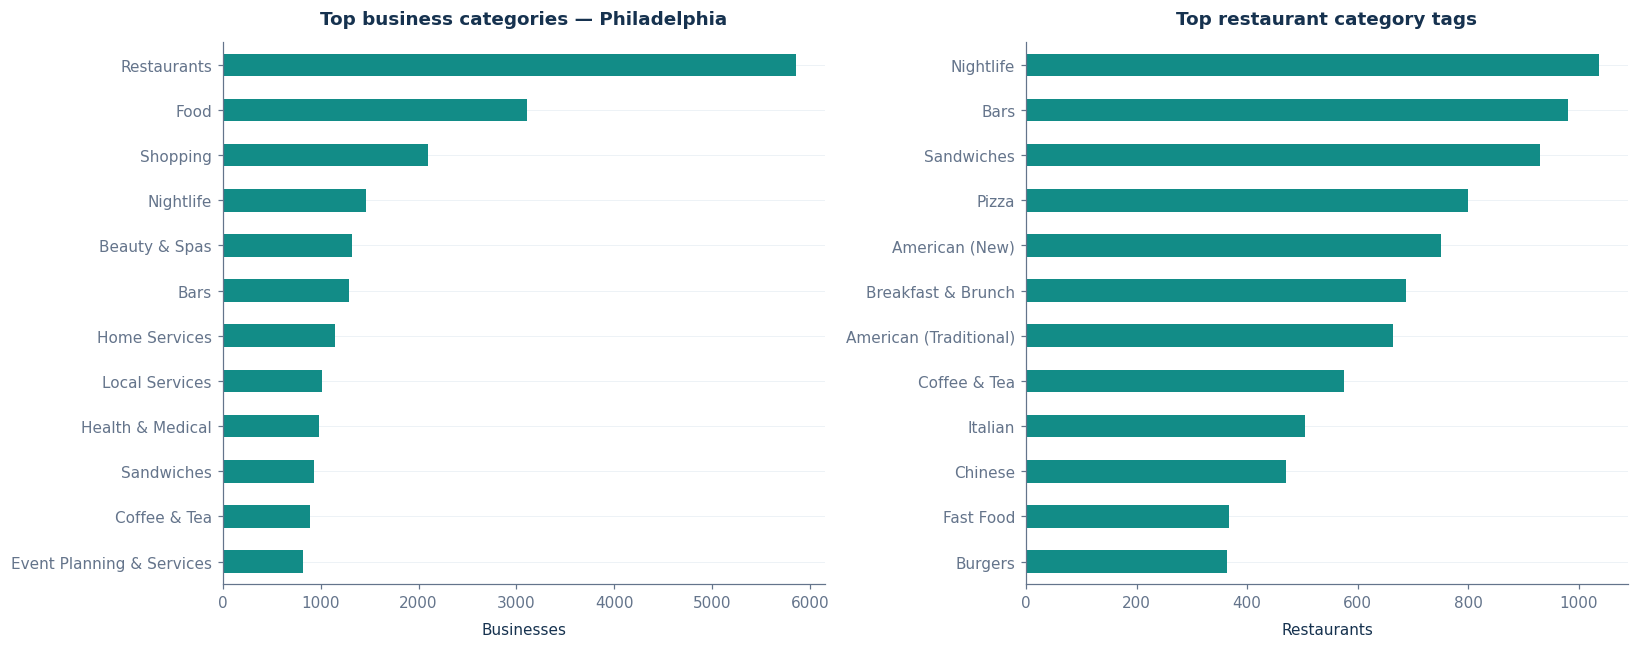

In [7]:
summary = pd.Series({
    'Philadelphia businesses': len(business), 'Philadelphia restaurants': len(restaurants),
    'Open restaurants': int(restaurants['is_open'].eq(1).sum()),
    'Median restaurant reviews': restaurants['review_count'].median(),
    'Mean restaurant rating': restaurants['stars'].mean()})
display(summary.to_frame('value'))
display(restaurants[['stars', 'review_count', 'latitude', 'longitude']].describe())

category_counts = pd.Series(Counter(c for cats in business['category_list'] for c in cats))
restaurant_categories = pd.Series(Counter(c for cats in restaurants['category_list'] for c in cats
                                         if c not in {'Restaurants', 'Food'}))
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
category_counts.nlargest(12).sort_values().plot.barh(ax=axes[0], color=THEME['teal'])
axes[0].set(title='Top business categories — Philadelphia', xlabel='Businesses')
restaurant_categories.nlargest(12).sort_values().plot.barh(ax=axes[1], color=THEME['teal'])
axes[1].set(title='Top restaurant category tags', xlabel='Restaurants')
plt.tight_layout(); plt.show()


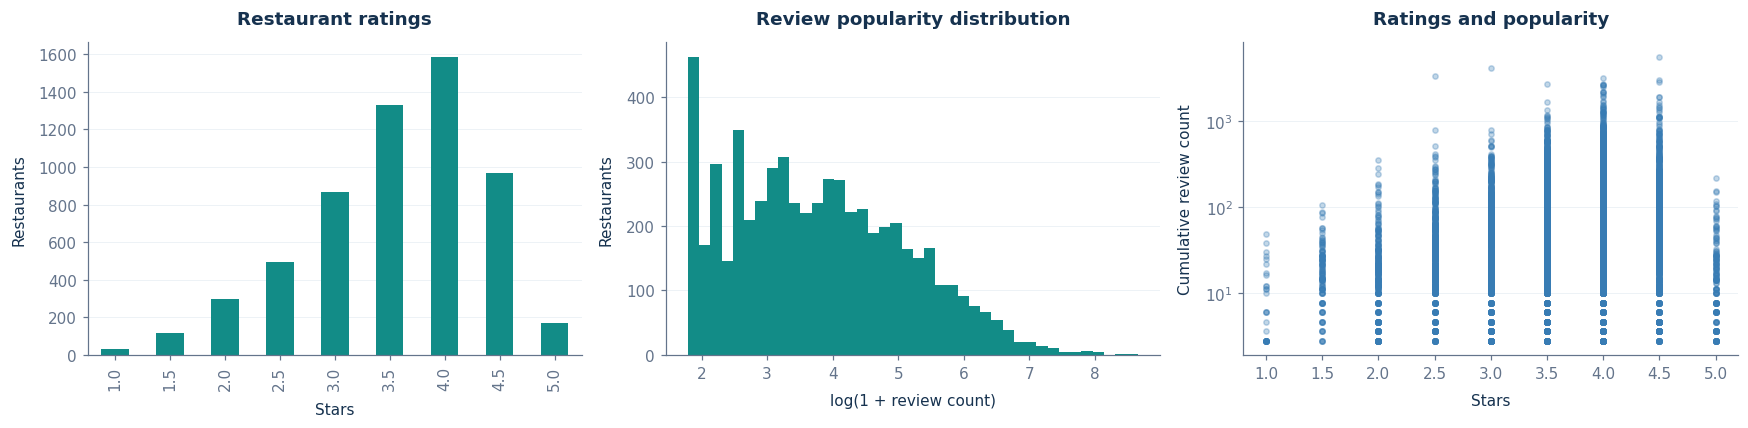

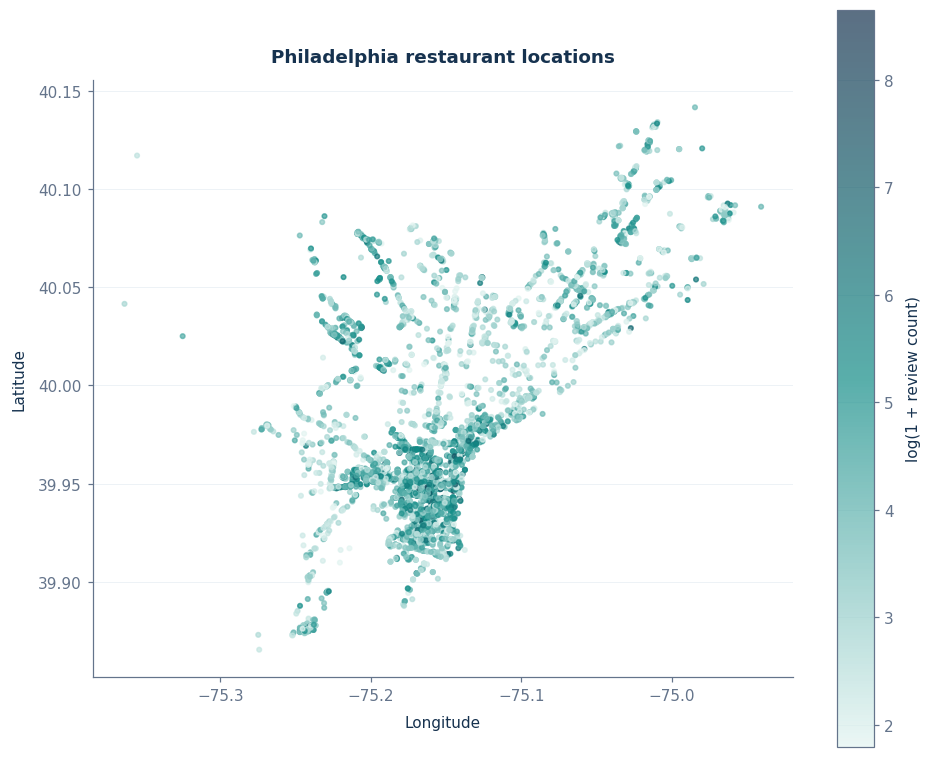

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
restaurants['stars'].dropna().value_counts().sort_index().plot.bar(ax=axes[0], color=THEME['teal'])
axes[0].set(title='Restaurant ratings', xlabel='Stars', ylabel='Restaurants')
axes[1].hist(np.log1p(restaurants['review_count']), bins=40, color=THEME['teal'])
axes[1].set(title='Review popularity distribution', xlabel='log(1 + review count)', ylabel='Restaurants')
axes[2].scatter(restaurants['stars'], restaurants['review_count'], s=12, alpha=.3, color=THEME['blue'])
axes[2].set(title='Ratings and popularity', xlabel='Stars', ylabel='Cumulative review count')
axes[2].set_yscale('symlog', linthresh=10)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
points = ax.scatter(restaurants['longitude'], restaurants['latitude'],
                    c=np.log1p(restaurants['review_count']), s=9, cmap=TEAL_CMAP, alpha=.7)
ax.set(title='Philadelphia restaurant locations', xlabel='Longitude', ylabel='Latitude')
ax.set_aspect(1 / np.cos(np.deg2rad(40)))
fig.colorbar(points, ax=ax, label='log(1 + review count)')
plt.tight_layout(); plt.show()


### Postal-code geography and restaurant status
Postal codes are a reproducible geographic grouping available in the business file; they are **not official neighborhood boundaries**. Category tags may overlap. These charts describe the dataset snapshot and do not rank profitability.


,restaurants,open_restaurants,median_reviews,mean_rating
postal_code,,,,
19107,590,323,77.0,3.67
19147,549,260,65.0,3.85
19103,481,240,69.0,3.66
19104,423,247,43.0,3.51
19106,301,139,59.0,3.61
19148,276,181,31.0,3.70
19123,232,130,53.0,3.69
19102,199,105,58.0,3.42
19130,174,104,76.5,3.70


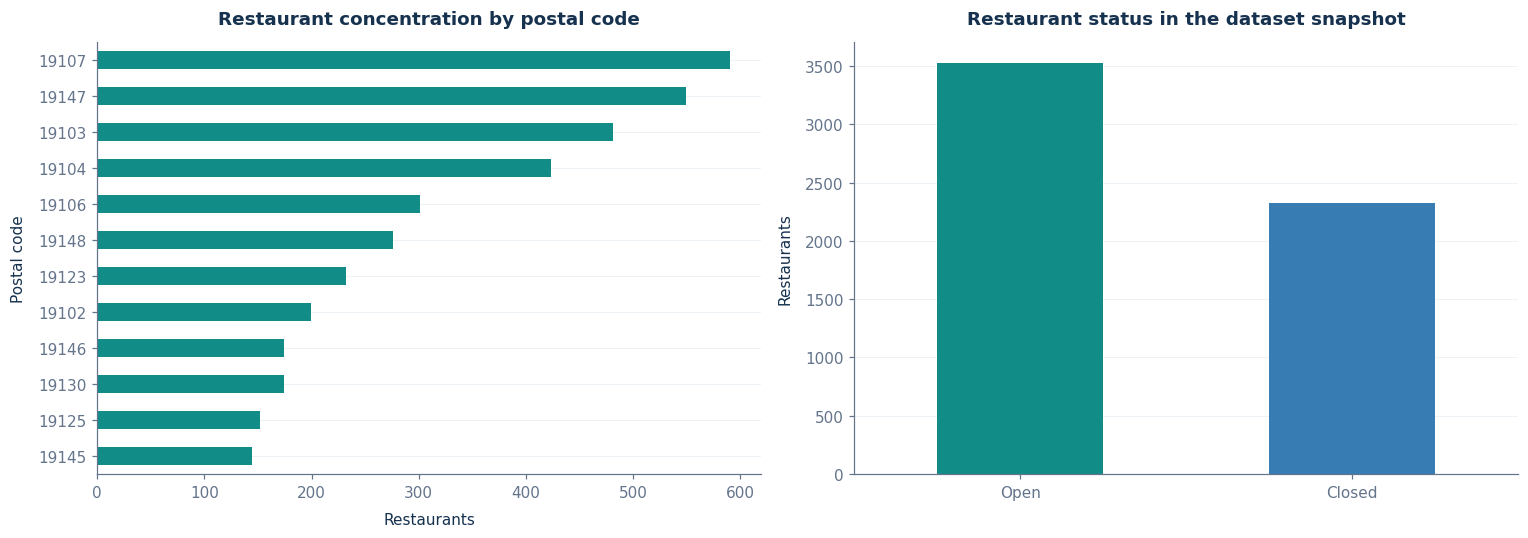

Highest restaurant concentration among postal codes: 19107
Review counts are cumulative; status does not date when a restaurant closed.


In [9]:
postal_summary = restaurants.groupby('postal_code', dropna=False).agg(
    restaurants=('business_id', 'size'), open_restaurants=('is_open', lambda s: int(s.eq(1).sum())),
    median_reviews=('review_count', 'median'), mean_rating=('stars', 'mean')).sort_values('restaurants', ascending=False)
display(postal_summary.head(15).round(2))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
postal_summary.head(12).sort_values('restaurants')['restaurants'].plot.barh(ax=axes[0], color=THEME['teal'])
axes[0].set(title='Restaurant concentration by postal code', xlabel='Restaurants', ylabel='Postal code')
status_counts = restaurants['is_open'].map({1: 'Open', 0: 'Closed'}).fillna('Unknown').value_counts()
status_counts.plot.bar(ax=axes[1], color=[THEME['teal'], THEME['blue'], THEME['muted']], rot=0)
axes[1].set(title='Restaurant status in the dataset snapshot', xlabel='', ylabel='Restaurants')
plt.show()
print('Highest restaurant concentration among postal codes:', postal_summary.index[0])
print('Review counts are cumulative; status does not date when a restaurant closed.')


### Business attributes, opening hours and Yelp age
Yelp attributes are stored as strings such as `'True'`, `u'full_bar'` or nested dictionaries. They are parsed into numeric features: service flags (take-out, delivery, reservations, outdoor seating …), alcohol level, noise level, Wi-Fi, any parking, and the number of attributes filled in. Opening hours give the number of open days, total weekly hours and late-night days (closing at 23:00 or later). Unknown values stay missing and are imputed from training data.

These are **own-business snapshot attributes** (like the rating); they describe the existing restaurant, not a pre-opening forecast.

,No,Yes
RestaurantsReservations,38.0,88.0
OutdoorSeating,37.0,85.0
RestaurantsDelivery,37.0,47.5
RestaurantsTakeOut,45.0,43.0
HappyHour,148.0,124.0
RestaurantsTableService,50.5,109.0


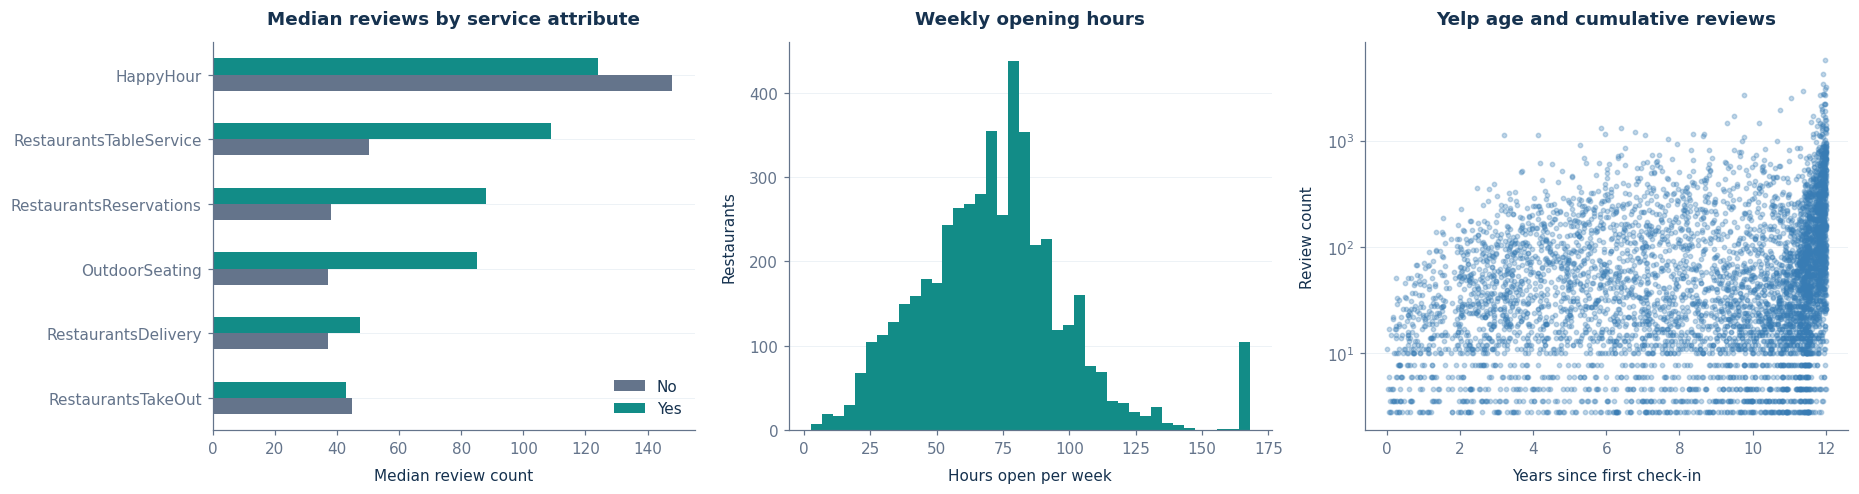

Spearman correlation with review count:


,spearman_rho
attribute_count,0.709
any_parking,0.468
level_Alcohol,0.336
years_since_first_checkin,0.298
attr_OutdoorSeating,0.273
attr_BikeParking,0.265
attr_RestaurantsTableService,0.247
attr_RestaurantsReservations,0.242
level_NoiseLevel,0.121
attr_RestaurantsGoodForGroups,0.102


In [10]:
BOOLEAN_ATTRIBUTES = ['RestaurantsTakeOut', 'RestaurantsDelivery', 'OutdoorSeating', 'RestaurantsReservations',
                      'RestaurantsGoodForGroups', 'GoodForKids', 'BusinessAcceptsCreditCards', 'HasTV',
                      'RestaurantsTableService', 'Caters', 'BikeParking', 'WheelchairAccessible', 'HappyHour']
LEVEL_ATTRIBUTES = {'Alcohol': {'none': 0, 'beer_and_wine': 1, 'full_bar': 2},
                    'NoiseLevel': {'quiet': 0, 'average': 1, 'loud': 2, 'very_loud': 3},
                    'WiFi': {'no': 0, 'paid': 1, 'free': 2}}

def clean_attribute_text(value):
    return str(value).strip().replace("u'", '').strip("'\"").lower()

def parse_boolean(value):
    text = clean_attribute_text(value)
    return 1. if text == 'true' else 0. if text == 'false' else np.nan

def parse_parking(value):
    try:
        parking = ast.literal_eval(str(value))
    except (ValueError, SyntaxError):
        return np.nan
    return float(any(bool(v) for v in parking.values())) if isinstance(parking, dict) else np.nan

def parse_hours(hours):
    """Return (open days, weekly open hours, late-night days) from Yelp's {'Monday': '11:0-22:0'} format."""
    if not isinstance(hours, dict) or not hours:
        return np.nan, np.nan, np.nan
    total, late = 0., 0
    for span in hours.values():
        try:
            start, end = span.split('-')
            start_h, start_m = map(int, start.split(':'))
            end_h, end_m = map(int, end.split(':'))
        except (ValueError, AttributeError):
            continue
        opens, closes = start_h + start_m / 60, end_h + end_m / 60
        if closes <= opens:  # closes after midnight, or '0:0-0:0' meaning open all day
            closes += 24
        total += closes - opens
        late += int(closes >= 23)
    return float(len(hours)), total, float(late)

def business_profile_features(frame):
    attributes = frame['attributes']
    result = pd.DataFrame(index=frame.index)
    result['attribute_count'] = attributes.map(len)
    for name in BOOLEAN_ATTRIBUTES:
        result[f'attr_{name}'] = attributes.map(lambda d: parse_boolean(d[name]) if name in d else np.nan)
    for name, mapping in LEVEL_ATTRIBUTES.items():
        result[f'level_{name}'] = attributes.map(
            lambda d: mapping.get(clean_attribute_text(d.get(name)), np.nan))
    result['any_parking'] = attributes.map(lambda d: parse_parking(d.get('BusinessParking')))
    hours = frame['hours'] if 'hours' in frame else pd.Series([None] * len(frame), index=frame.index)
    result[['days_open', 'hours_per_week', 'late_night_days']] = pd.DataFrame(
        hours.map(parse_hours).tolist(), index=frame.index)
    return result

profile = business_profile_features(restaurants)
profile_eda = pd.concat([profile, restaurants[['review_count', 'years_since_first_checkin']]], axis=1)
flag_effect = pd.DataFrame({
    name.replace('attr_', ''): profile_eda.groupby(f'{name}')['review_count'].median()
    for name in [f'attr_{n}' for n in ['RestaurantsReservations', 'OutdoorSeating', 'RestaurantsDelivery',
                                       'RestaurantsTakeOut', 'HappyHour', 'RestaurantsTableService']]}).T
flag_effect.columns = ['No', 'Yes']
display(flag_effect.round(1))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
flag_effect.sort_values('Yes').plot.barh(ax=axes[0], color=[THEME['muted'], THEME['teal']])
axes[0].set(title='Median reviews by service attribute', xlabel='Median review count', ylabel='')
axes[1].hist(profile['hours_per_week'].dropna().clip(upper=168), bins=40, color=THEME['teal'])
axes[1].set(title='Weekly opening hours', xlabel='Hours open per week', ylabel='Restaurants')
axes[2].scatter(profile_eda['years_since_first_checkin'], profile_eda['review_count'], s=8, alpha=.3, color=THEME['blue'])
axes[2].set_yscale('symlog', linthresh=10)
axes[2].set(title='Yelp age and cumulative reviews', xlabel='Years since first check-in', ylabel='Review count')
plt.show()
print('Spearman correlation with review count:')
display(profile_eda.drop(columns='review_count').corrwith(profile_eda['review_count'], method='spearman')
        .sort_values(ascending=False).round(3).to_frame('spearman_rho').head(12))


## M1-4. Geographic train / validation / test split
Approximately 60% / 20% / 20% of **spatial blocks** are assigned to train / validation / test, so row percentages may differ. Blocks are roughly 1 km in latitude and longitude around Philadelphia. Restaurants in the same block stay together; adjacent blocks can still be close, so this is not a buffered geographic holdout.

Review-count aggregates use **training restaurants only** for every split. A restaurant's own record is always excluded by ID. This avoids held-out target leakage. Competitor counts use all restaurant coordinates in the known Philadelphia catalog (a transductive setting); this assumes the catalog is available at scoring time.

Model tuning additionally uses three-fold GroupKFold within training blocks only. Category vocabularies, imputation, scaling and model fitting are rebuilt for each fold. The catalog coordinates are assumed known; its target values never enter predictors.


In [11]:
lat_block = np.floor((restaurants['latitude'] - 39.8) / .009).astype(int)
lon_block = np.floor((restaurants['longitude'] + 75.4) / .012).astype(int)
groups = lat_block.astype(str) + '_' + lon_block.astype(str)
if groups.nunique() < 10:
    raise ValueError('Need at least 10 spatial blocks for this split.')
splitter = GroupShuffleSplit(n_splits=1, test_size=.2, random_state=SEED)
train_val_idx, test_idx = next(splitter.split(restaurants, groups=groups))
splitter_val = GroupShuffleSplit(n_splits=1, test_size=.25, random_state=SEED + 1)
train_local, val_local = next(splitter_val.split(restaurants.iloc[train_val_idx],
                                                groups=groups.iloc[train_val_idx]))
train_idx, val_idx = train_val_idx[train_local], train_val_idx[val_local]
assert not (set(groups.iloc[train_idx]) & set(groups.iloc[val_idx]))
assert not (set(groups.iloc[train_idx]) & set(groups.iloc[test_idx]))
assert not (set(groups.iloc[val_idx]) & set(groups.iloc[test_idx]))
assert min(len(train_idx), len(val_idx), len(test_idx)) >= 2
split_labels = pd.Series('train', index=restaurants.index)
split_labels.iloc[val_idx] = 'validation'
split_labels.iloc[test_idx] = 'test'
display(pd.DataFrame({'rows': split_labels.value_counts(),
                      'percent': split_labels.value_counts(normalize=True).mul(100).round(1)}))


,rows,percent
train,3585,61.2
test,1159,19.8
validation,1111,19.0


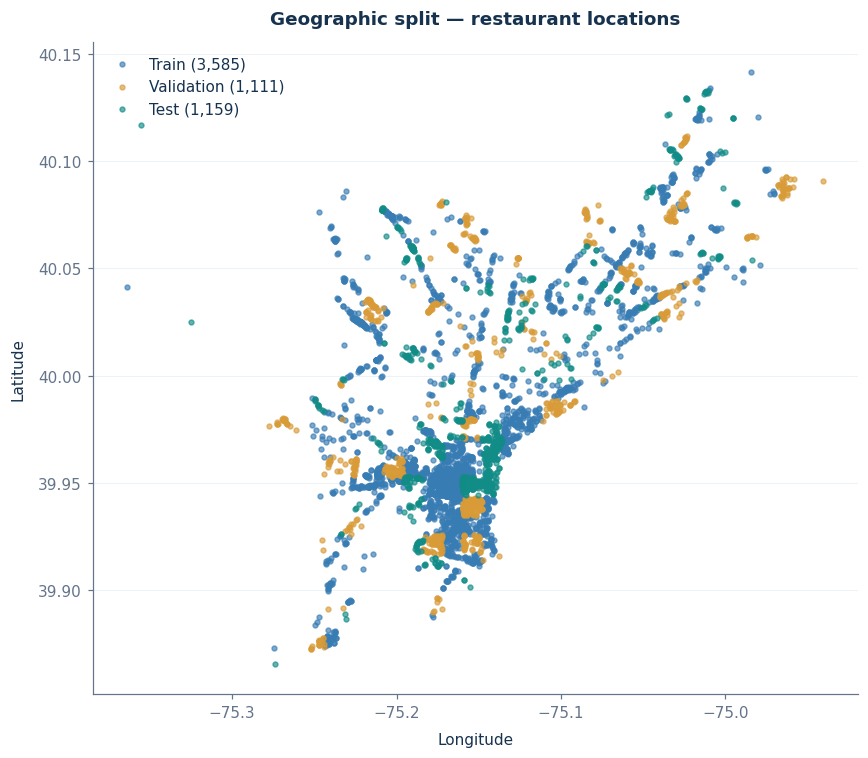

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))
for split, color in SPLIT_COLORS.items():
    mask = split_labels.eq(split)
    ax.scatter(restaurants.loc[mask, 'longitude'], restaurants.loc[mask, 'latitude'],
               s=10, alpha=.65, color=color, label=f'{split.title()} ({int(mask.sum()):,})')
ax.set(title='Geographic split — restaurant locations', xlabel='Longitude', ylabel='Latitude')
ax.set_aspect(1 / np.cos(np.deg2rad(40)))
ax.legend(loc='best')
plt.show()


## M1-5. Location and business feature engineering
Distances use a BallTree with the haversine metric: latitude/longitude are converted to radians and radii from km to radians. A competitor is another Philadelphia business tagged `Restaurants`, whether open or closed; open competitors are also counted separately. These counts are a broad competition proxy rather than same-cuisine competition.

Features: competitor counts at 0.5, 1 and 2 km; density per km² at 1 km; open competitors; mean nearby rating; mean/sum nearby cumulative reviews from training reference restaurants; reference-neighbor count; distance to Philadelphia City Hall; latitude/longitude, own rating, open status, price range, category count, and 20 restaurant tags selected from training data only. No own review count, ID or business name enters the predictors.

All neighbor features are restricted to Philadelphia. Counts near the city edge are therefore incomplete for cross-boundary competition.

**Audit correction:** nearby cumulative review sums/means, training-reference neighbor count and the catalog-wide neighboring rating mean are excluded from regression. They remain useful descriptive features. The model uses only location geometry, own snapshot attributes and training-selected category indicators. Own rating is permitted for existing-business snapshot estimates; it is unavailable for a true pre-opening forecast.

**Enhancement:** the feature set is extended with (1) the parsed attributes and opening hours above, (2) the Yelp-age proxies `years_since_first_checkin` and `checkin_active_years`, and (3) `nearby_checkin_mean_0p5km` / `nearby_checkin_mean_1km`, the mean log(1 + check-ins) of *other* restaurants nearby. Check-ins are a separate visit signal, not the review-count target, so — like competitor counts — they are computed over the full catalog with the focal restaurant excluded by ID. A restaurant's own check-in count is never a predictor.


In [13]:
def safe_price(attributes):
    value = attributes.get('RestaurantsPriceRange2')
    try:
        price = float(str(value).strip("'\""))
        return price if price in {1, 2, 3, 4} else np.nan
    except (ValueError, TypeError):
        return np.nan

train_reference = restaurants.iloc[train_idx].copy().reset_index(drop=True)
tag_counts_train = Counter(tag for tags in train_reference['category_list'] for tag in tags
                           if tag not in {'Restaurants', 'Food'})
TOP_TAGS = [tag for tag, count in tag_counts_train.most_common(20)]

def engineer_location_features(query, catalog, review_reference, top_tags):
    query = query.reset_index(drop=True)
    catalog = catalog.reset_index(drop=True)
    reference = review_reference.reset_index(drop=True)
    q_coords = np.radians(query[['latitude', 'longitude']].to_numpy(dtype=float))
    catalog_tree = BallTree(np.radians(catalog[['latitude', 'longitude']].to_numpy()), metric='haversine')
    ref_tree = BallTree(np.radians(reference[['latitude', 'longitude']].to_numpy()), metric='haversine')
    result = query[['latitude', 'longitude', 'stars', 'is_open']].copy()
    result['price_range'] = query['attributes'].map(safe_price)
    result['category_count'] = query['category_list'].map(len)
    q_ids = query['business_id'].to_numpy()
    catalog_ids = catalog['business_id'].to_numpy()
    for radius in [.5, 1., 2.]:
        neighbors = catalog_tree.query_radius(q_coords, r=radius / EARTH_RADIUS_KM)
        other_neighbors = [idx[catalog_ids[idx] != q_ids[i]] for i, idx in enumerate(neighbors)]
        suffix = str(radius).replace('.', 'p')
        result[f'competitors_{suffix}km'] = [len(idx) for idx in other_neighbors]
        if radius == 1.:
            result['open_competitors_1km'] = [int(catalog.iloc[idx]['is_open'].eq(1).sum())
                                              for idx in other_neighbors]
            result['nearby_rating_mean_1km'] = [catalog.iloc[idx]['stars'].mean()
                                               for idx in other_neighbors]
    result['competitor_density_1km'] = result['competitors_1p0km'] / np.pi
    if 'checkin_count' in catalog:
        catalog_activity = np.log1p(catalog['checkin_count'].to_numpy(dtype=float))
        for radius in [.5, 1.]:
            neighbors = catalog_tree.query_radius(q_coords, r=radius / EARTH_RADIUS_KM)
            others = [idx[catalog_ids[idx] != q_ids[i]] for i, idx in enumerate(neighbors)]
            suffix = str(radius).replace('.', 'p')
            result[f'nearby_checkin_mean_{suffix}km'] = [catalog_activity[idx].mean() if len(idx) else np.nan
                                                         for idx in others]
    ref_ids = reference['business_id'].to_numpy()
    ref_neighbors = ref_tree.query_radius(q_coords, r=1. / EARTH_RADIUS_KM)
    other_ref = [idx[ref_ids[idx] != q_ids[i]] for i, idx in enumerate(ref_neighbors)]
    result['reference_neighbors_1km'] = [len(idx) for idx in other_ref]
    result['nearby_review_mean_1km'] = [reference.iloc[idx]['review_count'].mean() for idx in other_ref]
    result['nearby_review_sum_1km'] = [reference.iloc[idx]['review_count'].sum() for idx in other_ref]
    # Philadelphia City Hall: an approximate centrality reference, not a fitted coordinate.
    center_lat, center_lon = np.radians([39.9526, -75.1636])
    delta_lat, delta_lon = q_coords[:, 0] - center_lat, q_coords[:, 1] - center_lon
    a = np.sin(delta_lat / 2)**2 + np.cos(q_coords[:, 0]) * np.cos(center_lat) * np.sin(delta_lon / 2)**2
    result['distance_city_hall_km'] = 2 * EARTH_RADIUS_KM * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
    for column in ['years_since_first_checkin', 'checkin_active_years']:
        if column in query:
            result[column] = query[column].to_numpy()
    result = pd.concat([result, business_profile_features(query).reset_index(drop=True)], axis=1)
    for tag in top_tags:
        result[f'tag__{tag}'] = query['category_list'].map(lambda tags: int(tag in tags))
    return result

X = engineer_location_features(restaurants, restaurants, train_reference, TOP_TAGS)
y = restaurants['review_count'].astype(float)
assert 'review_count' not in X and 'business_id' not in X and 'checkin_count' not in X
assert np.isfinite(X.dropna().to_numpy()).all()
display(X.head())


,latitude,longitude,stars,is_open,price_range,category_count,competitors_0p5km,competitors_1p0km,open_competitors_1km,nearby_rating_mean_1km,competitors_2p0km,competitor_density_1km,nearby_checkin_mean_0p5km,nearby_checkin_mean_1p0km,reference_neighbors_1km,...,tag__Breakfast & Brunch,tag__American (Traditional),tag__Coffee & Tea,tag__Chinese,tag__Italian,tag__Fast Food,tag__Burgers,tag__Seafood,tag__Cafes,tag__Mexican,tag__Event Planning & Services,tag__Salad,tag__Delis,tag__Specialty Food,tag__Bakeries
0,39.955505,-75.155564,4.0,1.0,1.0,5,265,748,406,3.649733,2302,238.095795,4.843852,4.499090,482,...,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1
1,39.953949,-75.143226,4.0,1.0,2.0,3,98,348,165,3.622126,1589,110.771840,4.301459,4.281712,21,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,39.943223,-75.162568,4.5,1.0,1.0,2,120,886,418,3.698081,2387,282.022559,4.569447,4.508647,539,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,39.939825,-75.157447,4.0,0.0,2.0,5,195,612,271,3.806373,2290,194.805650,4.035192,4.196520,243,...,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
4,40.022466,-75.218314,3.0,0.0,1.0,4,53,127,61,3.673228,201,40.425356,3.956313,3.892120,112,...,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


### Feature dictionary and correctness checks
Zero nearby competitors is a valid count. A missing nearby mean indicates no eligible neighbors (or no valid neighbor rating); it is imputed using training rows only. The review reference is fixed to training restaurants. Density divides the 1 km competitor count by π km². The count radii must be monotonic.

The small controlled example checks exclusion by business ID: a different restaurant at the same coordinates must still count as a competitor. It also verifies that a focal restaurant's own reviews do not enter its nearby mean or sum.


In [14]:
descriptions = {
    'latitude': ('degrees', 'Restaurant latitude'),
    'longitude': ('degrees', 'Restaurant longitude'),
    'stars': ('1–5 stars', 'Own snapshot Yelp rating; unavailable for a true cold start'),
    'is_open': ('0 / 1', 'Closed / open at dataset snapshot'),
    'price_range': ('1–4', 'RestaurantsPriceRange2; missing values imputed from training'),
    'category_count': ('tags', 'Number of distinct business category tags'),
    'competitors_0p5km': ('restaurants', 'Other Philadelphia restaurants within 0.5 km'),
    'competitors_1p0km': ('restaurants', 'Other Philadelphia restaurants within 1 km'),
    'competitors_2p0km': ('restaurants', 'Other Philadelphia restaurants within 2 km'),
    'open_competitors_1km': ('restaurants', 'Other open Philadelphia restaurants within 1 km'),
    'nearby_rating_mean_1km': ('stars', 'Mean rating of other catalog restaurants within 1 km'),
    'competitor_density_1km': ('restaurants/km²', 'Competitors within 1 km divided by π'),
    'reference_neighbors_1km': ('restaurants', 'Eligible training-reference neighbors within 1 km'),
    'nearby_review_mean_1km': ('cumulative reviews', 'Mean review count over eligible training-reference neighbors'),
    'nearby_review_sum_1km': ('cumulative reviews', 'Sum of review counts over eligible training-reference neighbors'),
    'distance_city_hall_km': ('km', 'Haversine distance to Philadelphia City Hall'),
    'nearby_checkin_mean_0p5km': ('log check-ins', 'Mean log(1 + check-ins) of other restaurants within 0.5 km'),
    'nearby_checkin_mean_1p0km': ('log check-ins', 'Mean log(1 + check-ins) of other restaurants within 1 km'),
    'years_since_first_checkin': ('years', 'Snapshot date minus first check-in (Yelp-age proxy)'),
    'checkin_active_years': ('years', 'Last minus first check-in'),
    'attribute_count': ('attributes', 'Number of Yelp attributes filled in'),
    'level_Alcohol': ('0–2', 'none / beer and wine / full bar'),
    'level_NoiseLevel': ('0–3', 'quiet / average / loud / very loud'),
    'level_WiFi': ('0–2', 'no / paid / free'),
    'any_parking': ('0 / 1', 'Any BusinessParking option available'),
    'days_open': ('days', 'Days with listed opening hours'),
    'hours_per_week': ('hours', 'Total listed opening hours per week'),
    'late_night_days': ('days', 'Days closing at 23:00 or later')}
descriptions.update({f'attr_{name}': ('0 / 1', f'Yelp attribute {name}') for name in BOOLEAN_ATTRIBUTES})
feature_dictionary = pd.DataFrame([
    {'feature': col, 'unit': descriptions.get(col, ('0 / 1', 'Training-selected category-tag indicator'))[0],
     'definition': descriptions.get(col, ('0 / 1', 'Training-selected category-tag indicator'))[1]}
    for col in X.columns])
display(feature_dictionary)
display(X.isna().sum().loc[lambda s: s.gt(0)].rename('missing_values').to_frame())
assert (X['competitors_0p5km'] <= X['competitors_1p0km']).all()
assert (X['competitors_1p0km'] <= X['competitors_2p0km']).all()
assert (X['open_competitors_1km'] <= X['competitors_1p0km']).all()
np.testing.assert_allclose(X['competitor_density_1km'], X['competitors_1p0km'] / np.pi)
fixture = pd.DataFrame({
    'business_id': ['A', 'B', 'C'], 'latitude': [39.95, 39.95, 40.10],
    'longitude': [-75.16, -75.16, -75.16], 'stars': [4., 3., 5.], 'is_open': [1, 1, 0],
    'review_count': [10, 20, 30], 'attributes': [{}, {}, {}],
    'category_list': [['Restaurants'], ['Restaurants'], ['Restaurants']]})
fixture_X = engineer_location_features(fixture, fixture, fixture, [])
assert fixture_X.loc[0, 'competitors_1p0km'] == 1  # B counts even though co-located with A.
assert fixture_X.loc[0, 'nearby_review_sum_1km'] == 20  # A's own 10 reviews excluded.
assert fixture_X.loc[0, 'nearby_review_mean_1km'] == 20
assert fixture_X.loc[2, 'competitors_1p0km'] == 0
assert np.isnan(fixture_X.loc[2, 'nearby_review_mean_1km'])
print('Passed: radius monotonicity, density, open counts, co-location, self exclusion, and no-neighbor behavior.')


,feature,unit,definition
0,latitude,degrees,Restaurant latitude
1,longitude,degrees,Restaurant longitude
2,stars,1–5 stars,Own snapshot Yelp rating; unavailable for a tr...
3,is_open,0 / 1,Closed / open at dataset snapshot
4,price_range,1–4,RestaurantsPriceRange2; missing values imputed...
...,...,...,...
56,tag__Event Planning & Services,0 / 1,Training-selected category-tag indicator
57,tag__Salad,0 / 1,Training-selected category-tag indicator
58,tag__Delis,0 / 1,Training-selected category-tag indicator
59,tag__Specialty Food,0 / 1,Training-selected category-tag indicator


,missing_values
price_range,914
nearby_rating_mean_1km,8
nearby_checkin_mean_0p5km,40
nearby_checkin_mean_1p0km,8
nearby_review_mean_1km,97
years_since_first_checkin,200
checkin_active_years,200
attr_RestaurantsTakeOut,514
attr_RestaurantsDelivery,772
attr_OutdoorSeating,1148


Passed: radius monotonicity, density, open counts, co-location, self exclusion, and no-neighbor behavior.


Passed: validation/test-target perturbation does not change features.


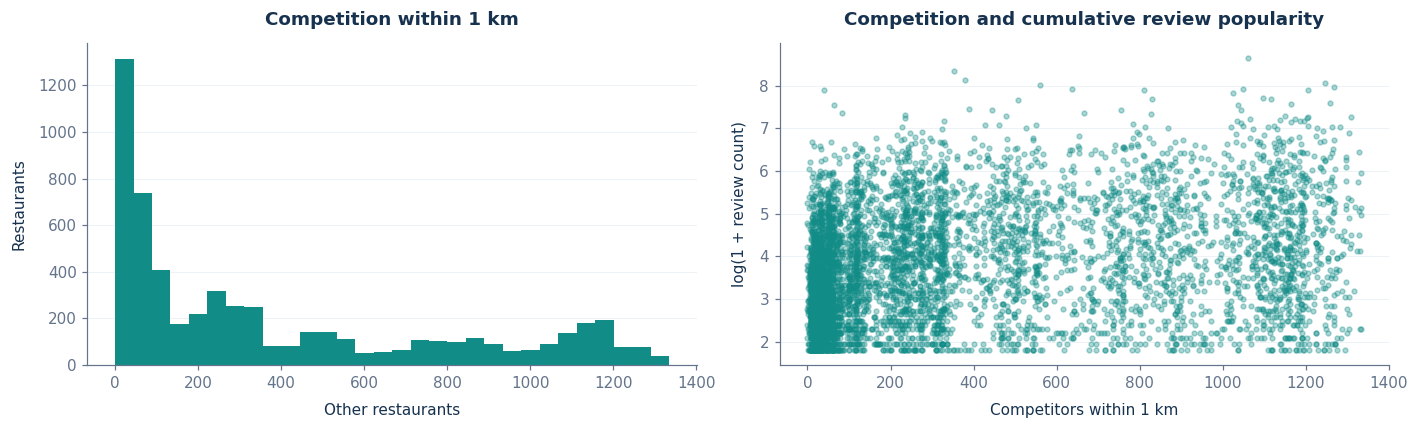

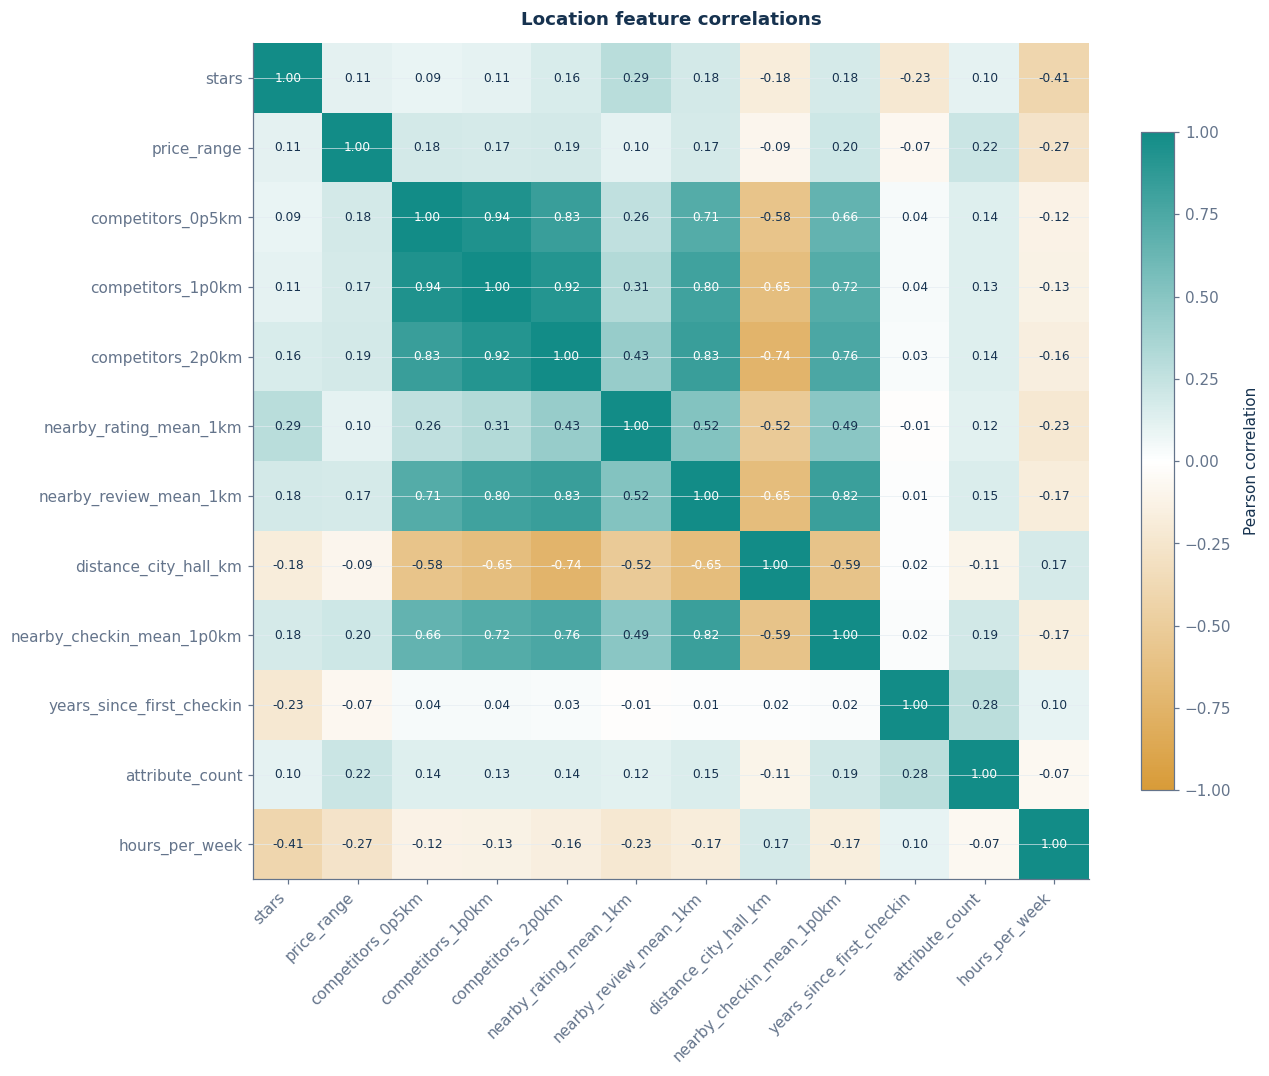

In [15]:
# A held-out target perturbation must not change any predictors.
changed = restaurants.copy()
heldout_idx = np.concatenate([val_idx, test_idx])
changed.loc[heldout_idx, 'review_count'] = changed.loc[heldout_idx, 'review_count'] + 99999
check_X = engineer_location_features(changed, changed, train_reference, TOP_TAGS)
pd.testing.assert_frame_equal(X, check_X)
print('Passed: validation/test-target perturbation does not change features.')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(X['competitors_1p0km'], bins=30, color=THEME['teal'])
axes[0].set(title='Competition within 1 km', xlabel='Other restaurants', ylabel='Restaurants')
axes[1].scatter(X['competitors_1p0km'], np.log1p(y), s=10, alpha=.35, color=THEME['teal'])
axes[1].set(title='Competition and cumulative review popularity', xlabel='Competitors within 1 km',
            ylabel='log(1 + review count)')
plt.tight_layout(); plt.show()
correlation_columns = ['stars', 'price_range', 'competitors_0p5km', 'competitors_1p0km',
                       'competitors_2p0km', 'nearby_rating_mean_1km',
                       'nearby_review_mean_1km', 'distance_city_hall_km', 'nearby_checkin_mean_1p0km',
                       'years_since_first_checkin', 'attribute_count', 'hours_per_week']
correlation = X[correlation_columns].corr()
fig, ax = plt.subplots(figsize=(12, 10))
diverging = LinearSegmentedColormap.from_list('philly_correlation',
                                             [THEME['gold'], '#FFFFFF', THEME['teal']])
heat = ax.imshow(correlation, cmap=diverging, vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation_columns)), correlation_columns, rotation=45, ha='right')
ax.set_yticks(range(len(correlation_columns)), correlation_columns)
for row in range(len(correlation_columns)):
    for col in range(len(correlation_columns)):
        val = correlation.iloc[row, col]
        ax.text(col, row, f'{val:.2f}', ha='center', va='center',
                color='white' if abs(val) > .6 else THEME['navy'], fontsize=8)
ax.set_title('Location feature correlations')
ax.grid(False)
fig.colorbar(heat, ax=ax, label='Pearson correlation', shrink=.75)
plt.show()


## M1-6. Regression audit, regularization and spatial cross-validation
The original candidates are rerun on training and validation data to measure their generalization gaps. A large train/validation gap on log-scale MAE or R² indicates possible overfitting; a gap alone is not proof because geographic target distributions differ.

The revised Random Forest candidates have capped depth and larger leaves; Gradient Boosting uses shallow trees, smaller learning rates and larger leaves. For each family, three-fold spatial CV on training blocks selects the candidate with the lowest mean MAE in original review units. A standard Linear Regression and median baseline remain comparators. Each CV fold selects its own top category vocabulary and fits its own imputer/scaler. The model family is then selected by validation MAE. No test scores guide these choices.

The `log1p` target transform and non-negative clipping are retained. The fitted models estimate existing-business cumulative review popularity, not revenue or future popularity. Training-reference labels are not predictors.

`HistGradientBoostingRegressor` (histogram-based gradient boosting, the scikit-learn analogue of LightGBM) is added as a fourth family with three regularized candidates (few leaves, large minimum leaf size, L2 penalty). The "original" audit rows below re-create the earlier location-only notebook so the effect of the enhancements can be compared directly.

### Earlier audit (original location-only model)
The complete notebook was rerun successfully on the uploaded business ZIP. It contains **14,570 cleaned Philadelphia businesses** and **5,855 restaurants**. The original spatial split is retained: **3,585 training**, **1,111 validation** and **1,159 test** restaurants.

**Finding:** the original Random Forest showed a large log-scale train/validation gap (log R² **0.807 vs 0.234**). No direct held-out target leakage was found by the existing checks. To strengthen isolation, regression now excludes target-derived nearby review mean/sum, training-reference neighbor count and catalog-wide nearby rating mean; these remain descriptive EDA features.

**Fixes:** three-fold spatial CV on training blocks, fold-local category vocabulary and preprocessing, capped tree depths and larger leaf sizes. Revised Random Forest settings: **150 trees, max depth 6, minimum leaf size 20, max features 0.7**. Its log-MAE gap fell from **0.384 to -0.007**; log R² is now **0.358 train vs 0.206 validation**. CV still has a modest training advantage, so reduced overfitting is not a guarantee of universal generalization.

**Selection:** Random Forest remains selected by validation MAE (**58.54 reviews**); Gradient Boosting is nearly tied (**58.63**), so this is not strong evidence of a uniquely best family. Revised original-test results: **MAE 91.18**, **RMSE 221.61**, **R² 0.059**. MAE is **8.3%** lower than the median baseline. Predictive strength remains limited.

**Disclosure:** the original test set was already viewed. These test scores are a descriptive re-evaluation; they are not an untouched independent benchmark. No revised choices are selected using test metrics. All implemented leakage assertions and saved-model prediction checks passed. The Streamlit source compiles; its browser UI was not launched. No review JSON was used, and no temporal forecasting claim is made.


### Evaluation disclosure
Original models are rerun to measure training and validation errors. All revised hyperparameter choices use spatial cross-validation on the original training blocks; validation selects the model family. Review-count-based neighborhood features remain in the EDA/handoff table but are excluded from regression.

**Evaluation disclosure:** the original test set was already viewed in earlier versions. Revised test results are a descriptive re-evaluation, not a newly untouched independent test. No revised parameters or feature choices are selected using test metrics. A future independent or prospective dataset is needed for an unbiased final assessment.


,model,split,MAE,RMSE,R2,log_MAE,log_R2
0,Median baseline,train,107.059,277.828,-0.094,1.124,-0.004
1,Median baseline,validation,65.541,155.701,-0.050,1.036,-0.046
2,Linear Regression,train,93.922,248.052,0.128,0.899,0.313
3,Linear Regression,validation,64.379,144.352,0.097,0.914,0.089
4,Random Forest,train,60.199,204.065,0.410,0.460,0.807
5,Random Forest,validation,57.263,141.144,0.137,0.844,0.235
6,Gradient Boosting,train,86.163,236.816,0.205,0.800,0.455
7,Gradient Boosting,validation,57.702,142.200,0.124,0.841,0.243
8,HistGradientBoosting,train,67.864,200.525,0.430,0.595,0.690
9,HistGradientBoosting,validation,58.953,141.462,0.133,0.849,0.221


,model,candidate,CV_MAE,CV_MAE_std,CV_RMSE,train_log_MAE,validation_log_MAE
0,Gradient Boosting,0,78.976,17.404,238.425,0.659,0.678
1,Gradient Boosting,1,74.595,16.527,230.780,0.606,0.634
2,Gradient Boosting,2,70.076,15.203,220.850,0.559,0.593
3,HistGradientBoosting,0,61.988,13.897,196.115,0.307,0.507
4,HistGradientBoosting,1,62.114,13.138,201.293,0.417,0.513
5,HistGradientBoosting,2,62.337,13.483,198.260,0.389,0.514
6,Linear Regression,0,66.712,12.309,210.221,0.566,0.589
7,Median baseline,0,107.107,20.193,275.620,1.124,1.125
8,Random Forest,0,68.368,14.406,211.830,0.526,0.580
9,Random Forest,1,68.494,14.144,213.075,0.524,0.579


,MAE,RMSE,R2
model,,,
HistGradientBoosting,37.378,101.062,0.557
Random Forest,39.877,108.022,0.494
Linear Regression,41.591,117.942,0.397
Gradient Boosting,42.324,116.096,0.416
Median baseline,65.541,155.701,-0.050


Selected by validation MAE: HistGradientBoosting
Training-CV selected parameters: {'learning_rate': 0.04, 'max_iter': 400, 'max_leaf_nodes': 15, 'min_samples_leaf': 30, 'l2_regularization': 1.0}


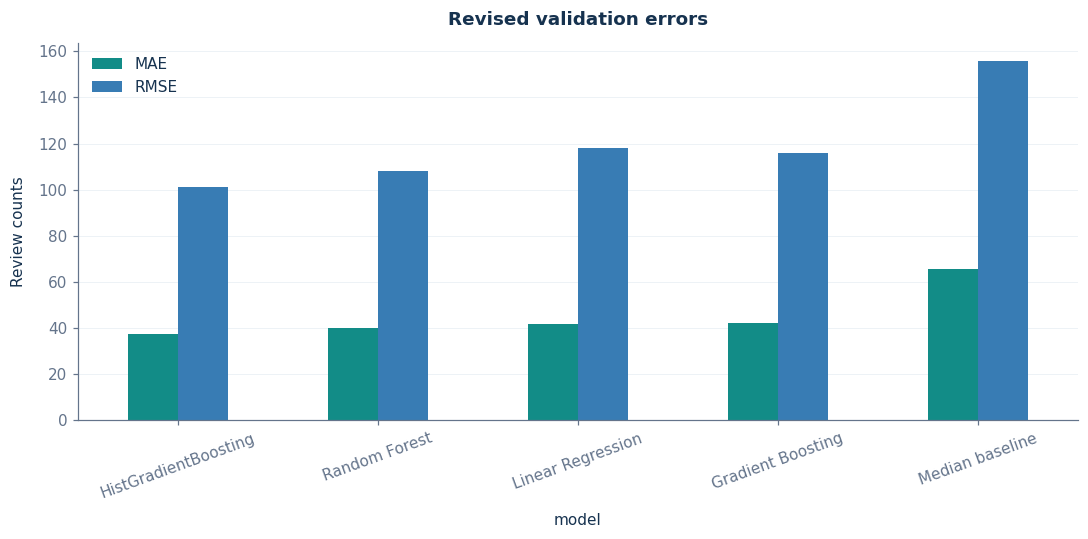

In [16]:
def metrics(actual, prediction):
    return {'MAE': float(mean_absolute_error(actual, prediction)),
            'RMSE': float(np.sqrt(mean_squared_error(actual, prediction))),
            'R2': float(r2_score(actual, prediction))}

def predict_counts(model, features):
    return np.maximum(model.predict(features), 0)

def make_regression_pipeline(estimator):
    return TransformedTargetRegressor(
        regressor=Pipeline([('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                            ('scale', StandardScaler()), ('regressor', estimator)]),
        func=np.log1p, inverse_func=np.expm1)

def log_metrics(actual, prediction):
    return {'log_MAE': float(mean_absolute_error(np.log1p(actual), np.log1p(prediction))),
            'log_R2': float(r2_score(np.log1p(actual), np.log1p(prediction)))}

# The earlier notebook used only location/competition, own rating/price/status and category tags.
ORIGINAL_COLUMNS = ['latitude', 'longitude', 'stars', 'is_open', 'price_range', 'category_count',
                    'competitors_0p5km', 'competitors_1p0km', 'open_competitors_1km', 'nearby_rating_mean_1km',
                    'competitors_2p0km', 'competitor_density_1km', 'reference_neighbors_1km',
                    'nearby_review_mean_1km', 'nearby_review_sum_1km', 'distance_city_hall_km'] + \
                   [col for col in X.columns if col.startswith('tag__')]
original_estimators = {
    'Median baseline': DummyRegressor(strategy='median'),
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                           max_features=.8, n_jobs=-1, random_state=SEED),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=200, learning_rate=.05,
                                                   max_depth=3, random_state=SEED),
    'HistGradientBoosting': HistGradientBoostingRegressor(random_state=SEED)}
original_rows = []
for name, estimator in original_estimators.items():
    original_model = make_regression_pipeline(estimator)
    original_model.fit(X[ORIGINAL_COLUMNS].iloc[train_idx], y.iloc[train_idx])
    for split_name, indices in [('train', train_idx), ('validation', val_idx)]:
        prediction = predict_counts(original_model, X[ORIGINAL_COLUMNS].iloc[indices])
        original_rows.append({'model': name, 'split': split_name,
                              **metrics(y.iloc[indices], prediction),
                              **log_metrics(y.iloc[indices], prediction)})
original_audit = pd.DataFrame(original_rows)
display(original_audit.round(3))

EXCLUDED_MODEL_FEATURES = ['nearby_review_mean_1km', 'nearby_review_sum_1km',
                          'reference_neighbors_1km', 'nearby_rating_mean_1km']
BASE_MODEL_FEATURES = [col for col in X.columns if not col.startswith('tag__')
                       and col not in EXCLUDED_MODEL_FEATURES]

def learn_category_tags(indices, frame=restaurants):
    counts = Counter(tag for tags in frame.iloc[indices]['category_list'] for tag in tags
                     if tag not in {'Restaurants', 'Food'})
    return [tag for tag, count in counts.most_common(20)]

def build_model_matrix(feature_frame, restaurant_frame, vocabulary):
    result = feature_frame[BASE_MODEL_FEATURES].copy()
    for tag in vocabulary:
        result[f'tag__{tag}'] = restaurant_frame['category_list'].map(lambda tags: int(tag in tags)).to_numpy()
    return result

MODEL_TAGS = learn_category_tags(train_idx)
X_model = build_model_matrix(X, restaurants, MODEL_TAGS)
feature_dictionary['used_in_regression'] = feature_dictionary['feature'].isin(X_model.columns)
assert not set(EXCLUDED_MODEL_FEATURES) & set(X_model.columns)

candidate_specs = {
    'Median baseline': [{'strategy': 'median'}],
    'Linear Regression': [{}],
    'Random Forest': [
        {'n_estimators': 150, 'max_depth': 6, 'min_samples_leaf': 20, 'max_features': .7},
        {'n_estimators': 150, 'max_depth': 8, 'min_samples_leaf': 30, 'max_features': .7},
        {'n_estimators': 150, 'max_depth': 10, 'min_samples_leaf': 40, 'max_features': .7},
        {'n_estimators': 300, 'max_depth': 12, 'min_samples_leaf': 10, 'max_features': .5}],
    'Gradient Boosting': [
        {'n_estimators': 150, 'learning_rate': .03, 'max_depth': 1, 'min_samples_leaf': 30},
        {'n_estimators': 100, 'learning_rate': .03, 'max_depth': 2, 'min_samples_leaf': 30},
        {'n_estimators': 150, 'learning_rate': .03, 'max_depth': 2, 'min_samples_leaf': 50}],
    'HistGradientBoosting': [
        {'learning_rate': .04, 'max_iter': 400, 'max_leaf_nodes': 15, 'min_samples_leaf': 30, 'l2_regularization': 1.},
        {'learning_rate': .03, 'max_iter': 300, 'max_leaf_nodes': 10, 'min_samples_leaf': 50, 'l2_regularization': 2.},
        {'learning_rate': .05, 'max_iter': 250, 'max_depth': 4, 'min_samples_leaf': 40, 'l2_regularization': 1.}]}

def instantiate(family, parameters):
    if family == 'Median baseline':
        return DummyRegressor(**parameters)
    if family == 'Linear Regression':
        return LinearRegression(**parameters)
    if family == 'Random Forest':
        return RandomForestRegressor(**parameters, n_jobs=-1, random_state=SEED)
    if family == 'HistGradientBoosting':
        return HistGradientBoostingRegressor(**parameters, early_stopping=False, random_state=SEED)
    return GradientBoostingRegressor(**parameters, random_state=SEED)

cv_splits = list(GroupKFold(n_splits=3).split(restaurants.iloc[train_idx], groups=groups.iloc[train_idx]))
cv_rows = []
for family, specifications in candidate_specs.items():
    for candidate_id, parameters in enumerate(specifications):
        for fold, (fold_train_local, fold_validation_local) in enumerate(cv_splits, 1):
            fold_train, fold_validation = train_idx[fold_train_local], train_idx[fold_validation_local]
            assert not (set(groups.iloc[fold_train]) & set(groups.iloc[fold_validation]))
            fold_tags = learn_category_tags(fold_train)
            fold_X = build_model_matrix(X, restaurants, fold_tags)
            model = make_regression_pipeline(instantiate(family, parameters))
            model.fit(fold_X.iloc[fold_train], y.iloc[fold_train])
            fit_prediction = predict_counts(model, fold_X.iloc[fold_train])
            holdout_prediction = predict_counts(model, fold_X.iloc[fold_validation])
            cv_rows.append({'model': family, 'candidate': candidate_id, 'fold': fold,
                            'parameters': json.dumps(parameters, sort_keys=True),
                            'train_log_MAE': log_metrics(y.iloc[fold_train], fit_prediction)['log_MAE'],
                            'validation_log_MAE': log_metrics(y.iloc[fold_validation], holdout_prediction)['log_MAE'],
                            **metrics(y.iloc[fold_validation], holdout_prediction)})
cv_results = pd.DataFrame(cv_rows)
cv_summary = cv_results.groupby(['model', 'candidate'], as_index=False).agg(
    CV_MAE=('MAE', 'mean'), CV_MAE_std=('MAE', 'std'), CV_RMSE=('RMSE', 'mean'),
    train_log_MAE=('train_log_MAE', 'mean'), validation_log_MAE=('validation_log_MAE', 'mean'))
display(cv_summary.round(3))

models, selected_parameters, validation_rows = {}, {}, []
for family in candidate_specs:
    chosen = int(cv_summary[cv_summary['model'].eq(family)].sort_values('CV_MAE').iloc[0]['candidate'])
    parameters = candidate_specs[family][chosen]
    selected_parameters[family] = parameters
    model = make_regression_pipeline(instantiate(family, parameters))
    model.fit(X_model.iloc[train_idx], y.iloc[train_idx])
    models[family] = model
    prediction = predict_counts(model, X_model.iloc[val_idx])
    validation_rows.append({'model': family, **metrics(y.iloc[val_idx], prediction)})
validation_results = pd.DataFrame(validation_rows).set_index('model').sort_values('MAE')
display(validation_results.round(3))
best_name = validation_results.drop(index='Median baseline')['MAE'].idxmin()
best_model = models[best_name]
print('Selected by validation MAE:', best_name)
print('Training-CV selected parameters:', selected_parameters[best_name])
validation_results[['MAE', 'RMSE']].plot.bar(rot=20,
    title='Revised validation errors', color=[THEME['teal'], THEME['blue']])
plt.ylabel('Review counts'); plt.show()


### M1-6b. Randomized hyperparameter search and loss comparison (enhancement)
The HistGradientBoosting candidates above are a small hand-written grid. Here we test whether a wider search helps:

* **20 random configurations** (learning rate, iterations, leaves, minimum leaf size, L2, feature subsampling), each scored with the same 3-fold **spatial** CV on training blocks, with fold-local category tags.
* **Poisson loss** on raw counts (a natural choice for count targets) versus the log-target squared error used so far.

**Rule fixed in advance:** the search winner replaces the selected HistGradientBoosting only if it also lowers **validation** MAE. The test set is not used.

In [17]:
rng = np.random.default_rng(SEED)

def sample_hgb_params():
    return {'learning_rate': float(rng.choice([.02, .03, .05, .08])), 'max_iter': int(rng.choice([200, 300, 500, 800])),
            'max_leaf_nodes': int(rng.choice([7, 15, 31])), 'min_samples_leaf': int(rng.choice([20, 40, 80])),
            'l2_regularization': float(rng.choice([0., 1., 5.])), 'max_features': float(rng.choice([.5, .8, 1.]))}

def poisson_pipeline(parameters):
    return Pipeline([('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                     ('regressor', HistGradientBoostingRegressor(loss='poisson', early_stopping=False, random_state=SEED, **parameters))])

fold_data = [(train_idx[a], train_idx[b], build_model_matrix(X, restaurants, learn_category_tags(train_idx[a]))) for a, b in cv_splits]

def spatial_cv_mae(make_model):
    return float(np.mean([mean_absolute_error(y.iloc[fva], predict_counts(make_model().fit(M.iloc[ftr], y.iloc[ftr]), M.iloc[fva]))
                          for ftr, fva, M in fold_data]))

current_hgb = selected_parameters['HistGradientBoosting']
search_candidates = [('selected (grid)', current_hgb)] + [(f'random {i}', sample_hgb_params()) for i in range(1, 21)]
search_rows = [{'candidate': name, 'loss': 'log target, squared error',
                'CV_MAE': spatial_cv_mae(lambda p=p: make_regression_pipeline(instantiate('HistGradientBoosting', p))), **p}
               for name, p in search_candidates]
search = pd.DataFrame(search_rows).sort_values('CV_MAE').reset_index(drop=True)
best_random = search.iloc[0]
best_random_params = {k: best_random[k] for k in current_hgb.keys() | {'max_features'} if k in best_random and pd.notna(best_random[k])}
best_random_params = {k: (int(v) if k in {'max_iter', 'max_leaf_nodes', 'min_samples_leaf'} else float(v)) for k, v in best_random_params.items()}
for name, p in [('selected (grid)', current_hgb), ('best random', best_random_params)]:
    search_rows.append({'candidate': name, 'loss': 'Poisson', 'CV_MAE': spatial_cv_mae(lambda p=p: poisson_pipeline(p)), **p})
search = pd.DataFrame(search_rows).sort_values('CV_MAE').reset_index(drop=True)
display(search.head(8).round(3))

challengers = {'best random (log target)': make_regression_pipeline(instantiate('HistGradientBoosting', best_random_params)),
               'Poisson (selected params)': poisson_pipeline(current_hgb)}
challenge = {'selected HistGradientBoosting': float(validation_results.loc['HistGradientBoosting', 'MAE'])}
for name, model in challengers.items():
    model.fit(X_model.iloc[train_idx], y.iloc[train_idx])
    challenge[name] = float(mean_absolute_error(y.iloc[val_idx], predict_counts(model, X_model.iloc[val_idx])))
challenge = pd.Series(challenge, name='validation MAE').sort_values()
display(challenge.round(2).to_frame())
winner = challenge.idxmin()
if winner != 'selected HistGradientBoosting':
    print(f'{winner} lowers validation MAE and replaces the selected HistGradientBoosting.')
    models['HistGradientBoosting'] = challengers[winner]
    validation_results.loc['HistGradientBoosting'] = metrics(y.iloc[val_idx], predict_counts(challengers[winner], X_model.iloc[val_idx]))
    best_name = validation_results.drop(index='Median baseline')['MAE'].idxmin()
    best_model = models[best_name]
else:
    print('The wider search and the Poisson loss do not beat the selected model on validation: the selection is kept. '
          'This is evidence that the earlier grid was already close to the best region, not a missed opportunity.')
search.to_csv(OUTPUT_DIR / 'hgb_random_search.csv', index=False)

,candidate,loss,CV_MAE,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf,l2_regularization,max_features
0,random 3,"log target, squared error",60.969,0.05,800,31,80,1.0,0.5
1,random 11,"log target, squared error",61.238,0.08,500,15,80,1.0,0.5
2,random 13,"log target, squared error",61.291,0.03,200,31,40,0.0,0.5
3,random 16,"log target, squared error",61.348,0.03,800,31,40,5.0,0.5
4,random 17,"log target, squared error",61.529,0.02,500,15,20,5.0,0.5
5,random 18,"log target, squared error",61.690,0.08,200,31,80,5.0,0.8
6,random 5,"log target, squared error",61.781,0.08,500,15,80,1.0,0.8
7,random 8,"log target, squared error",61.797,0.05,300,7,80,1.0,1.0


,validation MAE
selected HistGradientBoosting,37.38
best random (log target),38.18
Poisson (selected params),40.13


The wider search and the Poisson loss do not beat the selected model on validation: the selection is kept. This is evidence that the earlier grid was already close to the best region, not a missed opportunity.


### Target-free predictors and leakage assertions
The prediction matrix excludes all review-count-based neighbor summaries and the target itself. Altering **every** restaurant's review count must leave this matrix unchanged. Altering held-out ratings must also leave training rows unchanged, because catalog-wide neighbor ratings are excluded. IDs are unique and spatial groups are disjoint.

Catalog geometry includes held-out locations by design: it is a known-business-catalog snapshot, not a strict unknown-location or pre-opening forecast. Fitted imputation statistics are checked against training-only medians. Category vocabularies are relearned separately inside every CV fold.


In [18]:
changed_all = restaurants.copy()
changed_all['review_count'] = np.arange(len(changed_all)) * 17 + 99999
changed_reference = changed_all.iloc[train_idx].reset_index(drop=True)
changed_features = engineer_location_features(changed_all, changed_all, changed_reference, TOP_TAGS)
changed_matrix = build_model_matrix(changed_features, changed_all, MODEL_TAGS)
pd.testing.assert_frame_equal(X_model, changed_matrix)

changed_ratings = restaurants.copy()
changed_ratings.loc[np.concatenate([val_idx, test_idx]), 'stars'] = 1
changed_rating_features = engineer_location_features(changed_ratings, changed_ratings, train_reference, TOP_TAGS)
changed_rating_matrix = build_model_matrix(changed_rating_features, changed_ratings, MODEL_TAGS)
pd.testing.assert_frame_equal(X_model.iloc[train_idx], changed_rating_matrix.iloc[train_idx])

expected_medians = X_model.iloc[train_idx].median().fillna(0).to_numpy()
for family, model in models.items():
    imputer = model.regressor_.named_steps['imputer']
    np.testing.assert_allclose(imputer.statistics_, expected_medians)
    assert model.regressor_.named_steps['scale'].n_samples_seen_ == len(train_idx)

leakage_audit = pd.DataFrame([
    {'check': 'Unique business IDs', 'passed': bool(restaurants['business_id'].is_unique)},
    {'check': 'Disjoint train/validation/test spatial groups', 'passed': not bool(
        (set(groups.iloc[train_idx]) & set(groups.iloc[val_idx])) or
        (set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])) or
        (set(groups.iloc[val_idx]) & set(groups.iloc[test_idx])))},
    {'check': 'Target and neighbor review aggregates excluded from predictors', 'passed':
        not bool(set(EXCLUDED_MODEL_FEATURES + ['review_count']) & set(X_model.columns))},
    {'check': 'All-target perturbation leaves predictor matrix unchanged', 'passed': True},
    {'check': 'Held-out rating perturbation leaves training predictors unchanged', 'passed': True},
    {'check': 'Imputer and scaler fitted only on training rows', 'passed': True},
    {'check': 'Category vocabulary learned from training or fold-training rows only', 'passed': True},
    {'check': 'Spatial CV folds have no overlapping geographic blocks', 'passed': True}])
assert leakage_audit['passed'].all()
display(leakage_audit)
print('All implemented leakage checks passed. This does not establish temporal forecasting validity.')


,check,passed
0,Unique business IDs,True
1,Disjoint train/validation/test spatial groups,True
2,Target and neighbor review aggregates excluded...,True
3,All-target perturbation leaves predictor matri...,True
4,Held-out rating perturbation leaves training p...,True
5,Imputer and scaler fitted only on training rows,True
6,Category vocabulary learned from training or f...,True
7,Spatial CV folds have no overlapping geographi...,True


All implemented leakage checks passed. This does not establish temporal forecasting validity.


### Before/after generalization diagnostics
Train and validation log-scale metrics are compared on the same rows as the original run. A smaller training advantage indicates less fitting to training-specific patterns. Regularization can lower training scores while improving generalization; it does not guarantee higher test scores. Target-free feature changes and regularization are applied together, so their separate contributions cannot be identified from this comparison.


,model,split,MAE,RMSE,R2,log_MAE,log_R2,version
0,Median baseline,train,107.059,277.828,-0.094,1.124,-0.004,original
1,Median baseline,validation,65.541,155.701,-0.050,1.036,-0.046,original
2,Linear Regression,train,93.922,248.052,0.128,0.899,0.313,original
3,Linear Regression,validation,64.379,144.352,0.097,0.914,0.089,original
4,Random Forest,train,60.199,204.065,0.410,0.460,0.807,original
5,Random Forest,validation,57.263,141.144,0.137,0.844,0.235,original
6,Gradient Boosting,train,86.163,236.816,0.205,0.800,0.455,original
7,Gradient Boosting,validation,57.702,142.200,0.124,0.841,0.243,original
8,HistGradientBoosting,train,67.864,200.525,0.430,0.595,0.690,original
9,HistGradientBoosting,validation,58.953,141.462,0.133,0.849,0.221,original


split                          train  validation  \
version  model                                     
original Gradient Boosting     0.800       0.841   
         HistGradientBoosting  0.595       0.849   
         Linear Regression     0.899       0.914   
         Median baseline       1.124       1.036   
         Random Forest         0.460       0.844   
revised  Gradient Boosting     0.565       0.570   
         HistGradientBoosting  0.341       0.481   
         Linear Regression     0.570       0.557   
         Median baseline       1.124       1.036   
         Random Forest         0.425       0.522   

split                          validation_minus_train_log_MAE  
version  model                                                 
original Gradient Boosting                              0.042  
         HistGradientBoosting                           0.253  
         Linear Regression                              0.015  
         Median baseline                               -0.088  
         Random Forest                                  0.384  
revised  Gradient Boosting                              0.005  
         HistGradientBoosting                           0.140  
         Linear Regression                             -0.013  
         Median baseline                               -0.088  
         Random Forest                                  0.098

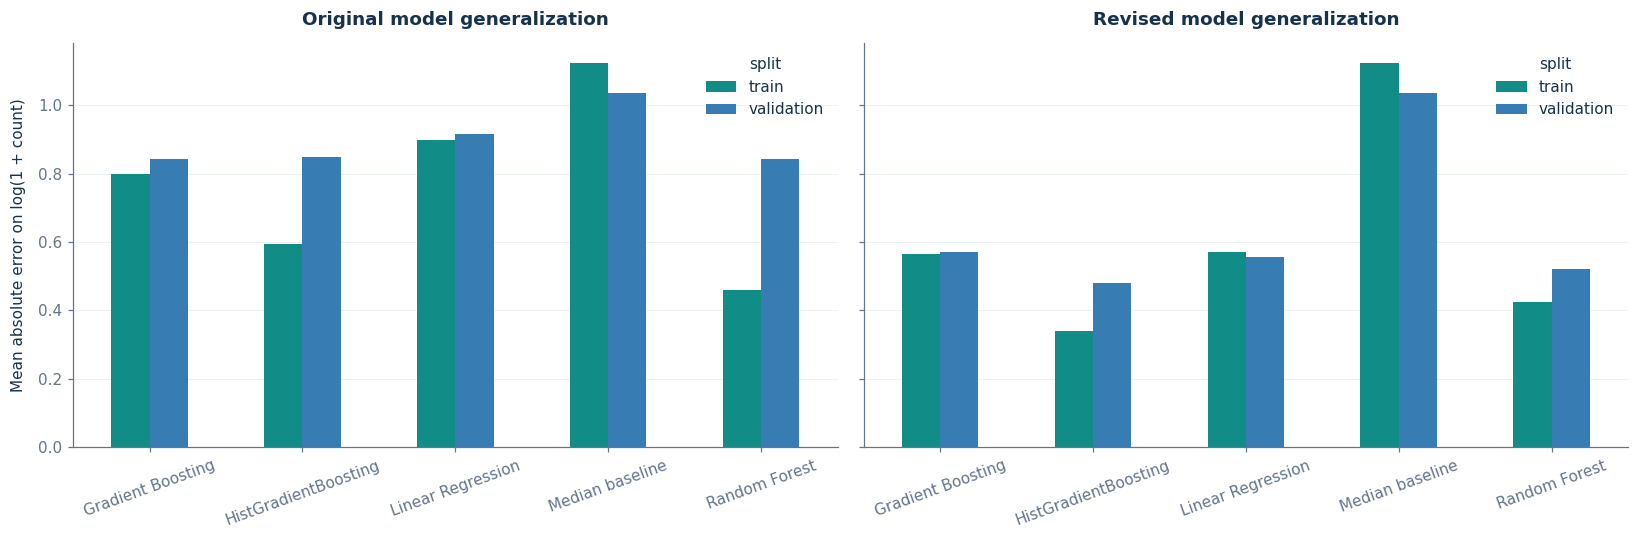

Random Forest log-MAE gap: 0.384 -> 0.098.
Gradient Boosting log-MAE gap: 0.042 -> 0.005.
HistGradientBoosting log-MAE gap: 0.253 -> 0.140.


version,validation R² (original),validation R² (enhanced)
model,,
Median baseline,-0.050,-0.050
Linear Regression,0.097,0.397
Random Forest,0.137,0.494
Gradient Boosting,0.124,0.416
HistGradientBoosting,0.133,0.557


In [19]:
diagnostic_rows = []
for family, model in models.items():
    for split_name, indices in [('train', train_idx), ('validation', val_idx)]:
        prediction = predict_counts(model, X_model.iloc[indices])
        diagnostic_rows.append({'version': 'revised', 'model': family, 'split': split_name,
                                **metrics(y.iloc[indices], prediction),
                                **log_metrics(y.iloc[indices], prediction)})
generalization = pd.concat([original_audit.assign(version='original'), pd.DataFrame(diagnostic_rows)], ignore_index=True)
display(generalization.round(3))
gap_table = generalization.pivot(index=['version', 'model'], columns='split', values='log_MAE')
gap_table['validation_minus_train_log_MAE'] = gap_table['validation'] - gap_table['train']
display(gap_table.round(3))
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for axis, version in zip(axes, ['original', 'revised']):
    data = generalization[generalization['version'].eq(version)].pivot(index='model', columns='split', values='log_MAE')
    data[['train', 'validation']].plot.bar(ax=axis, color=[THEME['teal'], THEME['blue']], rot=20)
    axis.set(title=f'{version.title()} model generalization', ylabel='Mean absolute error on log(1 + count)', xlabel='')
plt.show()
for family in ['Random Forest', 'Gradient Boosting', 'HistGradientBoosting']:
    before = float(gap_table.loc[('original', family), 'validation_minus_train_log_MAE'])
    after = float(gap_table.loc[('revised', family), 'validation_minus_train_log_MAE'])
    print(f'{family} log-MAE gap: {before:.3f} -> {after:.3f}.')

before_after = generalization[generalization['split'].eq('validation')].pivot(index='model', columns='version', values='R2')
display(before_after.loc[MODEL_ORDER].round(3).rename(columns={'original': 'validation R² (original)',
                                                                'revised': 'validation R² (enhanced)'}))


## M1-7. Descriptive re-evaluation and residual analysis
The model was selected using validation only. All revised fixed candidates are evaluated on the original test set for completeness, using MAE, RMSE and R² in review-count units. Because the test set was seen in earlier notebook versions, these are **descriptive re-evaluation results**, not an untouched final benchmark.

Permutation importance uses validation data and the same clipped predictions as scoring. No parameters are changed after the test metrics are computed. Original-unit and log-scale train/validation gaps are reported to avoid overlooking tail errors or differences in target distributions.


,MAE,RMSE,R2
model,,,
Median baseline,99.424,239.636,-0.101
Linear Regression,59.442,157.947,0.522
Random Forest,57.524,160.077,0.509
Gradient Boosting,62.700,175.899,0.407
HistGradientBoosting,51.348,142.709,0.610


,business_id,name,stars,review_count,prediction,residual_actual_minus_prediction,absolute_error
1262,ctHjyadbDQAtUFfkcAFEHw,Zahav,4.5,3065,668.987228,2396.012772,2396.012772
636,S8ZFYEgMejpChID8tzKo9A,Amada,4.0,2109,678.102158,1430.897842,1430.897842
3834,i_FWONQD1ZBqrNE2b-M5Ug,Talula's Garden,4.5,1927,511.037253,1415.962747,1415.962747
1223,-mIlmp5l4hKlp1tvHRdvTg,Sonny's Famous Steaks,4.0,1697,437.450498,1259.549502,1259.549502
5708,K7KHmHzxNwzqiijSJeKe_A,Cafe La Maude,4.5,1485,537.180858,947.819142,947.819142
5437,qISf5ojuYbD9h71NumGUQA,Han Dynasty,4.0,1474,585.904210,888.095790,888.095790
343,d_tRshM-w6S4QxE4VVi8tQ,Jones,3.5,1141,368.683939,772.316061,772.316061
566,cXSyVvOr9YRN9diDkaWs0Q,Honey's Sit-N-Eat,4.0,1396,707.282428,688.717572,688.717572
4545,J8S7cPPlTgsQnXKVfTyN8g,PYT,3.0,806,119.863320,686.136680,686.136680
2499,Qw7tz-UkPrpXaVidWuab4Q,Philadelphia Museum of Art,4.5,767,101.078417,665.921583,665.921583


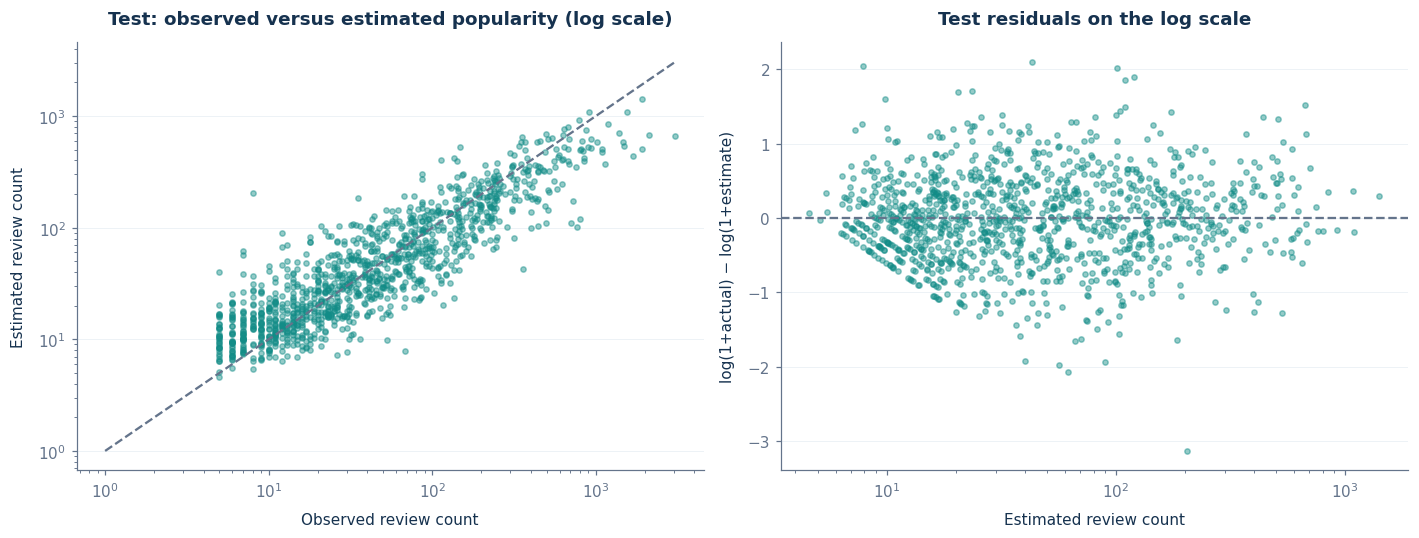

,feature,MAE_increase,std
15,checkin_active_years,19.081329,1.370093
16,attribute_count,15.515718,2.061435
4,price_range,3.485008,0.242640
2,stars,2.400502,0.117444
14,years_since_first_checkin,1.849821,0.339717
33,any_parking,1.443898,0.123034
6,competitors_0p5km,1.349949,0.526516
12,nearby_checkin_mean_1p0km,0.669112,0.087770
19,attr_OutdoorSeating,0.642426,0.099615
31,level_NoiseLevel,0.628622,0.254983


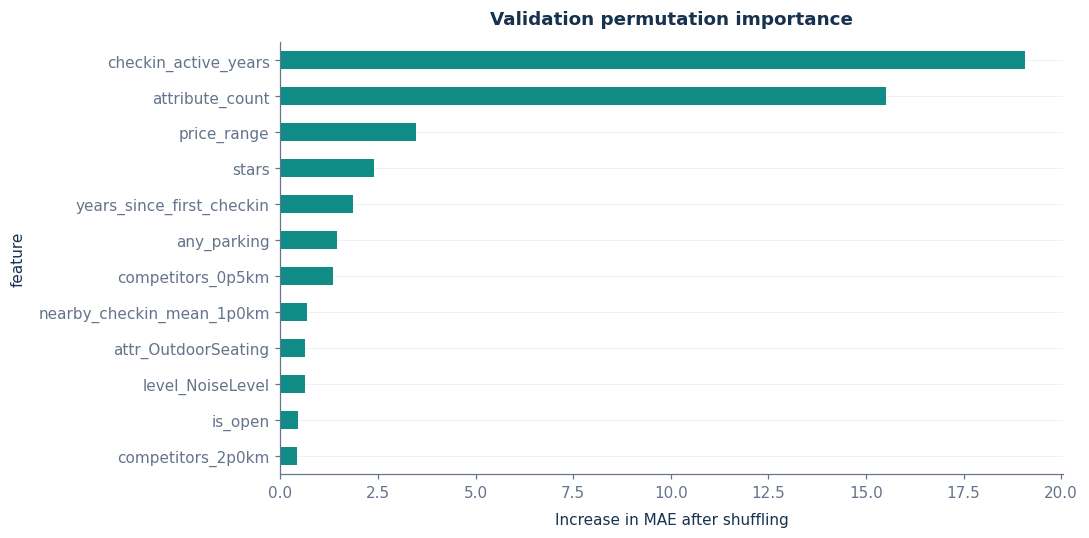

In [20]:
test_prediction = predict_counts(best_model, X_model.iloc[test_idx])
baseline_prediction = predict_counts(models['Median baseline'], X_model.iloc[test_idx])
test_results = pd.DataFrame([
    {'model': name, **metrics(y.iloc[test_idx], predict_counts(model, X_model.iloc[test_idx]))}
    for name, model in models.items()
]).set_index('model')
# Reporting all fixed candidates on test does not change the selected model.
display(test_results.round(3))

test_detail = restaurants.iloc[test_idx][['business_id', 'name', 'stars', 'review_count']].copy()
test_detail['prediction'] = test_prediction
test_detail['residual_actual_minus_prediction'] = test_detail['review_count'] - test_prediction
test_detail['absolute_error'] = np.abs(test_detail['residual_actual_minus_prediction'])
display(test_detail.nlargest(10, 'absolute_error'))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y.iloc[test_idx], test_prediction, alpha=.45, s=12, color=THEME['teal'])
limit = max(float(y.iloc[test_idx].max()), float(test_prediction.max()))
axes[0].plot([1, limit], [1, limit], '--', color=THEME['muted'])
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set(title='Test: observed versus estimated popularity (log scale)', xlabel='Observed review count', ylabel='Estimated review count')
axes[1].scatter(test_prediction, np.log1p(y.iloc[test_idx]) - np.log1p(test_prediction), alpha=.45, s=12, color=THEME['teal'])
axes[1].axhline(0, color=THEME['muted'], linestyle='--')
axes[1].set_xscale('log')
axes[1].set(title='Test residuals on the log scale', xlabel='Estimated review count', ylabel='log(1+actual) − log(1+estimate)')
plt.tight_layout(); plt.show()

# Interpretation on validation data; the test set does not drive model changes.
importance = permutation_importance(best_model, X_model.iloc[val_idx], y.iloc[val_idx],
                                    scoring=lambda model, features, actual: -mean_absolute_error(actual, predict_counts(model, features)), n_repeats=3,
                                    random_state=SEED, n_jobs=1)
importance_table = pd.DataFrame({'feature': X_model.columns, 'MAE_increase': importance.importances_mean,
                                  'std': importance.importances_std}).sort_values('MAE_increase', ascending=False)
display(importance_table.head(15))
importance_table.head(12).sort_values('MAE_increase').plot.barh(x='feature', y='MAE_increase', legend=False, color=THEME['teal'])
plt.title('Validation permutation importance'); plt.xlabel('Increase in MAE after shuffling')
plt.tight_layout(); plt.show()


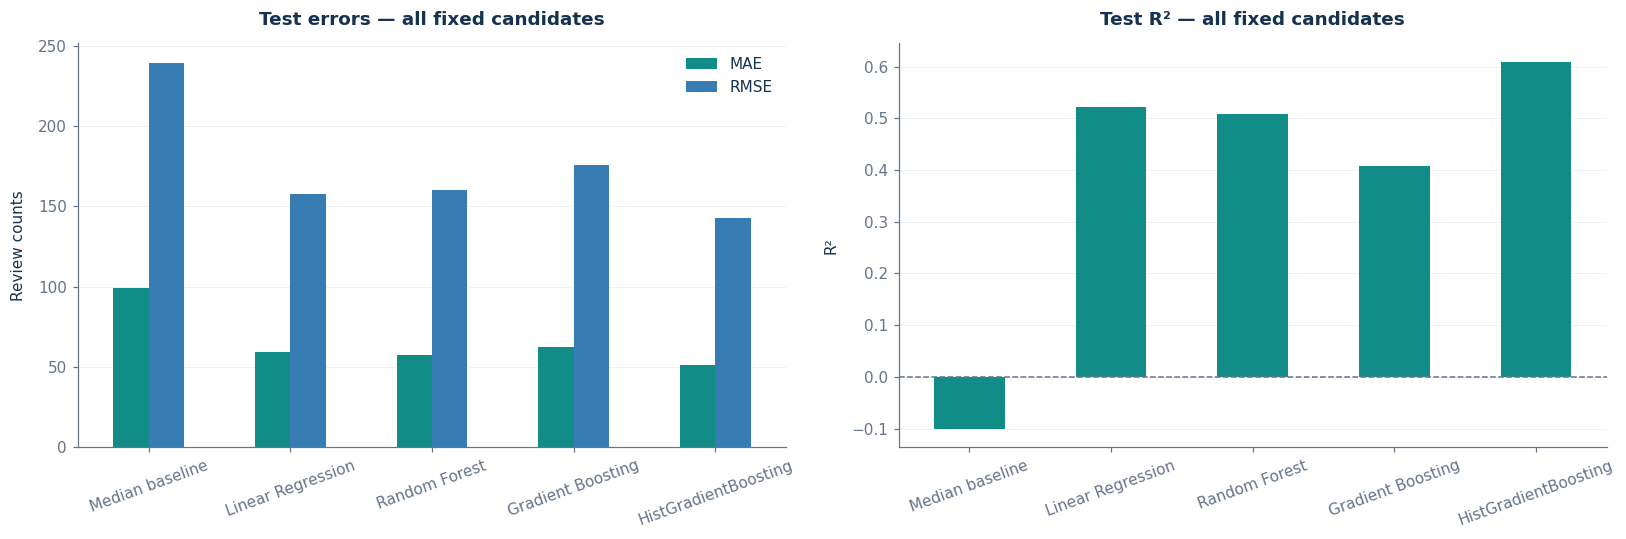

Selection is unchanged: HistGradientBoosting (chosen before viewing test metrics).


,restaurants,MAE,median_error
popularity_band,,,
0–20,398,8.34,4.68
21–100,451,23.38,16.79
101–500,255,84.53,66.12
>500,55,438.03,320.69


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ordered_models = MODEL_ORDER
test_results.loc[ordered_models, ['MAE', 'RMSE']].plot.bar(
    ax=axes[0], color=[THEME['teal'], THEME['blue']], rot=20)
axes[0].set(title='Test errors — all fixed candidates', ylabel='Review counts', xlabel='')
test_results.loc[ordered_models, 'R2'].plot.bar(ax=axes[1], color=THEME['teal'], rot=20)
axes[1].axhline(0, linestyle='--', color=THEME['muted'], linewidth=1)
axes[1].set(title='Test R² — all fixed candidates', ylabel='R²', xlabel='')
plt.show()
print('Selection is unchanged:', best_name, '(chosen before viewing test metrics).')

# Absolute-error summaries expose uneven performance across target popularity levels.
test_detail['popularity_band'] = pd.cut(test_detail['review_count'],
    bins=[-1, 20, 100, 500, np.inf], labels=['0–20', '21–100', '101–500', '>500'])
error_by_band = test_detail.groupby('popularity_band', observed=False).agg(
    restaurants=('business_id', 'size'), MAE=('absolute_error', 'mean'),
    median_error=('absolute_error', 'median'))
display(error_by_band.round(2))
error_by_band.to_csv(OUTPUT_DIR / 'test_error_by_popularity.csv')


### M1-7b. Prediction intervals for very popular restaurants (enhancement)
The table above shows the weakness: restaurants with more than 500 reviews are under-estimated by hundreds of reviews, because a few famous places are hard to tell apart from merely good ones. Instead of a single number, the app shows a **likely range**:

1. Two quantile HistGradientBoosting models (10th and 90th percentile, `loss='quantile'`) are trained on the training rows.
2. Raw quantile intervals are usually too narrow on new areas, so they are **conformally calibrated** (conformalized quantile regression). On the **validation** split we measure how far actual values fall outside the interval in log space, and widen both ends by the 80% quantile of that score. This guarantees about 80% coverage on new data drawn like the validation data.
3. Coverage is then checked once on the **test** split, which was not used for calibration.

Conformal adjustment: widen both ends by 0.166 on the log scale (x1.18 multiplicatively).


interval,conformal,raw quantile
popularity_band,,
all,81.4,68.6
0–20,82.2,69.3
21–100,84.7,72.7
101–500,79.6,67.1
>500,56.4,36.4


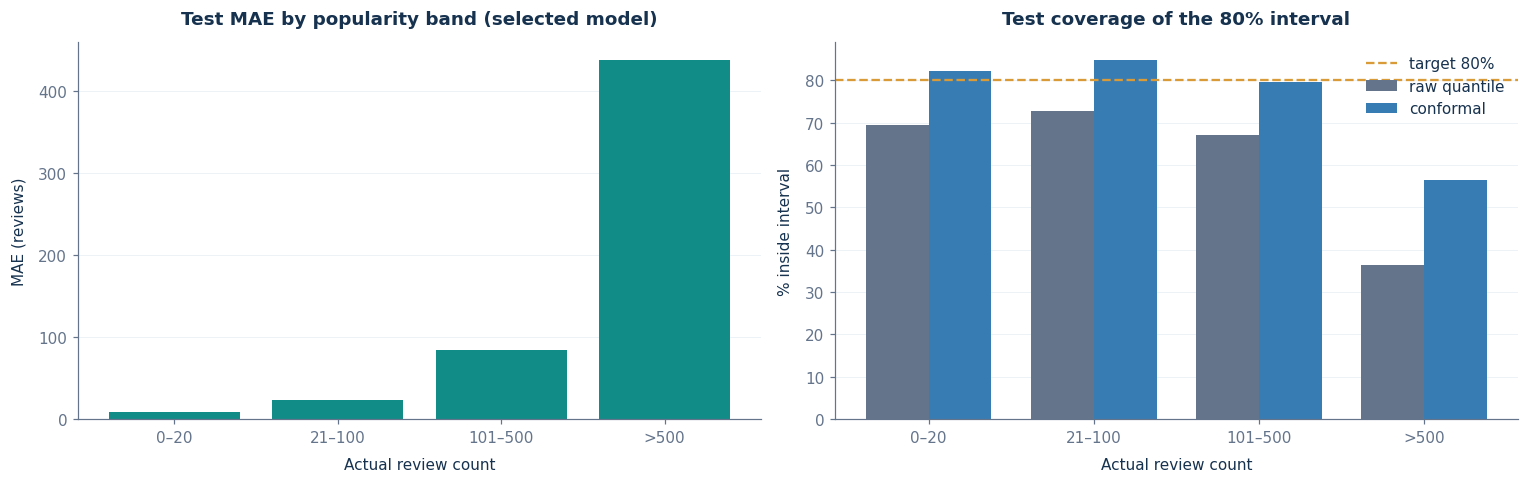

raw quantile: test coverage 68.6% (median width 57 reviews)
conformal: test coverage 81.4% (median width 75 reviews)


In [22]:
hgb_params = {k: v for k, v in selected_parameters['HistGradientBoosting'].items()}
quantile_models = {}
for q in (0.1, 0.9):
    quantile_models[q] = make_regression_pipeline(HistGradientBoostingRegressor(loss='quantile', quantile=q, early_stopping=False,
                                                                                random_state=SEED, **hgb_params))
    quantile_models[q].fit(X_model.iloc[train_idx], y.iloc[train_idx])

def raw_interval(idx):
    return tuple(predict_counts(quantile_models[q], X_model.iloc[idx]) for q in (0.1, 0.9))

# Conformal calibration on validation (log scale, where errors are roughly symmetric).
val_low, val_high = raw_interval(val_idx)
log_y_val = np.log1p(y.iloc[val_idx].to_numpy())
nonconformity = np.maximum(np.log1p(val_low) - log_y_val, log_y_val - np.log1p(val_high))
n_val = len(val_idx)
INTERVAL_LOG_ADJUSTMENT = float(np.quantile(nonconformity, min(1.0, 0.8 * (n_val + 1) / n_val)))
print(f'Conformal adjustment: widen both ends by {INTERVAL_LOG_ADJUSTMENT:.3f} on the log scale '
      f'(x{np.exp(INTERVAL_LOG_ADJUSTMENT):.2f} multiplicatively).')

def calibrated_interval(idx):
    low, high = raw_interval(idx)
    return (np.maximum(np.expm1(np.log1p(low) - INTERVAL_LOG_ADJUSTMENT), 0),
            np.expm1(np.log1p(high) + INTERVAL_LOG_ADJUSTMENT))

interval_rows = []
for version, make in [('raw quantile', raw_interval), ('conformal', calibrated_interval)]:
    for split_name, idx in [('validation', val_idx), ('test', test_idx)]:
        low, high = make(idx)
        actual = y.iloc[idx].to_numpy()
        inside = (actual >= low) & (actual <= high)
        bands = pd.cut(actual, bins=[-1, 20, 100, 500, np.inf], labels=['0–20', '21–100', '101–500', '>500'])
        for band in ['all', '0–20', '21–100', '101–500', '>500']:
            m = np.ones(len(idx), bool) if band == 'all' else (bands == band)
            interval_rows.append({'interval': version, 'split': split_name, 'popularity_band': band, 'restaurants': int(m.sum()),
                                  'coverage_pct': inside[m].mean() * 100, 'median_width': float(np.median((high - low)[m]))})
intervals = pd.DataFrame(interval_rows)
display(intervals[intervals['split'] == 'test'].pivot(index='popularity_band', columns='interval', values='coverage_pct')
        .reindex(['all', '0–20', '21–100', '101–500', '>500']).round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = ['0–20', '21–100', '101–500', '>500']
axes[0].bar(order, error_by_band.loc[order, 'MAE'], color=THEME['teal'])
axes[0].set(title='Test MAE by popularity band (selected model)', xlabel='Actual review count', ylabel='MAE (reviews)')
test_cov = intervals[(intervals['split'] == 'test') & (intervals['popularity_band'] != 'all')]
width = .38
for k, (version, color) in enumerate([('raw quantile', THEME['muted']), ('conformal', THEME['blue'])]):
    part = test_cov[test_cov['interval'] == version]
    axes[1].bar(np.arange(4) + (k - .5) * width, part['coverage_pct'], width, color=color, label=version)
axes[1].set_xticks(range(4), order)
axes[1].axhline(80, color=THEME['gold'], ls='--', label='target 80%')
axes[1].set(title='Test coverage of the 80% interval', xlabel='Actual review count', ylabel='% inside interval')
axes[1].legend()
plt.show()
for version in ['raw quantile', 'conformal']:
    row = intervals[(intervals['interval'] == version) & (intervals['split'] == 'test') & (intervals['popularity_band'] == 'all')].iloc[0]
    print(f"{version}: test coverage {row['coverage_pct']:.1f}% (median width {row['median_width']:.0f} reviews)")
intervals.to_csv(OUTPUT_DIR / 'prediction_interval_coverage.csv', index=False)

In [23]:
selected_metrics = test_results.loc[best_name]
baseline_mae = test_results.loc['Median baseline', 'MAE']
improvement = 100 * (baseline_mae - selected_metrics['MAE']) / baseline_mae if baseline_mae else np.nan
print(f'{best_name}: test MAE={selected_metrics["MAE"]:.2f}, '
      f'RMSE={selected_metrics["RMSE"]:.2f}, R²={selected_metrics["R2"]:.3f}.')
print(f'Test MAE improvement versus median baseline: {improvement:.1f}%.')
print('Strongest validation features:', ', '.join(importance_table.head(5)['feature']))
print('These are snapshot associations, not evidence that location causes popularity or revenue.')


HistGradientBoosting: test MAE=51.35, RMSE=142.71, R²=0.610.
Test MAE improvement versus median baseline: 48.4%.
Strongest validation features: checkin_active_years, attribute_count, price_range, stars, years_since_first_checkin
These are snapshot associations, not evidence that location causes popularity or revenue.


## M1-8. Export data, trained model and interactive map
The model bundle preserves its pipeline, feature order, category vocabulary and reference/candidate catalogs. The location table supports collaboration through `business_id`. Training predictions are in-sample; validation guides selection; test predictions use the reused original test split. Preserve these labels when sharing results.

The HTML map uses Leaflet and OpenStreetMap; map tiles and library scripts need internet access in the browser. Marker popups display ratings, competition, observed/estimated review counts and split labels.


In [24]:
location_table = pd.concat([restaurants[['business_id', 'name', 'address', 'city', 'state',
                                          'postal_code', 'categories', 'review_count', 'checkin_count']].reset_index(drop=True), X], axis=1)
location_table['split'] = split_labels.to_numpy()
location_table['estimated_review_count'] = predict_counts(best_model, X_model)
location_table['prediction_context'] = np.where(location_table['split'].eq('train'),
                                               'in-sample', 'held-out')
location_table.to_csv(OUTPUT_DIR / 'philadelphia_location_features.csv', index=False)
clean_export = business.drop(columns=['category_list']).copy()
clean_export['attributes'] = clean_export['attributes'].map(json.dumps)
if 'hours' in clean_export:
    clean_export['hours'] = clean_export['hours'].map(json.dumps)
clean_export.to_csv(OUTPUT_DIR / 'philadelphia_business_clean.csv', index=False)
validation_results.to_csv(OUTPUT_DIR / 'validation_metrics.csv')
test_results.to_csv(OUTPUT_DIR / 'test_metrics.csv')
test_detail.to_csv(OUTPUT_DIR / 'test_predictions.csv', index=False)
importance_table.to_csv(OUTPUT_DIR / 'validation_feature_importance.csv', index=False)
joblib.dump({'model': best_model, 'model_name': best_name, 'model_q10': quantile_models[0.1], 'model_q90': quantile_models[0.9],
             'interval_log_adjustment': INTERVAL_LOG_ADJUSTMENT, 'feature_columns': list(X_model.columns),
             'category_tags': MODEL_TAGS, 'train_reference': train_reference,
             'restaurant_catalog': restaurants, 'seed': SEED, 'sklearn_version': sklearn.__version__,
             'target': 'cumulative review_count; not revenue'}, OUTPUT_DIR / 'member1_model.joblib')
metadata = {'city': 'Philadelphia', 'state': 'PA', 'audit': audit, 'selected_model': best_name,
            'target': 'review_count', 'test_metrics': selected_metrics.to_dict(),
            'review_file_used': False, 'checkin_file_used': True,
            'snapshot_date': str(SNAPSHOT_DATE.date()), 'split_counts': split_labels.value_counts().to_dict(),
            'feature_columns': list(X_model.columns), 'sklearn_version': sklearn.__version__}
(OUTPUT_DIR / 'run_summary.json').write_text(json.dumps(metadata, indent=2), encoding='utf-8')

markers = []
for _, row in location_table.iterrows():
    popup = (f'<b>{html.escape(str(row["name"]))}</b><br>'
             f'Rating: {row["stars"]}<br>Reviews: {row["review_count"]:,}<br>'
             f'Estimated reviews: {row["estimated_review_count"]:.0f}<br>'
             f'Competitors (1 km): {row["competitors_1p0km"]}<br>'
             f'Years on Yelp (approx.): {row["years_since_first_checkin"]:.1f}<br>'
             f'Split: {row["split"]} ({row["prediction_context"]})')
    markers.append({'lat': row['latitude'], 'lon': row['longitude'], 'popup': popup,
                    'split': row['split']})
map_template = """<!doctype html><html><head><meta charset="utf-8"><title>Philadelphia restaurant locations</title>
<link rel="stylesheet" href="https://unpkg.com/leaflet@1.9.4/dist/leaflet.css">
<style>body{margin:0;font-family:Arial}header{padding:14px;background:#102a43;color:white}#map{height:80vh}</style>
</head><body><header><b>Philadelphia · Restaurant location intelligence</b><br>
Cumulative Yelp popularity, not revenue · blue: train; gold: validation; teal: test</header><div id="map"></div>
<script src="https://unpkg.com/leaflet@1.9.4/dist/leaflet.js"></script><script>
const map=L.map('map').setView([39.9526,-75.1636],12);
L.tileLayer('https://{s}.tile.openstreetmap.org/{z}/{x}/{y}.png',
{attribution:'© OpenStreetMap contributors',maxZoom:19}).addTo(map);
const data=__MARKERS__; const colors={train:'#387CB4',validation:'#D89B38',test:'#128C87'};
data.forEach(d=>L.circleMarker([d.lat,d.lon],{radius:4,color:colors[d.split],weight:1,fillOpacity:.65})
.addTo(map).bindPopup(d.popup));
</script></body></html>"""
# Avoid HTML script termination through a business name.
map_html = map_template.replace('__MARKERS__', json.dumps(markers).replace('</', r'<\/'))
map_path = OUTPUT_DIR / 'philadelphia_restaurant_map.html'
map_path.write_text(map_html, encoding='utf-8')
try:
    from IPython.display import HTML, display
    display(HTML('<iframe srcdoc="' + html.escape(map_html, quote=True) +
                 '" width="100%" height="650" style="border:0"></iframe>'))
except ImportError:
    print('Open the HTML map in a browser:', map_path)
print('Saved data, metrics, model and map to', OUTPUT_DIR.resolve())

postal_summary.to_csv(OUTPUT_DIR / 'philadelphia_postal_summary.csv')
feature_dictionary.to_csv(OUTPUT_DIR / 'feature_dictionary.csv', index=False)

cv_results.to_csv(OUTPUT_DIR / 'spatial_cv_results.csv', index=False)
generalization.to_csv(OUTPUT_DIR / 'generalization_diagnostics.csv', index=False)
original_audit.to_csv(OUTPUT_DIR / 'original_model_audit.csv', index=False)
leakage_audit.to_csv(OUTPUT_DIR / 'leakage_audit.csv', index=False)
(OUTPUT_DIR / 'audit_summary.json').write_text(json.dumps({
    'excluded_regression_features': EXCLUDED_MODEL_FEATURES,
    'selected_parameters': selected_parameters,
    'cv_folds': 3, 'selection_rule': 'train-block CV MAE per family, then validation MAE',
    'test_status': 'reused original test set; descriptive re-evaluation only',
    'catalog_assumption': 'full restaurant geometry and check-ins known; no catalog review targets used in model features',
    'own_checkin_count_used': False,
    'leakage_checks_passed': bool(leakage_audit['passed'].all())}, indent=2), encoding='utf-8')

regression_inputs = pd.concat([restaurants[['business_id', 'review_count']].reset_index(drop=True), X_model], axis=1)
regression_inputs['split'] = split_labels.to_numpy()
regression_inputs.to_csv(OUTPUT_DIR / 'philadelphia_regression_inputs.csv', index=False)


C:\Users\Asus\Downloads\nti 1\.venv\Lib\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Saved data, metrics, model and map to C:\Users\Asus\Downloads\nti 1\nti final\BusinessLaunchAI\outputs\member1


## M1-9. Streamlit location page
The exported table, model bundle and metrics are used by the integrated BusinessLaunch AI app.


The Streamlit location page is no longer generated by this notebook. It lives in `app/pages/1_Location_Intelligence.py` and reads the files exported above; the shared feature code is in `src/businesslaunch/location.py`. Run the full app from the project root with `streamlit run app/Home.py`.


## M1-10. Member 1 deliverables and presentation notes
Running this notebook creates:

| Deliverable | File |
|---|---|
| Leakage audit, spatial CV and generalization diagnostics | `leakage_audit.csv`, `spatial_cv_results.csv`, `generalization_diagnostics.csv` |
| Original model audit | `original_model_audit.csv` |
| Consistently styled PNG/SVG plots | `figures/` |
| Postal-code EDA and feature dictionary | `philadelphia_postal_summary.csv`, `feature_dictionary.csv` |
| Rejected-row cleaning audit | `rejected_philadelphia_rows.csv` |
| Cleaned Philadelphia business data | `philadelphia_business_clean.csv` |
| Audited regression inputs and row labels | `philadelphia_regression_inputs.csv` |
| Restaurant location features, split and predictions | `philadelphia_location_features.csv` |
| Trained selected regression pipeline and catalogs | `member1_model.joblib` |
| Validation and final test metrics | `validation_metrics.csv`, `test_metrics.csv` |
| Error by restaurant popularity band | `test_error_by_popularity.csv` |
| Final test predictions and feature interpretation | `test_predictions.csv`, `validation_feature_importance.csv` |
| Interactive location map | `philadelphia_restaurant_map.html` |
| Streamlit location page | `app/pages/1_Location_Intelligence.py` (project app) |
| Run metadata and cleaning audit | `run_summary.json` |

**Presentation outline:** explain the Philadelphia filter and cleaning audit; show category/rating/location charts; define haversine competition and training-only review features; compare the three required regressors on validation; report the selected model's final MAE/RMSE/R² against the median baseline; demonstrate the map; explain limitations.

**Limitations:** review count depends on age, Yelp coverage and customer behavior, not just location. Yelp age is approximated by the first check-in, which can lag the real opening date; ~3% of restaurants have no check-ins. Attribute completeness (`attribute_count`) partly reflects how actively a listing is maintained, so it is a snapshot association, not a cause. Opening dates and revenue are unavailable. Ratings and neighbor counts are contemporaneous snapshot information, so this is not a future forecast or a cold-start model. Closed businesses may have accumulated reviews before closure. Spatial blocks reduce but do not eliminate geographic dependence. Mean nearby cumulative review count is not a rate; nearby check-in activity is a cumulative visit signal, and recent review activity needs the review JSON and a defined time window. Feature importance describes predictive association and can be unstable for correlated features.

**Team handoff:** join other members' outputs by `business_id`, retaining city/state and split labels. No sentiment analysis, topic modeling, or clustering is performed here.

**Audit limitations:** the reused test set is not a new independent benchmark. The full catalog is used only for target-free geometry; if catalog coverage changes, competition counts and model performance can change. Temporal leakage cannot be assessed without dated feature snapshots and review histories, so no forecasting claim is made.


---

# Part 2 · Member 2 — NLP, Sentiment Classification & Complaint Topics

 It independently selects Philadelphia restaurants and cafés, reads matching Yelp reviews, trains sentiment models, discovers recurring review topics, and exports competitor information.


> **Project version.** Paths point to `data/` and `outputs/member2/`; the competitor module lives in `src/businesslaunch/competitor_analysis.py` and the Streamlit page in `app/pages/2_Customer_Reviews.py`. Saved outputs below are from Member 2's full run (703,584 reviews). Cells marked **(enhanced)** add the accuracy improvements and are executed when the notebook is re-run with `data/yelp_academic_dataset_review.json`.


> **Running Part 2.** Part 2 needs `data/yelp_academic_dataset_review.json` (5.3 GB, see `data/README.md`). The outputs shown here are from Member 2's full run on 703,584 reviews; cells marked *(enhanced)* add the accuracy improvements and fill in on the next full run. **If the review file is not available, skip to Part 3** — it reads Part 2's saved results from `outputs/member2/`, so the rest of the notebook still runs.

## M2-1. Imports and dataset loading


In [ ]:
import io
import json
import tempfile
import zipfile
import importlib
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.naive_bayes import MultinomialNB
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

# File locations: change these if the data is somewhere else (.json or .zip).
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'businesslaunch').exists())
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
DATA_DIR = PROJECT_ROOT / 'data'
BUSINESS_FILE = next((DATA_DIR / n for n in ['yelp_academic_dataset_business.json', 'yelp_academic_dataset_business.json.zip'] if (DATA_DIR / n).exists()), DATA_DIR / 'yelp_academic_dataset_business.json')
REVIEW_FILE = next((DATA_DIR / n for n in ['yelp_academic_dataset_review.json', 'yelp_academic_dataset_review.json.zip'] if (DATA_DIR / n).exists()), DATA_DIR / 'yelp_academic_dataset_review.json')
M2_DIR = PROJECT_ROOT / 'outputs' / 'member2'
M2_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
SAMPLE_SIZE = 300_000     # (enhanced) was 100,000: 3x more training reviews; None = all 610k binary reviews
NMF_SAMPLE = 30_000       # negative reviews used to fit the topic model
MIN_COMPLAINTS = 5        # minimum classified complaints before a business gets a "top complaint topic"

# Plain, consistent plot style. This also undoes the plt.show wrapper from the Member 1 cells, if they were run.
if hasattr(plt, '_member1_original_show'):
    plt.show = plt._member1_original_show
plt.rcdefaults()
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False})
SENT_ORDER = ['Negative', 'Neutral', 'Positive']
SENT_COLORS = {'Negative': 'tab:red', 'Neutral': 'tab:gray', 'Positive': 'tab:green'}


def open_json_lines(path, keyword):
    # Open a Yelp JSON-lines file; if it is a zip, read the matching .json inside it.
    path = Path(path)
    if path.suffix == '.zip':
        archive = zipfile.ZipFile(path)
        names = [n for n in archive.namelist() if n.endswith('.json') and keyword in n]
        if not names:
            raise FileNotFoundError(f'No {keyword} JSON file found inside {path}')
        return io.TextIOWrapper(archive.open(names[0]), encoding='utf-8')
    return open(path, encoding='utf-8')


with open_json_lines(BUSINESS_FILE, 'business') as handle:
    business_raw = pd.read_json(handle, lines=True, dtype=False, convert_dates=False)
print('Business file shape:', business_raw.shape)
print('Columns:', list(business_raw.columns))

## M2-2. Philadelphia restaurant and café business ID extraction


1. `city` equals Philadelphia and `state` equals PA, ignoring capitalization and extra spaces.
2. At least one category is exactly `Restaurants`, `Cafes` or `Coffee & Tea`. The category string is split on commas first, so a category such as `Coffee Roasteries` does not match by accident.
3. Missing or duplicate `business_id` values are removed.
4. Coordinates are checked. A record with missing or implausible coordinates stays in the ID list (its reviews can still be analyzed) but is flagged with `valid_coordinates = False` and left out of the location analysis in M2-17. "Plausible" means inside a box around Philadelphia (latitude 39.8 to 40.2, longitude -75.4 to -74.9), the same bounds Member 1 uses.

In [24]:
TARGET_CATEGORIES = {'Restaurants', 'Cafes', 'Coffee & Tea'}
selection_log = [('All businesses in file', len(business_raw))]

biz = business_raw.copy()
is_philadelphia = ((biz['city'].fillna('').astype(str).str.strip().str.lower() == 'philadelphia')
                   & (biz['state'].fillna('').astype(str).str.strip().str.upper() == 'PA'))
biz = biz[is_philadelphia]
selection_log.append(('City is Philadelphia and state is PA', len(biz)))


def has_target_category(text):
    if not isinstance(text, str):
        return False
    return bool(TARGET_CATEGORIES & {c.strip() for c in text.split(',')})


biz = biz[biz['categories'].map(has_target_category)]
selection_log.append(('Category is Restaurants, Cafes or Coffee & Tea', len(biz)))

biz = biz[biz['business_id'].notna()].copy()
biz['business_id'] = biz['business_id'].astype(str).str.strip()
biz = biz[biz['business_id'] != '']
biz = biz.drop_duplicates('business_id')
selection_log.append(('After removing missing and duplicate business_id', len(biz)))

# Coordinates: missing or outside the Philadelphia area means unusable for location analysis.
biz['latitude'] = pd.to_numeric(biz['latitude'], errors='coerce')
biz['longitude'] = pd.to_numeric(biz['longitude'], errors='coerce')
missing_coords = biz['latitude'].isna() | biz['longitude'].isna()
inside_area = biz['latitude'].between(39.8, 40.2) & biz['longitude'].between(-75.4, -74.9)
biz['valid_coordinates'] = ~missing_coords & inside_area
selection_log.append(('Of these, with usable coordinates', int(biz['valid_coordinates'].sum())))

biz['is_open'] = pd.to_numeric(biz['is_open'], errors='coerce')   # 1 = open, 0 = closed at the dataset snapshot
philly = biz[['business_id', 'name', 'address', 'categories', 'latitude', 'longitude', 'is_open', 'valid_coordinates']].reset_index(drop=True)
philly.to_csv(M2_DIR / 'philadelphia_business_ids.csv', index=False)

display(pd.DataFrame(selection_log, columns=['step', 'businesses']))
print('Missing coordinates:', int(missing_coords.sum()), '| outside the Philadelphia area:', int((~missing_coords & ~inside_area).sum()))
print('Selected businesses saved to philadelphia_business_ids.csv:', len(philly))

,step,businesses
0,All businesses in file,150346
1,City is Philadelphia and state is PA,14575
2,"Category is Restaurants, Cafes or Coffee & Tea",6174
3,After removing missing and duplicate business_id,6174
4,"Of these, with usable coordinates",6174


Missing coordinates: 0 | outside the Philadelphia area: 0
Selected businesses saved to philadelphia_business_ids.csv: 6174


**What we did / what to notice.** The filter requires Philadelphia, PA and an exact category tag of `Restaurants`, `Cafes`, or `Coffee & Tea`. Businesses without valid coordinates remain in the review analysis but cannot appear in geographic competitor searches. Compare this list with Member 1's more restrictive restaurant-only list.

**Consistency with Member 1.** Member 1's notebook keeps only businesses tagged `Restaurants`, and it also drops records with implausible coordinates. This notebook also includes cafés and coffee shops that do not carry the `Restaurants` tag, and it keeps businesses with unusable coordinates (flagged, not dropped). So the two business lists are **not identical**. The cell below counts the difference using only this notebook's data.

Before the three members combine results, the team has to agree on one list. Two options: everyone uses `philadelphia_business_ids.csv` from this notebook, or this notebook's summary is restricted to Member 1's final list with an inner join on `business_id`. Until then, joins on `business_id` will leave unmatched rows on one side or the other.

In [25]:
category_sets = philly['categories'].map(lambda text: {c.strip() for c in text.split(',')})
has_restaurants_tag = category_sets.map(lambda s: 'Restaurants' in s)
consistency = pd.Series({
    'Selected businesses (this notebook)': len(philly),
    'Tagged Restaurants (the Member 1 rule)': int(has_restaurants_tag.sum()),
    'Cafe or coffee tag only, no Restaurants tag': int((~has_restaurants_tag).sum()),
    'Unusable coordinates (Member 1 would drop these)': int((~philly['valid_coordinates']).sum())}, name='count')
display(consistency.to_frame())

,count
Selected businesses (this notebook),6174
Tagged Restaurants (the Member 1 rule),5855
"Cafe or coffee tag only, no Restaurants tag",319
Unusable coordinates (Member 1 would drop these),0


### Shared business IDs for team integration

 The  cell compares it with Member 2's broader list and exports their overlap. This doesn't silently change Member 1's historical regression or its saved metrics.

In [26]:
# Shared IDs for Member 1/2 integration (when both sections were run).
if 'restaurants' in globals() and 'business_id' in restaurants.columns:
    member1_ids = set(restaurants['business_id'])
    member2_ids = set(philly['business_id'])
    shared_ids = sorted(member1_ids & member2_ids)
    pd.DataFrame({'business_id': shared_ids}).to_csv(M2_DIR / 'shared_member1_member2_business_ids.csv', index=False)
    print('Member 1 business IDs:', len(member1_ids))
    print('Member 2 business IDs:', len(member2_ids))
    print('Matching IDs:', len(shared_ids))
    print('Only in Member 2:', len(member2_ids - member1_ids))
    print('Use the same category rule and rerun Member 1 before claiming the complete lists match.')
else:
    print('Member 1 has not been run in this kernel. Member 2 can still run independently.')


Member 1 business IDs: 5855
Member 2 business IDs: 6174
Matching IDs: 5855
Only in Member 2: 319
Use the same category rule and rerun Member 1 before claiming the complete lists match.


## M2-3. Review filtering
The review file is read in chunks of 100,000 lines. Each chunk is filtered to the selected business IDs and only the needed columns are kept, so the full file is never in memory at once.

In [27]:
selected_ids = set(philly['business_id'])


def load_philadelphia_reviews(path, business_ids, chunk_size=100_000):
    columns = ['review_id', 'user_id', 'business_id', 'stars', 'date', 'text']
    parts, rows_read = [], 0
    with open_json_lines(path, 'review') as handle:
        reader = pd.read_json(handle, lines=True, chunksize=chunk_size, dtype=False, convert_dates=False)
        for chunk in reader:
            rows_read += len(chunk)
            parts.append(chunk.loc[chunk['business_id'].isin(business_ids), columns])
            print(f'\rReview rows read: {rows_read:,}', end='')
    print()
    return pd.concat(parts, ignore_index=True), rows_read


reviews_raw, total_review_rows = load_philadelphia_reviews(REVIEW_FILE, selected_ids)
print(f'Rows in review file: {total_review_rows:,}')
print(f'Reviews for the selected businesses: {len(reviews_raw):,}')
print(f'Unique businesses with at least one review: {reviews_raw["business_id"].nunique():,} of {len(selected_ids):,} selected')

Review rows read: 6,990,280
Rows in review file: 6,990,280
Reviews for the selected businesses: 704,625
Unique businesses with at least one review: 6,174 of 6,174 selected


**What we did / what to notice.** The review JSON is processed in chunks and only matching `business_id` rows are kept. A restaurant can have many reviews, so the number of review rows will be much larger than the number of businesses. This step avoids analyzing reviews from unrelated cities.

## M2-4. Data inspection

In [28]:
print('Shape:', reviews_raw.shape)
display(reviews_raw.head())
display(reviews_raw.dtypes.rename('dtype').to_frame())

missing_table = pd.DataFrame({'missing': reviews_raw.isna().sum(),
                              'missing_percent': (reviews_raw.isna().mean() * 100).round(3)})
display(missing_table)
print('Blank review text (empty or spaces only):', int((reviews_raw['text'].fillna('x').str.strip() == '').sum()))
print('Duplicate review_id values:', int(reviews_raw['review_id'].duplicated().sum()))

rating_counts = reviews_raw['stars'].value_counts().sort_index()
display(pd.DataFrame({'reviews': rating_counts, 'percent': (rating_counts / rating_counts.sum() * 100).round(2)}))

reviews_raw['date'] = pd.to_datetime(reviews_raw['date'], errors='coerce')
print('Review date range:', reviews_raw['date'].min(), 'to', reviews_raw['date'].max())
print('Unique businesses:', reviews_raw['business_id'].nunique())

Shape: (704625, 6)


,review_id,user_id,business_id,stars,date,text
0,AqPFMleE6RsU23_auESxiA,_7bHUi9Uuf5__HHc_Q8guQ,kxX2SOes4o-D3ZQBkiMRfA,5.0,2015-01-04 00:01:03,"Wow! Yummy, different, delicious. Our favo..."
1,JrIxlS1TzJ-iCu79ul40cQ,eUta8W_HdHMXPzLBBZhL1A,04UD14gamNjLY0IDYVhHJg,1.0,2015-09-23 23:10:31,I am a long term frequent customer of this est...
2,8JFGBuHMoiNDyfcxuWNtrA,smOvOajNG0lS4Pq7d8g4JQ,RZtGWDLCAtuipwaZ-UfjmQ,4.0,2009-10-14 19:57:14,Good food--loved the gnocchi with marinara\nth...
3,oyaMhzBSwfGgemSGuZCdwQ,Dd1jQj7S-BFGqRbApFzCFw,YtSqYv1Q_pOltsVPSx54SA,5.0,2013-06-24 11:21:25,Tremendous service (Big shout out to Douglas) ...
4,Xs8Z8lmKkosqW5mw_sVAoA,IQsF3Rc6IgCzjVV9DE8KXg,eFvzHawVJofxSnD7TgbZtg,5.0,2014-11-12 15:30:27,My absolute favorite cafe in the city. Their b...


,dtype
review_id,str
user_id,str
business_id,str
stars,float64
date,str
text,str


,missing,missing_percent
review_id,0,0.0
user_id,0,0.0
business_id,0,0.0
stars,0,0.0
date,0,0.0
text,0,0.0


Blank review text (empty or spaces only): 0
Duplicate review_id values: 0


,reviews,percent
stars,,
1.0,68218,9.68
2.0,58616,8.32
3.0,93666,13.29
4.0,199020,28.24
5.0,285105,40.46


Review date range: 2005-02-16 04:06:26 to 2022-01-19 19:46:34
Unique businesses: 6174


**What to notice — raw review quality.** Check how many review texts are missing or blank and whether `review_id` repeats. The rating distribution is usually uneven, which matters when evaluating classification. These tables refer only to the selected Philadelphia businesses.

**Data inspection.** This table checks how many review records belong to the selected Philadelphia businesses and whether text, IDs, ratings or dates need cleaning. Duplicate IDs and invalid text are handled in M2-5. The date range is used only to describe the review history, not to make future predictions. In the previously shown local run, the cleaned dataset contained 703,584 reviews; the uploaded notebook itself does not include the M2 output tables.

## M2-5. Data cleaning
Decisions:

- **Duplicates.** Rows with the same `review_id` are removed. Rows with the same user, business and text are also removed, because they are the same review posted twice.
- **Missing, empty and invalid.** Reviews with missing or blank text are removed, as are ratings that are not whole numbers from 1 to 5. A review that is empty after cleaning (for example only punctuation) is removed too.
- **Original text is kept** in `review_text`. The cleaned version goes in `clean_text`.
- **Normalization.** Lowercase; URLs removed; contractions such as "don't" become "do not" so negation survives; remaining punctuation and digits become spaces; extra spaces collapsed. Accented letters are kept so "café" is not cut to "caf".
- **Negations and stopwords.** The sentiment model uses all words, including "not", "no" and "never", with unigrams and bigrams, so a phrase like "not good" is a feature. Stopword removal is only applied where the goal is to read frequent words (EDA and topic modeling), using scikit-learn's English list.
- **Not done.** No stemming or lemmatization (it adds little for TF-IDF with bigrams) and no spelling correction.

In [29]:
def normalize_text(texts):
    # Lowercase, remove URLs and punctuation, turn contractions like "don't" into "do not".
    s = pd.Series(texts).astype(str).str.lower()
    s = s.str.replace('\u2019', "'", regex=False)
    s = s.str.replace(r'https?://\S+|www\.\S+', ' ', regex=True)
    s = s.str.replace("won't", 'will not', regex=False).str.replace("can't", 'can not', regex=False)
    s = s.str.replace(r"n't\b", ' not', regex=True)
    s = s.str.replace(r"'(?:s|m|re|ve|ll|d)\b", '', regex=True)
    s = s.str.replace(r'[^a-zà-ÿ\s]', ' ', regex=True)   # keeps accented letters such as the e in cafe
    return s.str.replace(r'\s+', ' ', regex=True).str.strip()


reviews = reviews_raw.copy()
cleaning_log = [('Reviews after business filter', len(reviews))]


def record(step):
    cleaning_log.append((step, len(reviews)))


reviews = reviews.drop_duplicates('review_id')
record('Remove duplicate review_id')
reviews = reviews.drop_duplicates(['user_id', 'business_id', 'text'])
record('Remove same user, business and text')
reviews = reviews[reviews['text'].notna() & (reviews['text'].astype(str).str.strip() != '')]
record('Remove missing or blank text')
reviews = reviews[pd.to_numeric(reviews['stars'], errors='coerce').isin([1, 2, 3, 4, 5])]
record('Remove invalid ratings')

reviews = reviews.rename(columns={'text': 'review_text'}).drop(columns='user_id')
reviews['stars'] = reviews['stars'].astype(int)
reviews['clean_text'] = normalize_text(reviews['review_text'])
reviews = reviews[reviews['clean_text'] != ''].reset_index(drop=True)
record('Remove text that is empty after cleaning')

log_table = pd.DataFrame(cleaning_log, columns=['step', 'reviews'])
log_table['removed'] = -log_table['reviews'].diff().fillna(0).astype(int)
display(log_table)

# Show the cleaning on a few reviews and check that negation words survive.
display(reviews[['review_text', 'clean_text']].sample(3, random_state=RANDOM_STATE))
test_sentence = "I don't like it, never again! Can't recommend: https://example.com"
print(normalize_text([test_sentence])[0])
tokens = CountVectorizer(stop_words=sorted(ENGLISH_STOP_WORDS)).build_analyzer()(normalize_text([test_sentence])[0])
print('Tokens after stopword removal (EDA and topic modeling only):', tokens)

,step,reviews,removed
0,Reviews after business filter,704625,0
1,Remove duplicate review_id,704625,0
2,"Remove same user, business and text",703650,975
3,Remove missing or blank text,703650,0
4,Remove invalid ratings,703650,0
5,Remove text that is empty after cleaning,703584,66


,review_text,clean_text
598605,Ive been to Fuel a few times.. my friend and I...,ive been to fuel a few times my friend and i w...
163668,finding good falafel is a chore. in west phill...,finding good falafel is a chore in west philly...
470433,Oh man. It would've been a grave injustice to ...,oh man it would been a grave injustice to ever...


i do not like it never again can not recommend
Tokens after stopword removal (EDA and topic modeling only): ['like', 'recommend']


**What to notice — cleaning.** Compare the counts before and after every cleaning step. The original text is kept as `review_text`; `clean_text` is used for modeling. The printed example checks whether negation such as *not* survives. Removing important negation can reverse the meaning of a review.

## M2-6. Exploratory data analysis
EDA uses all cleaned reviews. The positive, neutral and negative groups used here come from the star rule defined in M2-7 (1–2 stars negative, 3 neutral, 4–5 positive).

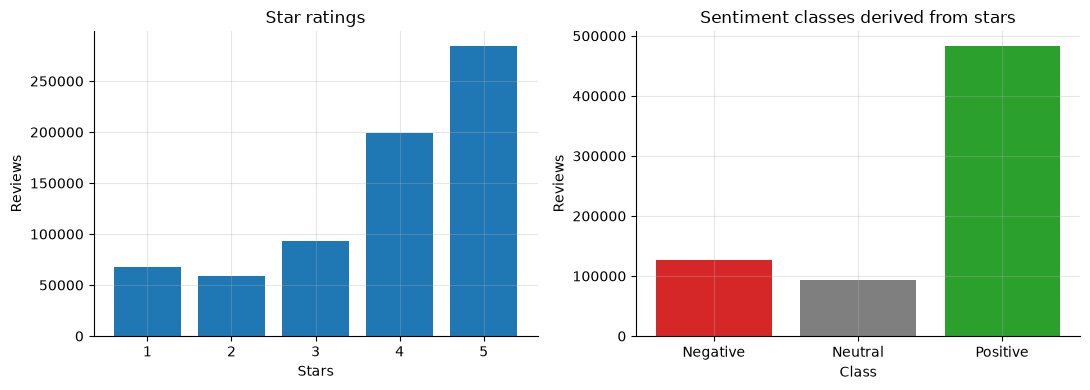

stars
1     9.7
2     8.3
3    13.3
4    28.3
5    40.4
stars
Negative    18.0
Neutral     13.3
Positive    68.7


In [30]:
def stars_to_sentiment(stars):
    # 1-2 stars: Negative, 3 stars: Neutral, 4-5 stars: Positive
    return pd.cut(stars, bins=[0, 2, 3, 5], labels=SENT_ORDER).astype(str)


star_sentiment = stars_to_sentiment(reviews['stars'])
star_counts = reviews['stars'].value_counts().sort_index()
sentiment_counts = star_sentiment.value_counts().reindex(SENT_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(star_counts.index.astype(str), star_counts.values, color='tab:blue')
axes[0].set(title='Star ratings', xlabel='Stars', ylabel='Reviews')
axes[1].bar(sentiment_counts.index, sentiment_counts.values, color=[SENT_COLORS[s] for s in sentiment_counts.index])
axes[1].set(title='Sentiment classes derived from stars', xlabel='Class', ylabel='Reviews')
plt.tight_layout()
plt.show()

print((star_counts / star_counts.sum() * 100).round(1).to_string())
print((sentiment_counts / sentiment_counts.sum() * 100).round(1).to_string())

**Ratings and sentiment.** The labels follow the stars, not a separately annotated sentiment dataset. In the local run shown, 68.7% of cleaned reviews were positive (4–5 stars), 18.0% were negative (1–2 stars), and 13.3% were neutral (3 stars). This class imbalance is why macro F1 and negative-class recall matter more than accuracy alone.

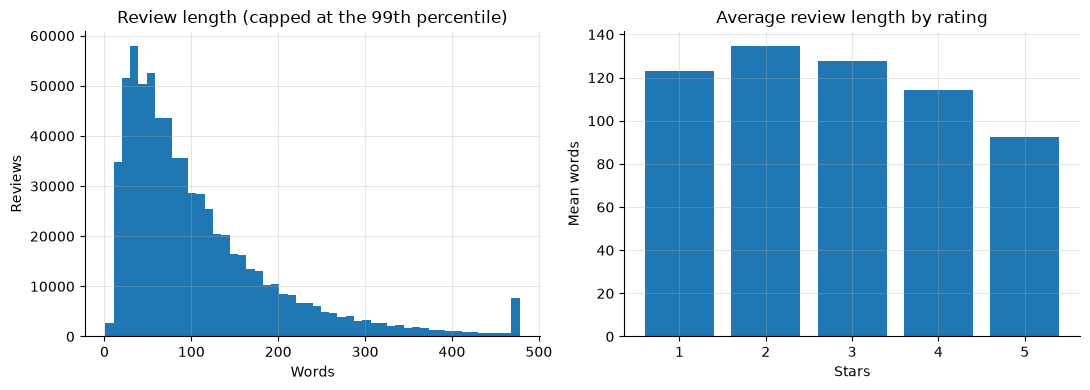

Median words: 81.0 | 99th percentile: 478.0
stars
1    123.3
2    134.7
3    127.5
4    114.4
5     92.6


In [31]:
# Word count after cleaning; counting spaces avoids building a list of words for every review.
reviews['word_count'] = reviews['clean_text'].str.count(' ') + 1
cap = reviews['word_count'].quantile(0.99)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(reviews['word_count'].clip(upper=cap), bins=50, color='tab:blue')
axes[0].set(title='Review length (capped at the 99th percentile)', xlabel='Words', ylabel='Reviews')
mean_length = reviews.groupby('stars')['word_count'].mean()
axes[1].bar(mean_length.index.astype(str), mean_length.values, color='tab:blue')
axes[1].set(title='Average review length by rating', xlabel='Stars', ylabel='Mean words')
plt.tight_layout()
plt.show()

print('Median words:', reviews['word_count'].median(), '| 99th percentile:', cap)
print(mean_length.round(1).to_string())

**What to notice — review lengths.** A long right tail means most reviews are shorter, while a few are much longer. Differences in length by rating do not necessarily mean long reviews have more reliable sentiment.

**Review lengths.** The first plot shows the distribution of review word counts, capped at the 99th percentile only for display; no long reviews are deleted. The second compares mean word counts across star ratings. Read the displayed medians and bar heights before stating that one rating group writes longer reviews than another; their exact lengths were not included in the uploaded notebook outputs.

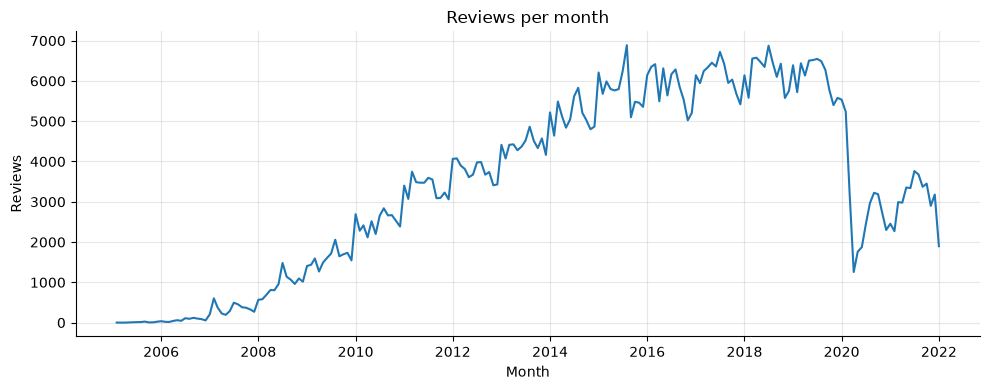

Busiest month: 2015-08 (6,887 reviews)
Busiest year: 2018 (74,861 reviews)
Last month in the data: 2022-01 (1,898 reviews, may be a partial month)


In [32]:
monthly = reviews.dropna(subset=['date']).set_index('date').resample('MS').size()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(monthly.index, monthly.values, color='tab:blue')
ax.set(title='Reviews per month', xlabel='Month', ylabel='Reviews')
plt.tight_layout()
plt.show()

yearly = reviews.dropna(subset=['date'])['date'].dt.year.value_counts().sort_index()
print('Busiest month:', monthly.idxmax().strftime('%Y-%m'), f'({monthly.max():,} reviews)')
print('Busiest year:', yearly.idxmax(), f'({yearly.max():,} reviews)')
print('Last month in the data:', monthly.index[-1].strftime('%Y-%m'), f'({monthly.iloc[-1]:,} reviews, may be a partial month)')

**What to notice — time trend.** A trend in the number of Yelp reviews is not the same as a trend in restaurant sales. Platform use and the number of reviewed businesses can also change over time.

**Review activity over time.** The line represents the number of Yelp reviews per month among selected businesses, not monthly customer visits or sales. Increases and decreases may reflect changes in Yelp usage, the number of businesses reviewed, or data coverage. The final month may be incomplete; avoid treating it as a full-month decline.

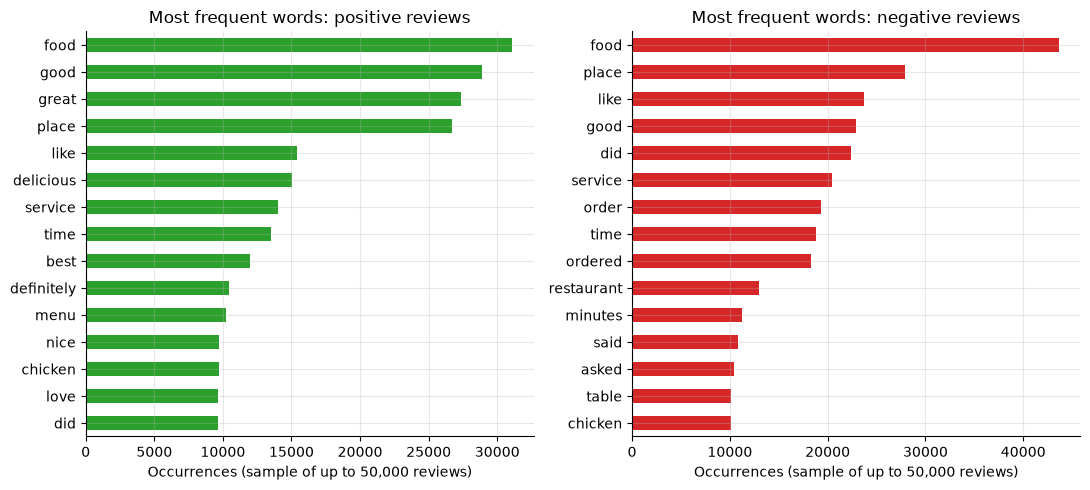

In the positive top 15 only: ['great', 'delicious', 'best', 'definitely', 'menu', 'nice', 'love']
In the negative top 15 only: ['order', 'ordered', 'restaurant', 'minutes', 'said', 'asked', 'table']


In [33]:
# Frequent words with standard stopwords removed (negations are removed here too; this is for reading only).
EDA_STOPWORDS = sorted(ENGLISH_STOP_WORDS | {'just', 'really', 'got', 'went', 'came'})


def top_words(texts, n=15):
    counter = CountVectorizer(stop_words=EDA_STOPWORDS, min_df=5)
    counts = counter.fit_transform(texts)
    totals = np.asarray(counts.sum(axis=0)).ravel()
    return pd.Series(totals, index=counter.get_feature_names_out()).nlargest(n)


word_sample = {}
for label in ['Positive', 'Negative']:
    texts = reviews.loc[star_sentiment == label, 'clean_text']
    word_sample[label] = top_words(texts.sample(min(50_000, len(texts)), random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for axis, label in zip(axes, ['Positive', 'Negative']):
    word_sample[label].sort_values().plot.barh(ax=axis, color=SENT_COLORS[label])
    axis.set(title=f'Most frequent words: {label.lower()} reviews', xlabel='Occurrences (sample of up to 50,000 reviews)')
plt.tight_layout()
plt.show()

only_pos = [w for w in word_sample['Positive'].index if w not in word_sample['Negative'].index]
only_neg = [w for w in word_sample['Negative'].index if w not in word_sample['Positive'].index]
print('In the positive top 15 only:', only_pos)
print('In the negative top 15 only:', only_neg)

**What to notice — frequent words.** The common words help show topics customers mention. They do not by themselves prove satisfaction or dissatisfaction: words like *food* or *service* can occur in positive and negative contexts.

**Frequent words.** These plots compare words from equal-size samples of positive and negative reviews. Generic terms appearing in both groups cannot by themselves reveal a customer complaint; inspect the words appearing mostly in negative reviews and the original example texts. Word frequency is descriptive and does not replace the classifier or NMF topic analysis.

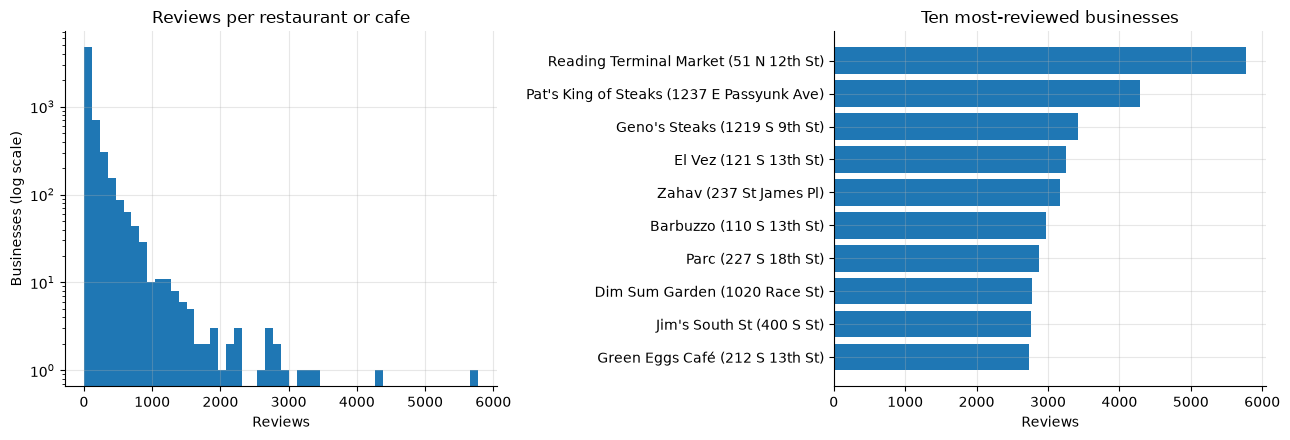

Businesses with reviews: 6174 | selected businesses with no reviews: 0
Median reviews per business: 38.0 | maximum: 5769
Share of businesses with fewer than 10 reviews: 15.5 %


In [34]:
per_business = reviews.groupby('business_id').size()
names = philly.set_index('business_id')
top10 = per_business.nlargest(10)
labels = [f"{names.loc[b, 'name']} ({str(names.loc[b, 'address'])[:28]})" for b in top10.index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(per_business, bins=50, color='tab:blue')
axes[0].set_yscale('log')
axes[0].set(title='Reviews per restaurant or cafe', xlabel='Reviews', ylabel='Businesses (log scale)')
axes[1].barh(labels[::-1], top10.values[::-1], color='tab:blue')
axes[1].set(title='Ten most-reviewed businesses', xlabel='Reviews')
plt.tight_layout()
plt.show()

print('Businesses with reviews:', len(per_business), '| selected businesses with no reviews:', len(philly) - len(per_business))
print('Median reviews per business:', per_business.median(), '| maximum:', per_business.max())
print('Share of businesses with fewer than 10 reviews:', round((per_business < 10).mean() * 100, 1), '%')

**What to notice — reviews per business.** Look at the median and largest review counts together. If a few restaurants contribute a large share of reviews, they may dominate pooled sentiment statistics. The competitor function reports the number of contributing businesses as well as reviews.

**Reviews by business.** The histogram shows whether reviews are concentrated among a few restaurants, and the right chart names the ten most-reviewed businesses in the cleaned selection. High review count is a measure of Yelp activity, not proof of profitability or success. The median and maximum printed above quantify the difference between typical and highly reviewed businesses.

## M2-7. Sentiment labels and class distribution
Labels come from the Yelp star rating: 1–2 stars Negative, 3 stars Neutral, 4–5 stars Positive. For the supervised task, Negative = 0 and Positive = 1. **Neutral reviews are excluded from training** because a 3-star review mixes praise and complaints and has no clear sign; including it would blur the two classes. Neutral reviews are still counted in all descriptive statistics (M2-16).

The stars are only used to build the label. The model sees only the review text.

The cleaned dataset is large, so a random sample of `SAMPLE_SIZE` binary reviews is used for model training and comparison. A simple random sample keeps the class proportions close to the full data, which the table below checks.

In [35]:
reviews['sentiment'] = stars_to_sentiment(reviews['stars'])
class_table = reviews['sentiment'].value_counts().reindex(SENT_ORDER).to_frame('reviews')
class_table['percent'] = (class_table['reviews'] / class_table['reviews'].sum() * 100).round(2)
display(class_table)

binary = reviews[reviews['sentiment'] != 'Neutral'].copy()
binary['label'] = (binary['sentiment'] == 'Positive').astype(int)   # Negative = 0, Positive = 1

if SAMPLE_SIZE is not None and len(binary) > SAMPLE_SIZE:
    model_data = binary.sample(SAMPLE_SIZE, random_state=RANDOM_STATE)
else:
    model_data = binary
share = pd.DataFrame({'all binary reviews (%)': binary['label'].value_counts(normalize=True).mul(100).round(2),
                      'modeling sample (%)': model_data['label'].value_counts(normalize=True).mul(100).round(2)})
share.index = share.index.map({0: 'Negative (0)', 1: 'Positive (1)'})
print(f'Binary reviews: {len(binary):,} | used for modeling: {len(model_data):,} | businesses in sample: {model_data["business_id"].nunique():,}')
display(share)

,reviews,percent
sentiment,,
Negative,126663,18.0
Neutral,93562,13.3
Positive,483359,68.7


Binary reviews: 610,022 | used for modeling: 100,000 | businesses in sample: 5,637


,all binary reviews (%),modeling sample (%)
label,,
Positive (1),79.24,79.3
Negative (0),20.76,20.7


**What to notice — labels.** The binary model uses 1–2 star reviews as negative and 4–5 as positive. Three-star reviews stay in the descriptive analysis but are left out of binary training. The sample used for modeling should be compared against the full binary dataset for class balance.

**Binary model sample.** Three-star reviews are kept for the business-level descriptive summary but excluded from the positive-versus-negative supervised task. In the displayed local run, the modeling sample included 100,000 reviews, of which about 20.8% were negative. This is a sampled subset of binary reviews; the full review distribution was 18.0% negative, 13.3% neutral, and 68.7% positive.

## M2-8. Train, validation and test split
The split is 60% / 20% / 20% by **business**, not by review, using `GroupShuffleSplit` on `business_id`. Reviews of the same restaurant share vocabulary (dish names, staff names), so a review-level split would let the model recognize restaurants rather than learn sentiment. Because businesses have very different numbers of reviews, the review percentages are only approximately 60/20/20. The test set is not used for tuning or model selection.

In [36]:
outer = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_val_pos, test_pos = next(outer.split(model_data, groups=model_data['business_id']))
train_val = model_data.iloc[train_val_pos]
test = model_data.iloc[test_pos]

inner = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=RANDOM_STATE)   # 25% of the remaining 80% = 20% overall
train_pos, val_pos = next(inner.split(train_val, groups=train_val['business_id']))
train, validation = train_val.iloc[train_pos], train_val.iloc[val_pos]

train_ids, val_ids, test_ids = (set(d['business_id']) for d in (train, validation, test))
assert not (train_ids & val_ids) and not (train_ids & test_ids) and not (val_ids & test_ids)
print('No business appears in more than one split.')

split_table = pd.DataFrame({
    'reviews': [len(train), len(validation), len(test)],
    'review_percent': [round(len(d) / len(model_data) * 100, 1) for d in (train, validation, test)],
    'businesses': [len(train_ids), len(val_ids), len(test_ids)],
    'positive_percent': [round(d['label'].mean() * 100, 1) for d in (train, validation, test)]},
    index=['train', 'validation', 'test'])
display(split_table)

X_train, y_train = train['clean_text'], train['label']
X_val, y_val = validation['clean_text'], validation['label']
X_test, y_test = test['clean_text'], test['label']
CLASS_NAMES = ['Negative', 'Positive']

No business appears in more than one split.


,reviews,review_percent,businesses,positive_percent
train,60151,60.2,3381,79.7
validation,20610,20.6,1128,78.0
test,19239,19.2,1128,79.6


**What to notice — data split.** Each business ID appears in exactly one split. This evaluates generalization to reviews from *different businesses*. The percentages of reviews may not be exactly 60/20/20 because restaurants contribute different numbers of reviews.

## M2-9. TF-IDF and NLP pipelines
Machine learning models need numbers, not strings, so each review has to be turned into a numeric vector. TF-IDF builds one column per word or word pair in the vocabulary. A cell holds the term frequency (how often the term appears in the review) multiplied by the inverse document frequency (lower for terms that appear in many reviews). Common words such as "the" get small weights, and distinctive words such as "rude" or "delicious" get large ones. This suits sentiment classification because the class is largely decided by a small set of strongly polar terms and phrases, and it works well with linear models on sparse data.

Settings: unigrams and bigrams (`ngram_range=(1, 2)`, so "not good" is a feature), `min_df=5` to drop very rare terms, `max_features=20000` to keep the vocabulary manageable, and `sublinear_tf=True` to damp very repeated words.

TF-IDF is part of a scikit-learn `Pipeline` together with the classifier. When the pipeline is fitted, the vocabulary and IDF weights are learned from the training reviews only; validation and test text is only transformed. Inside cross-validation, the vectorizer is refitted on each training fold, so no held-out text influences it.

In [ ]:
def make_pipeline(classifier, memory=None):
    tfidf = TfidfVectorizer(max_features=20000, min_df=5, ngram_range=(1, 2), sublinear_tf=True)
    return Pipeline([('tfidf', tfidf), ('clf', classifier)], memory=memory)


def predict_with_threshold(model, texts, threshold=0.5):
    # Positive when P(positive) >= threshold; 0.5 reproduces model.predict for these classifiers.
    return (model.predict_proba(texts)[:, 1] >= threshold).astype(int)


def score_split(model, texts, labels, threshold=0.5):
    predicted = predict_with_threshold(model, texts, threshold)
    return {'accuracy': accuracy_score(labels, predicted),
            'precision': precision_score(labels, predicted, average='macro'),
            'recall': recall_score(labels, predicted, average='macro'),
            'f1': f1_score(labels, predicted, average='macro')}


def show_validation(name, model, plot_matrix=True):
    predicted = model.predict(X_val)
    print(f'{name}: classification report (validation)')
    print(classification_report(y_val, predicted, target_names=CLASS_NAMES, digits=3))
    if plot_matrix:
        ConfusionMatrixDisplay.from_predictions(y_val, predicted, display_labels=CLASS_NAMES, cmap='Blues', colorbar=False)
        plt.title(f'{name}: validation confusion matrix')
        plt.grid(False)
        plt.show()
    return score_split(model, X_val, y_val)

## M2-10. Naive Bayes
Multinomial Naive Bayes with default settings, trained on the training set. Precision, recall and F1 in the tables are **macro averages** (the mean of the negative-class and positive-class scores). Macro averaging is used because the negative class is the smaller one and is the class that matters for complaint analysis; plain accuracy would be dominated by the positive class. The per-class numbers are in the classification report.

**Class imbalance.** The class table in M2-7 shows how many more positive than negative reviews there are. If the imbalance is clear, a model that favors the majority class can reach a high accuracy while missing many negative reviews, so the validation recall of the negative class is the figure to watch. Weighting is tried for Logistic Regression in M2-12 and kept only if it improves validation results; undersampling or oversampling are not used.

Naive Bayes (default): classification report (validation)
              precision    recall  f1-score   support

    Negative      0.913     0.748     0.823      4544
    Positive      0.932     0.980     0.955     16066

    accuracy                          0.929     20610
   macro avg      0.923     0.864     0.889     20610
weighted avg      0.928     0.929     0.926     20610



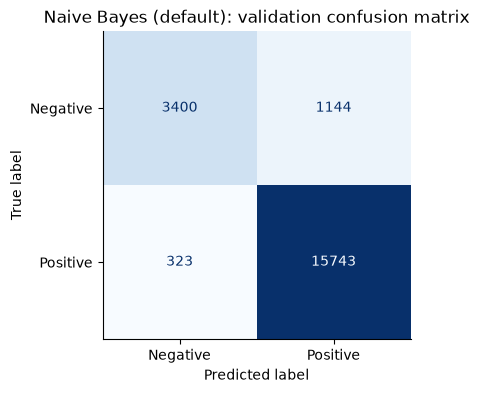

In [38]:
nb_default = make_pipeline(MultinomialNB())
nb_default.fit(X_train, y_train)
nb_default_scores = show_validation('Naive Bayes (default)', nb_default)

**What to notice — Naive Bayes.** Read precision and recall for both labels, especially the negative class. Accuracy alone can look high when positive reviews dominate. The confusion matrix shows whether more negative reviews are incorrectly predicted as positive or vice versa.

## M2-11. Logistic Regression
Logistic Regression with default regularization (`C=1`), same pipeline and features. The `liblinear` solver is used because it is fast on sparse TF-IDF matrices.

Logistic Regression (default): classification report (validation)
              precision    recall  f1-score   support

    Negative      0.945     0.838     0.888      4544
    Positive      0.956     0.986     0.971     16066

    accuracy                          0.953     20610
   macro avg      0.950     0.912     0.929     20610
weighted avg      0.953     0.953     0.952     20610



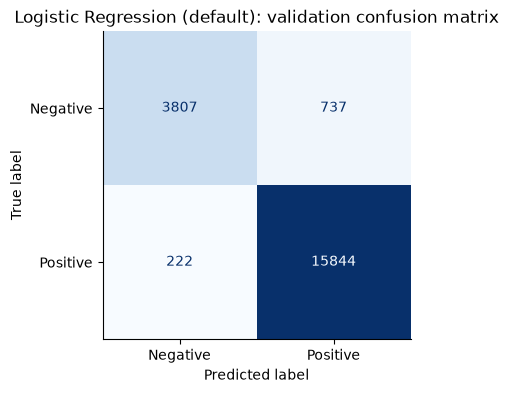

In [39]:
lr_default = make_pipeline(LogisticRegression(solver='liblinear', random_state=RANDOM_STATE))
lr_default.fit(X_train, y_train)
lr_default_scores = show_validation('Logistic Regression (default)', lr_default)

**What to notice — Logistic Regression.** Compare its **macro F1** against Naive Bayes on the same validation reviews. Macro F1 weights the positive and negative classes equally, making it more useful than accuracy alone for this imbalanced task.

## M2-12. Model comparison and tuning
A small grid search is run for each model on the **training set only**, using 3-fold cross-validation with folds split by business (`GroupKFold`). The TF-IDF step is refitted inside each fold. The score used is macro F1.

- Naive Bayes: smoothing `alpha` in 0.1, 0.3, 1.0.
- Logistic Regression: regularization `C` in 0.3, 1, 3, 10, and `class_weight` either `None` or `balanced`. The weighted version is only worth keeping if it improves validation results, since it trades precision on the positive class for recall on the negative class.

The tuned models and the default models are then compared on the validation set in one table. The best row by validation macro F1 is the model carried forward. Validation and test sets are not used inside the grid search.

In [ ]:
def tune(classifier, param_grid):
    # The cache only avoids refitting TF-IDF for every classifier setting; it is removed afterwards.
    with tempfile.TemporaryDirectory() as cache_dir:
        search = GridSearchCV(make_pipeline(classifier, memory=cache_dir), param_grid,
                              scoring='f1_macro', cv=GroupKFold(n_splits=3), n_jobs=1)
        search.fit(X_train, y_train, groups=train['business_id'])
    search.best_estimator_.set_params(memory=None)
    return search


nb_search = tune(MultinomialNB(), {'clf__alpha': [0.1, 0.3, 1.0]})
# (enhanced) vocabulary size is tuned too: 20k (original) vs 100k unigrams+bigrams.
lr_search = tune(LogisticRegression(solver='liblinear', random_state=RANDOM_STATE, max_iter=1000),
                 {'clf__C': [3, 10, 30], 'clf__class_weight': [None, 'balanced'], 'tfidf__max_features': [20000, 100000]})
# (enhanced) linear SVM, calibrated so it still gives probabilities for the Streamlit page.
svm_search = tune(CalibratedClassifierCV(LinearSVC(random_state=RANDOM_STATE), cv=3),
                  {'clf__estimator__C': [0.1, 0.3, 1], 'tfidf__max_features': [20000, 100000]})

for name, search in [('Naive Bayes', nb_search), ('Logistic Regression', lr_search), ('Linear SVM (calibrated)', svm_search)]:
    cv_table = pd.DataFrame(search.cv_results_)[['params', 'mean_test_score', 'std_test_score']]
    print(f'{name}: cross-validation macro F1 on the training set')
    display(cv_table.sort_values('mean_test_score', ascending=False).round(4))

nb_tuned, lr_tuned = nb_search.best_estimator_, lr_search.best_estimator_
nb_tuned_scores = show_validation('Naive Bayes (tuned)', nb_tuned, plot_matrix=False)
lr_tuned_scores = show_validation('Logistic Regression (tuned)', lr_tuned, plot_matrix=False)
svm_tuned = svm_search.best_estimator_
svm_tuned_scores = show_validation('Linear SVM (calibrated, tuned)', svm_tuned, plot_matrix=False)

In [ ]:
fitted_models = {'Naive Bayes (default)': nb_default, 'Naive Bayes (tuned)': nb_tuned,
                 'Logistic Regression (default)': lr_default, 'Logistic Regression (tuned)': lr_tuned,
                 'Linear SVM (calibrated, tuned)': svm_tuned}
validation_scores = {'Naive Bayes (default)': nb_default_scores, 'Naive Bayes (tuned)': nb_tuned_scores,
                     'Logistic Regression (default)': lr_default_scores, 'Logistic Regression (tuned)': lr_tuned_scores,
                     'Linear SVM (calibrated, tuned)': svm_tuned_scores}
settings = {'Naive Bayes (default)': 'alpha=1.0', 'Naive Bayes (tuned)': str(nb_search.best_params_),
            'Logistic Regression (default)': 'C=1.0, class_weight=None', 'Logistic Regression (tuned)': str(lr_search.best_params_),
            'Linear SVM (calibrated, tuned)': str(svm_search.best_params_)}
cv_scores = {'Naive Bayes (tuned)': nb_search.best_score_, 'Logistic Regression (tuned)': lr_search.best_score_,
             'Linear SVM (calibrated, tuned)': svm_search.best_score_}

comparison = pd.DataFrame([
    {'model': name, 'settings': settings[name], 'cv_f1_macro': cv_scores.get(name, np.nan),
     **{f'val_{metric}': value for metric, value in scores.items()}}
    for name, scores in validation_scores.items()])
display(comparison.round(4))

final_name = comparison.loc[comparison['val_f1'].idxmax(), 'model']
final_model = fitted_models[final_name]
print('Selected by validation macro F1:', final_name)

### M2-12b. Decision threshold (enhanced)
With 79% positive reviews, the default 0.5 probability cut-off favours the positive class. The threshold that maximises **validation** macro F1 is chosen on a grid from 0.20 to 0.80 and then fixed; the test set is not used. It is saved with the model so the app can use it.

In [ ]:
val_probability = final_model.predict_proba(X_val)[:, 1]
threshold_grid = np.round(np.arange(0.20, 0.81, 0.02), 2)
threshold_table = pd.DataFrame({'threshold': threshold_grid,
                                'val_f1_macro': [f1_score(y_val, (val_probability >= t).astype(int), average='macro') for t in threshold_grid]})
DECISION_THRESHOLD = float(threshold_table.loc[threshold_table['val_f1_macro'].idxmax(), 'threshold'])
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(threshold_table['threshold'], threshold_table['val_f1_macro'], marker='o', color='tab:blue')
ax.axvline(0.5, color='tab:gray', ls='--', label='default 0.5')
ax.axvline(DECISION_THRESHOLD, color='tab:red', ls='--', label=f'selected {DECISION_THRESHOLD:.2f}')
ax.set(title='Validation macro F1 by decision threshold', xlabel='P(positive) threshold', ylabel='macro F1'); ax.legend()
plt.tight_layout(); plt.show()
print(f'Validation macro F1 at 0.50: {score_split(final_model, X_val, y_val)["f1"]:.4f} | '
      f'at {DECISION_THRESHOLD:.2f}: {score_split(final_model, X_val, y_val, DECISION_THRESHOLD)["f1"]:.4f}')

**What to notice — tuning and model selection.** The table compares two model families and their tuned versions on the same validation split. The final model is selected by validation macro F1; the test results must not be used to choose the model or change its hyperparameters.

**Model selection.** The local run selected **tuned Logistic Regression**, with validation macro F1 of approximately **0.943**. The comparison table immediately above should be used to describe how close Naive Bayes and default Logistic Regression were; those row-by-row numbers were not included in the uploaded notebook. The selected model comes from validation macro F1, not the test result.

## M2-13. Final test evaluation
The selected model is evaluated once on the test set. It was trained on the training set only (it was not refitted on training plus validation), so the test result describes exactly the model that is saved. The accuracy of always predicting the majority class is shown for context.

In [ ]:
test_scores = score_split(final_model, X_test, y_test, DECISION_THRESHOLD)
test_predicted = predict_with_threshold(final_model, X_test, DECISION_THRESHOLD)
majority_accuracy = max(y_test.mean(), 1 - y_test.mean())

print(f'{final_name}: classification report (test)')
print(classification_report(y_test, test_predicted, target_names=CLASS_NAMES, digits=3))
ConfusionMatrixDisplay.from_predictions(y_test, test_predicted, display_labels=CLASS_NAMES, cmap='Blues', colorbar=False)
plt.title(f'{final_name}: test confusion matrix')
plt.grid(False)
plt.show()

test_metrics = pd.DataFrame([{'model': final_name, 'test_reviews': len(test), 'test_businesses': len(test_ids),
                              'accuracy': test_scores['accuracy'], 'precision_macro': test_scores['precision'],
                              'recall_macro': test_scores['recall'], 'f1_macro': test_scores['f1'],
                              'majority_class_accuracy': majority_accuracy, 'decision_threshold': DECISION_THRESHOLD}])
display(test_metrics.round(4))

**What to notice — test results.** Check whether the test macro F1 is close to validation macro F1 and inspect negative-class recall in the confusion matrix. A reported test accuracy of 0.964 is accuracy at recovering **star-derived sentiment labels**, not a predicted success rate for a new business.

### Overfitting check — train, validation and test

We measure macro F1 on all three splits using the **same selected model**. High training performance alone is not an error, but a much higher training score than validation suggests overfitting. Validation and test should also be broadly similar. This check does not retrain or retune the model.

In [ ]:
train_scores = score_split(final_model, X_train, y_train, DECISION_THRESHOLD)
validation_selected_scores = score_split(final_model, X_val, y_val, DECISION_THRESHOLD)
# test_scores was calculated above on the held-out test set.
overfitting_table = pd.DataFrame([
    {'split': 'Train', 'reviews': len(train), **train_scores},
    {'split': 'Validation', 'reviews': len(validation), **validation_selected_scores},
    {'split': 'Test', 'reviews': len(test), **test_scores}
]).set_index('split')
display(overfitting_table.round(4))

train_val_gap = train_scores['f1'] - validation_selected_scores['f1']
val_test_gap = validation_selected_scores['f1'] - test_scores['f1']
print(f'Train minus validation macro F1: {train_val_gap:+.3f}')
print(f'Validation minus test macro F1: {val_test_gap:+.3f}')
if train_val_gap > 0.05:
    print('Training is noticeably stronger than validation: investigate possible overfitting.')
elif train_val_gap > 0.02:
    print('Some train/validation gap exists, but it is not severe by itself.')
else:
    print('There is no large train/validation macro-F1 gap in this run.')
print('Also inspect the per-class metrics. A small F1 gap does not rule out all dataset biases.')


**What to notice — overfitting.** The previous local screenshot showed **0.943 validation macro F1** and **0.964 test accuracy**. Those are different metrics, so they cannot be directly compared to judge overfitting. The table above compares **macro F1 with macro F1** across splits. A clear claim requires the actual train score and the full test macro F1 after running this cell. Strong generalization on Yelp review labels still does not establish new-business prediction accuracy.

**Test evaluation.** The locally displayed test accuracy was **0.964** for tuned Logistic Regression. The precise test macro F1 and the per-class precision/recall should be copied from the test report above after rerunning; the screenshot cut off part of that output. Compare accuracy with the majority-class baseline printed in the metrics table. Because labels come from Yelp stars, the classifier predicts **rating-derived polarity from review text**, not independently verified emotion or business success.

## M2-14. Misclassification analysis
Examples from the test set: correctly classified reviews, and the most confident wrong predictions in each direction. The table of error rates by star rating shows where the model struggles.

In [44]:
test_errors = test.copy()
test_errors['predicted'] = test_predicted
test_errors['prob_positive'] = final_model.predict_proba(X_test)[:, 1]
test_errors['correct'] = test_errors['predicted'] == test_errors['label']
label_name = {0: 'Negative', 1: 'Positive'}


def show_examples(frame, title):
    print('=' * 10, title)
    for _, row in frame.iterrows():
        print(f"[true {label_name[row['label']]}, predicted {label_name[row['predicted']]}, "
              f"{row['stars']} stars, P(positive)={row['prob_positive']:.2f}]")
        print(' '.join(str(row['review_text']).split())[:300])
        print()


correct = test_errors[test_errors['correct']]
show_examples(correct.groupby('label').sample(2, random_state=RANDOM_STATE), 'Correctly classified')
wrong = test_errors[~test_errors['correct']]
show_examples(wrong[wrong['label'] == 1].nsmallest(3, 'prob_positive'), 'Positive reviews predicted negative (most confident errors)')
show_examples(wrong[wrong['label'] == 0].nlargest(3, 'prob_positive'), 'Negative reviews predicted positive (most confident errors)')

error_by_stars = test_errors.groupby('stars')['correct'].agg(reviews='size', error_rate=lambda s: 1 - s.mean())
display(error_by_stars.round(3))
words = test_errors['clean_text'].str.count(' ') + 1
print('Median words, correct vs wrong:', words[test_errors['correct']].median(), 'vs', words[~test_errors['correct']].median())
has_but = test_errors['clean_text'].str.contains(r'\b(?:but|however)\b')
print('Share containing "but" or "however", correct vs wrong:',
      round(has_but[test_errors['correct']].mean() * 100, 1), '% vs', round(has_but[~test_errors['correct']].mean() * 100, 1), '%')

========== Correctly classified
[true Negative, predicted Negative, 2 stars, P(positive)=0.13]
Deeply disappointing. I have been here many times before and loved the experience but today was boring and unfulfilling. I had the monkey french toast and instead of sauteed bananas i had plain old bananas sandwiched between room temperature french toast. I did ask them to hold the caramel sauce and

[true Negative, predicted Negative, 1 stars, P(positive)=0.08]
They get crafty with the bill and your tab will jump before you're eyes. Wait staff was rude as well. Ton of great places in a one block radius, all more worth your time and money. Skip this place.

[true Positive, predicted Positive, 4 stars, P(positive)=1.00]
Review Summary: Ambience: 4/5 Food: 4.5/5 Service: 4/5 I had brunch with my friends here and had a wonderful time! The decor was really quaint and homey, the service equally welcoming. Although the entrance was narrow this place seemed to continue on forever in an endless maze 

,reviews,error_rate
stars,,
1,2139,0.057
2,1792,0.173
4,6152,0.029
5,9156,0.009


Median words, correct vs wrong: 77.0 vs 80.0
Share containing "but" or "however", correct vs wrong: 50.1 % vs 62.4 %


**What to notice — incorrect predictions.** Read both false positives and false negatives. Mixed praise and criticism, sarcasm, and short ambiguous reviews are useful cases to inspect. A review's text can legitimately disagree with its star rating.

**Error analysis.** The examples above distinguish true and predicted labels and show the original review text. Confident mistakes can occur in mixed reviews (praise plus criticism), sarcasm, short reviews, or cases where the written text does not reflect the star rating. The error-rate table indicates whether mistakes cluster near the 2-star and 4-star boundary. Do not conclude a particular error cause unless it is visible in the actual examples.

## M2-15. NMF topic modeling of complaints
NMF is applied to the TF-IDF matrix of **negative** reviews (1–2 stars). Each topic is a weighted set of words and each review gets a weight for every topic; a review is assigned to its highest-weight topic. Stopwords are removed here (the reading-oriented stopword list from M2-6), words in more than half of the reviews are dropped (`max_df=0.5`), and words in fewer than 10 reviews are dropped (`min_df=10`).

**Number of topics.** NMF does not choose the number of topics itself, and reconstruction error always falls as topics are added, so it cannot be used alone. Several values are fitted below and compared with a simple measure, topic diversity (the share of distinct words among each topic's top 10 words; low values mean topics repeat each other). `N_TOPICS = 6` is the starting choice: small enough to read and describe, large enough to separate different complaints. Change it to another tested value if the topics below look merged or duplicated.

The topics are whatever the reviews produce. They show recurring review themes; they are not by themselves business opportunities.

In [45]:
negative_all = reviews[reviews['sentiment'] == 'Negative'].copy()
nmf_sample = negative_all.sample(min(NMF_SAMPLE, len(negative_all)), random_state=RANDOM_STATE)
topic_vectorizer = TfidfVectorizer(stop_words=EDA_STOPWORDS, max_df=0.5, min_df=10, max_features=5000)
topic_matrix = topic_vectorizer.fit_transform(nmf_sample['clean_text'])
terms = topic_vectorizer.get_feature_names_out()
print('Negative reviews:', len(negative_all), '| used to fit the topic model:', len(nmf_sample), '| vocabulary size:', len(terms))


def top_terms(nmf_model, n=10):
    return [[terms[i] for i in row.argsort()[::-1][:n]] for row in nmf_model.components_]


trial_models, trial_rows = {}, []
for k in [4, 6, 8, 10]:
    trial = NMF(n_components=k, init='nndsvda', random_state=RANDOM_STATE, max_iter=400)
    trial.fit(topic_matrix)
    trial_models[k] = trial
    unique_words = len({word for topic_words in top_terms(trial) for word in topic_words})
    trial_rows.append({'topics': k, 'reconstruction_error': trial.reconstruction_err_, 'topic_diversity': unique_words / (10 * k)})
display(pd.DataFrame(trial_rows).round(3))

N_TOPICS = 6
nmf_model = trial_models[N_TOPICS]

Negative reviews: 126663 | used to fit the topic model: 30000 | vocabulary size: 5000


,topics,reconstruction_error,topic_diversity
0,4,169.321,0.775
1,6,168.671,0.883
2,8,168.169,0.862
3,10,167.688,0.830


In [ ]:
# Names chosen after reading each topic's top words and representative reviews in Member 2's run.
# They are only valid for this topic order (N_TOPICS = 6, random_state = 42); check them if the topics change.
TOPIC_NAMES = {0: 'Service & staff attitude', 1: 'Food taste & quality', 2: 'Pizza quality',
               3: 'Orders, delivery & phone', 4: 'Cheesesteaks & sandwiches', 5: 'Wait times & table service'}
topic_words = top_terms(nmf_model)
topic_labels = {k: f'Topic {k}: ' + TOPIC_NAMES.get(k, ', '.join(topic_words[k][:3])) for k in range(N_TOPICS)}

# Assign every negative review (not only the fitting sample) to its strongest topic.
weights = nmf_model.transform(topic_vectorizer.transform(negative_all['clean_text']))
negative_all['topic_id'] = np.where(weights.sum(axis=1) > 0, weights.argmax(axis=1), -1)   # -1: no topic vocabulary words
negative_all['topic_weight'] = weights.max(axis=1)
classified = negative_all[negative_all['topic_id'] >= 0]
print(f'{len(classified):,} of {len(negative_all):,} negative reviews assigned to a topic '
      f'({len(negative_all) - len(classified):,} had no words from the topic vocabulary)')

topic_counts = classified['topic_id'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh([topic_labels[k] for k in topic_counts.index][::-1], topic_counts.values[::-1], color='tab:red')
ax.set(title='Complaint topics (negative reviews)', xlabel='Negative reviews')
plt.tight_layout()
plt.show()

complaint_rows = []
for k in range(N_TOPICS):
    best = classified[classified['topic_id'] == k].nlargest(2, 'topic_weight')
    print(f'{topic_labels[k]}')
    print('  Top words:', ', '.join(topic_words[k]))
    print(f'  Reviews: {topic_counts.get(k, 0):,} ({topic_counts.get(k, 0) / len(classified) * 100:.1f}% of assigned)')
    for text in best['review_text']:
        print('  Example:', ' '.join(str(text).split())[:250])
    complaint_rows.append({'topic_id': k, 'topic_label': topic_labels[k], 'top_words': ', '.join(topic_words[k]),
                           'negative_reviews': int(topic_counts.get(k, 0)),
                           'share_pct': round(topic_counts.get(k, 0) / len(classified) * 100, 2),
                           'representative_review': ' '.join(str(best['review_text'].iloc[0]).split())[:500] if len(best) else ''})
    print()
complaint_topics = pd.DataFrame(complaint_rows)
topic_bundle = {'tfidf': topic_vectorizer, 'nmf': nmf_model, 'topic_labels': topic_labels, 'top_words': topic_words}

**What to notice — complaint topics.** NMF groups negative reviews by frequently co-occurring terms, not by proven customer problems. Inspect representative reviews before renaming a topic. Generic terms such as *place* or food items such as *pizza* should not automatically be labeled *poor service* or *bad food*.

**Topic interpretation.** The previously displayed six topic keyword labels were `place/service/good`, `chicken/ordered/sauce`, `pizza/crust/sauce`, `order/delivery/called`, `cheese/steak/sandwich`, and `table/minutes/did`. These are **unsupervised word groups**, not six confirmed complaint types. `order/delivery/called` may capture delivery issues, and `table/minutes/did` may relate to waits, but the representative negative reviews printed above must confirm that. `place/service/good` is too generic to label a specific weakness without further checking. The topic sizes shown in the screenshot were 34,540; 27,768; 6,527; 16,477; 14,262; and 27,078 assigned negative reviews, respectively, in topic order 0–5. They indicate frequency among assigned negative reviews, not customer-demand or failure probabilities.

## M2-16. Business-level sentiment and complaint summary
One row per selected business, built from **all** cleaned reviews (not the modeling sample). Percentages are the original star-rating groups (1–2, 3, 4–5) divided by the number of analyzed reviews for that business; they are descriptive statistics and not model predictions. Counts are kept next to the percentages so they can be re-aggregated correctly (for example when pooling nearby businesses).

Businesses with no reviews keep a row with `reviews_analyzed = 0` and empty rating and percentage fields. They are not filled with zeros or averages. The most common complaint topic is only filled when a business has at least `MIN_COMPLAINTS` complaints assigned to a topic.

In [47]:
sentiment_counts_by_business = (pd.crosstab(reviews['business_id'], reviews['sentiment'])
                                .reindex(columns=SENT_ORDER, fill_value=0)
                                .rename(columns={'Positive': 'positive_reviews', 'Neutral': 'neutral_reviews', 'Negative': 'negative_reviews'}))
rating_by_business = reviews.groupby('business_id').agg(reviews_analyzed=('stars', 'size'), avg_rating=('stars', 'mean'))

nlp_summary = (philly.merge(rating_by_business, on='business_id', how='left')
                     .merge(sentiment_counts_by_business, on='business_id', how='left'))
count_columns = ['reviews_analyzed', 'positive_reviews', 'neutral_reviews', 'negative_reviews']
nlp_summary[count_columns] = nlp_summary[count_columns].fillna(0).astype(int)

denominator = nlp_summary['reviews_analyzed'].replace(0, np.nan)    # no reviews -> percentages stay empty
for kind in ['positive', 'neutral', 'negative']:
    nlp_summary[f'{kind}_pct'] = (nlp_summary[f'{kind}_reviews'] / denominator * 100).round(2)

# Complaint topics per business, plus one example review for each business and topic.
topic_counts_by_business = (classified.groupby(['business_id', 'topic_id']).size().rename('negative_reviews').reset_index())
example_by_business_topic = (classified.sort_values('topic_weight', ascending=False)
                             .drop_duplicates(['business_id', 'topic_id'])[['business_id', 'topic_id', 'stars', 'review_text']])
business_topics = topic_counts_by_business.merge(example_by_business_topic, on=['business_id', 'topic_id'])
business_topics['topic_label'] = business_topics['topic_id'].map(topic_labels)
business_topics['example_review'] = business_topics['review_text'].map(lambda text: ' '.join(str(text).split())[:400])
business_topics = business_topics.rename(columns={'stars': 'example_stars'}).drop(columns='review_text')

top_topic = business_topics.sort_values(['business_id', 'negative_reviews'], ascending=[True, False]).drop_duplicates('business_id')
classified_complaints = business_topics.groupby('business_id')['negative_reviews'].sum()
top_topic = top_topic[top_topic['business_id'].map(classified_complaints) >= MIN_COMPLAINTS]
top_topic = top_topic[['business_id', 'topic_label', 'negative_reviews']].rename(
    columns={'topic_label': 'top_complaint_topic', 'negative_reviews': 'top_complaint_reviews'})
nlp_summary = nlp_summary.merge(top_topic, on='business_id', how='left')

# Checks: one row per business, counts add up, percentages add to 100 where reviews exist.
assert nlp_summary['business_id'].is_unique and len(nlp_summary) == len(philly)
assert nlp_summary['reviews_analyzed'].sum() == len(reviews)
assert (nlp_summary[['positive_reviews', 'neutral_reviews', 'negative_reviews']].sum(axis=1) == nlp_summary['reviews_analyzed']).all()
has_reviews = nlp_summary['reviews_analyzed'] > 0
assert np.allclose(nlp_summary.loc[has_reviews, ['positive_pct', 'neutral_pct', 'negative_pct']].sum(axis=1), 100, atol=0.02)
assert nlp_summary.loc[~has_reviews, ['avg_rating', 'positive_pct', 'negative_pct']].isna().all().all()
print('Summary checks passed.')
print('Businesses:', len(nlp_summary), '| with reviews:', int(has_reviews.sum()), '| without reviews:', int((~has_reviews).sum()),
      '| with a top complaint topic:', int(nlp_summary['top_complaint_topic'].notna().sum()))
display(nlp_summary[has_reviews].sort_values('reviews_analyzed', ascending=False).head(8))

Summary checks passed.
Businesses: 6174 | with reviews: 6174 | without reviews: 0 | with a top complaint topic: 4054


,business_id,name,address,categories,latitude,longitude,is_open,valid_coordinates,reviews_analyzed,avg_rating,negative_reviews,neutral_reviews,positive_reviews,positive_pct,neutral_pct,negative_pct,top_complaint_topic,top_complaint_reviews
5851,ytynqOUb3hjKeJfRj5Tshw,Reading Terminal Market,51 N 12th St,"Candy Stores, Shopping, Department Stores, Fas...",39.953341,-75.158855,1,True,5769,4.605478,94,303,5372,93.12,5.25,1.63,"Topic 0: place, service, good",72.0
4665,PP3BBaVxZLcJU54uP_wL6Q,Pat's King of Steaks,1237 E Passyunk Ave,"Italian, American (Traditional), Sandwiches, F...",39.933201,-75.159266,1,True,4289,3.239916,1265,1004,2020,47.10,23.41,29.49,"Topic 4: cheese, steak, sandwich",1150.0
2368,IkY2ticzHEn4QFn8hQLSWg,Geno's Steaks,1219 S 9th St,"Sandwiches, Cheesesteaks, Steakhouses, Restaur...",39.933837,-75.158814,1,True,3425,2.532555,1806,765,854,24.93,22.34,52.73,"Topic 4: cheese, steak, sandwich",1614.0
5384,9PZxjhTIU7OgPIzuGi89Ew,El Vez,121 S 13th St,"Lounges, Bars, Nightlife, Breakfast & Brunch, ...",39.949702,-75.161770,1,True,3258,3.965930,293,563,2402,73.73,17.28,8.99,"Topic 0: place, service, good",114.0
1314,ctHjyadbDQAtUFfkcAFEHw,Zahav,237 St James Pl,"Nightlife, Bars, Food, Ethnic Food, Middle Eas...",39.946261,-75.145135,1,True,3168,4.549242,142,202,2824,89.14,6.38,4.48,"Topic 0: place, service, good",49.0
2658,6ajnOk0GcY9xbb5Ocaw8Gw,Barbuzzo,110 S 13th St,"Mediterranean, Restaurants, Pizza, Italian",39.950007,-75.162158,1,True,2969,4.266420,198,302,2469,83.16,10.17,6.67,"Topic 5: table, minutes, did",77.0
853,j-qtdD55OLfSqfsWuQTDJg,Parc,227 S 18th St,"Restaurants, French, Wine Bars, Nightlife, Ame...",39.949172,-75.170727,1,True,2879,4.146926,233,350,2296,79.75,12.16,8.09,"Topic 5: table, minutes, did",97.0
2185,AGlh4ZDv6jnoiYfz7At9mw,Dim Sum Garden,1020 Race St,"Chinese, Restaurants, Dim Sum, Asian Fusion, S...",39.955399,-75.156727,1,True,2772,3.884560,395,398,1979,71.39,14.36,14.25,"Topic 1: chicken, ordered, sauce",194.0


### M2-16b. Aspect-based sentiment (enhancement)
Overall polarity hides *what* customers like or dislike, so reviews are split into sentences. Each sentence is matched to seven aspects with a transparent keyword lexicon (food & taste, service & staff, wait time, price & value, ambience, cleanliness, delivery & orders) and scored with the selected sentiment pipeline. The result is a per-business table of how positive each aspect is, which the app aggregates around a location. Code: `src/businesslaunch/aspects.py`.

A sample of up to `ASPECT_SAMPLE` reviews per business keeps the run time reasonable.

In [ ]:
from businesslaunch.aspects import ASPECTS, score_aspects, summarize_aspects

ASPECT_SAMPLE = 30   # reviews per business
aspect_reviews = (reviews.groupby('business_id', group_keys=False)
                  .apply(lambda g: g.sample(min(len(g), ASPECT_SAMPLE), random_state=RANDOM_STATE)))
scored_aspects = score_aspects(aspect_reviews['review_text'].tolist(), final_model,
                               ids=aspect_reviews['business_id'].tolist(), threshold=DECISION_THRESHOLD)
scored_aspects = scored_aspects.rename(columns={'review_id': 'business_id'})
business_aspects = summarize_aspects(scored_aspects, group_col='business_id')
city_aspects = summarize_aspects(scored_aspects)
display(city_aspects.sort_values('positive_share').round(1))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(city_aspects.sort_values('positive_share')['aspect'], city_aspects.sort_values('positive_share')['positive_share'], color='tab:blue')
ax.set(title='Share of positive sentences per aspect (all sampled reviews)', xlabel='% positive mentions')
plt.tight_layout(); plt.show()

print(f'{len(scored_aspects):,} aspect mentions from {len(aspect_reviews):,} reviews; '
      f'{scored_aspects["business_id"].nunique():,} businesses.')
business_aspects.to_csv(M2_DIR / 'business_aspect_sentiment.csv', index=False)

**What to notice — business summary.** The output contains one row per business and keeps businesses with no matching reviews. The percentages are based on the **original star ratings**, rather than the sentiment classifier's predictions. No-review businesses must retain missing sentiment values, not fabricated zeros.

## M2-17. Geographic competitor review analysis
`analyze_location` takes a proposed latitude and longitude, a search radius in kilometers, an optional exact category (`Restaurants`, `Cafes` or `Coffee & Tea`), and an option to keep only businesses marked open in the dataset snapshot. It:

1. Finds existing businesses within the radius, using the haversine distance on businesses with usable coordinates.
2. Returns their names, distances, average ratings and sentiment proportions.
3. Pools the nearby reviews to give weighted averages (each business counts in proportion to its number of reviews).
4. Counts complaint topics among the nearby businesses and returns one example complaint per topic.
5. Writes plain summary lines and a list of possible points to investigate. Each statement is built from the numbers in the data, and a theme is only called out when it is clearly more common nearby than citywide.

The function only uses existing businesses. It does not assume anything about the proposed business, and it does not estimate success, revenue or demand. The code is written to `competitor_analysis.py` so the notebook and the Streamlit page use the same functions. The text-cleaning function in the module is the same one used in M2-5; the cell below checks that both give the same output.

The competitor-analysis functions (`find_competitors`, `analyze_location`, `normalize_text`, `assign_complaint_topics`) live in [`src/businesslaunch/competitor_analysis.py`](../src/businesslaunch/competitor_analysis.py) so the notebook and the Streamlit app share one implementation.

In [49]:
from businesslaunch import competitor_analysis as ca
importlib.reload(ca)

# Checks on the module: distance formula, same text cleaning as the notebook, same topic assignment as M2-15.
assert np.isclose(ca.haversine_km(0, 0, 0, 1), 111.19, atol=0.05)
sample = reviews.sample(min(500, len(reviews)), random_state=RANDOM_STATE)
assert (ca.normalize_text(sample['review_text']).to_numpy() == sample['clean_text'].to_numpy()).all()
check = negative_all[negative_all['topic_id'] >= 0].head(300)
assert (ca.assign_complaint_topics(check['review_text'], topic_bundle) == check['topic_id'].to_numpy()).all()
print('Module checks passed: haversine, text cleaning and topic assignment match the notebook.')

Module checks passed: haversine, text cleaning and topic assignment match the notebook.


In [50]:
def print_report(result):
    print('Summary')
    for line in result['summary_lines']:
        print('-', line)
    print('Points worth investigating')
    for line in result['opportunities']:
        print('-', line)
    print()
    competitors = result['competitors']
    if len(competitors):
        display(competitors[ca.COMPETITOR_COLUMNS].head(15).round(2))
    if result['sentiment_pct']:
        print('Sentiment of nearby reviews (original star ratings):', {k: round(float(v), 1) for k, v in result['sentiment_pct'].items()})
    if len(result['topics']):
        display(result['topics'][['topic_label', 'negative_reviews', 'share_pct', 'city_share_pct']].round(1))
        for row in result['examples'].head(3).itertuples():
            print(f'{row.topic_label} | {row.name}, {row.distance_km:.2f} km, {row.example_stars} stars')
            print('   ', row.example_review[:250])


# Example: a point in Center City Philadelphia (near City Hall), 1 km radius.
PROPOSED_LAT, PROPOSED_LON = 39.9526, -75.1636
location_report = ca.analyze_location(PROPOSED_LAT, PROPOSED_LON, 1.0, nlp_summary, business_topics, open_only=True)
print_report(location_report)

Summary
- 703 open restaurants and cafes with usable coordinates within 1 km.
- 197,751 reviews from 703 of them. Weighted average rating 3.94 (citywide comparison with the same category/status filter: 3.87).
- 14.2% of these reviews are 1-2 stars and 72.7% are 4-5 stars (matching citywide scope: 17.1% are 1-2 stars).
- Most frequent complaint themes among 28,060 classified complaints: Topic 0: place, service, good (28%); Topic 5: table, minutes, did (28%); Topic 1: chicken, ordered, sauce (25%).
Points worth investigating
- Topic 5: table, minutes, did makes up 28% of nearby classified complaints versus 21% citywide. Worth checking whether competitors here fall short on this theme.



,name,categories,is_open,distance_km,reviews_analyzed,avg_rating,positive_pct,neutral_pct,negative_pct,top_complaint_topic
0,Lale Gourmet Kebab,"Mediterranean, Restaurants",1,0.03,5,2.40,0.00,40.00,60.00,NaN
1,Dilworth Park Café,"Coffee & Tea, Cafes, Restaurants, Food",1,0.10,10,3.10,50.00,20.00,30.00,NaN
2,Starbucks,"Food, Coffee & Tea",1,0.10,5,1.60,0.00,0.00,100.00,"Topic 0: place, service, good"
3,Dunkin',"Coffee & Tea, Donuts, Restaurants, Food",1,0.12,22,3.18,50.00,13.64,36.36,"Topic 3: order, delivery, called"
4,McCormick & Schmick's Seafood & Steaks,"Seafood, Restaurants, Southern, Steakhouses, A...",1,0.14,390,2.65,28.46,21.28,50.26,"Topic 5: table, minutes, did"
5,Nineteen 26,"American (New), Restaurants",1,0.14,16,3.00,43.75,18.75,37.50,"Topic 1: chicken, ordered, sauce"
6,Bluestone Lane - Philadelphia,"Coffee & Tea, Breakfast & Brunch, Restaurants,...",1,0.14,90,3.80,68.89,14.44,16.67,"Topic 0: place, service, good"
7,Wokworks,"Caterers, Food Trucks, Asian Fusion, Restauran...",1,0.14,32,4.31,81.25,12.50,6.25,NaN
8,Aqimero,"Latin American, Restaurants",1,0.15,144,3.69,58.33,22.22,19.44,"Topic 5: table, minutes, did"
9,Freshii,"Restaurants, Soup, Juice Bars & Smoothies, Sal...",1,0.16,10,4.20,80.00,0.00,20.00,NaN


Sentiment of nearby reviews (original star ratings): {'Positive': 72.7, 'Neutral': 13.1, 'Negative': 14.2}


,topic_label,negative_reviews,share_pct,city_share_pct
0,"Topic 0: place, service, good",7837,27.9,26.2
1,"Topic 5: table, minutes, did",7744,27.6,20.8
2,"Topic 1: chicken, ordered, sauce",6917,24.7,20.9
3,"Topic 3: order, delivery, called",2702,9.6,14.4
4,"Topic 4: cheese, steak, sandwich",2227,7.9,12.4
5,"Topic 2: pizza, crust, sauce",633,2.3,5.2


Topic 0: place, service, good | Vango Lounge & Skybar, 0.62 km, 1 stars
    AVOID AT ALL COST! I don't write reviews often, but this is by far one of the WORST bars/clubs in Philly. The cover is overpriced, the doorman is extremely disrespectful, the drinks are overpriced and weak, the security guards are violently rude, and
Topic 5: table, minutes, did | Max Brenner - Philadelphia, 0.45 km, 1 stars
    I made a reservation for 6 at 8:00 pm on a Saturday night. I made this reservation about 6 weeks in advance of our reservation. Our party of 6 arrived in full at 7:55 pm and checked in with the hostess, we were told it would be 10-15 minutes while th
Topic 1: chicken, ordered, sauce | Dim Sum Garden, 0.66 km, 1 stars
    Ordered tso's chicken and chicken fried rice - two very basic items. The chicken was bright red and had no flavor. The fried rice was white with what looked like boiled chicken - seems like you usually have to fry fried rice in something...


**What to notice — location report.** Compare the local competitor count, weighted star rating, share of 1–2 star reviews, and topic mix with the citywide reference. A small sample means weak evidence. The same citywide category/open-status filters are used in the reviewed competitor module.

In [51]:
# The same location restricted to one category, and to businesses marked open.
cafe_report = ca.analyze_location(PROPOSED_LAT, PROPOSED_LON, 1.0, nlp_summary, business_topics, category='Cafes', open_only=True)
print_report(cafe_report)

Summary
- 50 open Cafes with usable coordinates within 1 km.
- 15,417 reviews from 50 of them. Weighted average rating 4.07 (citywide comparison with the same category/status filter: 4.12).
- 11.5% of these reviews are 1-2 stars and 76.8% are 4-5 stars (matching citywide scope: 11.9% are 1-2 stars).
- Most frequent complaint themes among 1,772 classified complaints: Topic 0: place, service, good (33%); Topic 5: table, minutes, did (32%); Topic 1: chicken, ordered, sauce (16%).
Points worth investigating
- Complaint themes and ratings around this location look close to the citywide pattern, so no local gap stands out in these reviews.



,name,categories,is_open,distance_km,reviews_analyzed,avg_rating,positive_pct,neutral_pct,negative_pct,top_complaint_topic
0,Dilworth Park Café,"Coffee & Tea, Cafes, Restaurants, Food",1,0.10,10,3.10,50.00,20.00,30.00,NaN
1,Bluestone Lane - Philadelphia,"Coffee & Tea, Breakfast & Brunch, Restaurants,...",1,0.14,90,3.80,68.89,14.44,16.67,"Topic 0: place, service, good"
2,Waterfront Gourmet Cafe & Deli,"Sandwiches, Cafes, Delis, Restaurants",1,0.17,20,3.95,65.00,15.00,20.00,NaN
3,Pastrami & Things,"Delis, Cafes, Restaurants, Diners",1,0.29,10,2.80,40.00,10.00,50.00,"Topic 4: cheese, steak, sandwich"
4,Cafe URBA,"Restaurants, Food, Breakfast & Brunch, Juice B...",1,0.29,24,4.08,70.83,12.50,16.67,NaN
5,Tableau at PAFA,"Restaurants, Museums, Coffee & Tea, Sandwiches...",1,0.34,20,3.55,60.00,20.00,20.00,NaN
6,Hard Rock Cafe,"Restaurants, Nightlife, Sandwiches, Music Venu...",1,0.34,388,2.77,30.67,25.77,43.56,"Topic 5: table, minutes, did"
7,Double Knot,"Nightlife, Sushi Bars, Cafes, Japanese, Bars, ...",1,0.34,1184,4.29,82.69,8.53,8.78,"Topic 5: table, minutes, did"
8,Au Bon Pain,"Restaurants, Cafes, Food, Bakeries",1,0.37,32,2.97,40.62,25.00,34.38,"Topic 0: place, service, good"
9,Merkaz,"Restaurants, Middle Eastern, Breakfast & Brunc...",1,0.39,89,4.04,76.40,11.24,12.36,"Topic 1: chicken, ordered, sauce"


Sentiment of nearby reviews (original star ratings): {'Positive': 76.8, 'Neutral': 11.7, 'Negative': 11.5}


,topic_label,negative_reviews,share_pct,city_share_pct
0,"Topic 0: place, service, good",588,33.2,36.4
1,"Topic 5: table, minutes, did",564,31.8,27.1
2,"Topic 1: chicken, ordered, sauce",286,16.1,15.8
3,"Topic 3: order, delivery, called",159,9.0,12.0
4,"Topic 4: cheese, steak, sandwich",135,7.6,7.1
5,"Topic 2: pizza, crust, sauce",40,2.3,1.6


Topic 0: place, service, good | Parc, 0.72 km, 1 stars
    I did brunch at Parc. Normally if I try a meal and don't like the food - I'll go back at a different time to try a different portion of the menu. In this case the food was good enough - but honestly not good enough to interest me in going back. Overa
Topic 5: table, minutes, did | Parc, 0.72 km, 1 stars
    I'm giving this restaurant 1 star because the food was pretty good; nothing extraordinary, and overpriced (though not for the area), but reasonably tasty. And the room itself was quite lovely. Service: The worst waitress I've ever experienced in a re
Topic 1: chicken, ordered, sauce | Fuel Center City, 0.42 km, 1 stars
    Healthy food??? Ordered Charred corn guacamole, Thai Chicken and the Chicken lettuce wraps... Quite possible the saltiest food I have EVER tasted! We did not have more than a couple of bites of anything we ordered. Chicken was dry and leathery, and t


**What to notice — café comparison.** Selecting `Cafes` changes both the local competitors and the citywide baseline. The number of matches may be small; category labels in Yelp are overlapping and not a complete list of a business's competitors.

**Local competitor result.** The two reports above analyze the same proposed coordinates near Philadelphia City Hall, first for businesses marked open within 1 km, then for open businesses with the exact `Cafes` tag. Each report provides a competitor count, review-weighted rating, star-based sentiment proportions, and complaint-topic frequencies. Compare a local topic with the citywide share before calling it a possible issue. The original uploaded notebook has no saved output for these reports, so no local competitor counts are asserted here.

## M2-18. Model and data exports
Files written to `member2_outputs/`:

| File | Content |
|---|---|
| `philadelphia_business_ids.csv` | Selected business IDs (written in M2-2) |
| `philadelphia_business_nlp_summary.csv` | Business-level NLP summary for Member 3 |
| `sentiment_model.pkl` | One Pipeline: TF-IDF and the selected classifier |
| `nlp_model_comparison.csv` | Validation results for all four candidates |
| `nlp_test_metrics.csv` | Test results for the selected model |
| `complaint_topics.csv` | Complaint topics: words, size and a representative review |
| `topic_model.pkl` | TF-IDF vectorizer and NMF model for assigning topics to new text |
| `business_complaint_topics.csv` | Complaint counts per business and topic, with one example review each (needed by the Streamlit page and `competitor_analysis.py`) |

In [ ]:
comparison.to_csv(M2_DIR / 'nlp_model_comparison.csv', index=False)
test_metrics.to_csv(M2_DIR / 'nlp_test_metrics.csv', index=False)
complaint_topics.to_csv(M2_DIR / 'complaint_topics.csv', index=False)
nlp_summary.to_csv(M2_DIR / 'philadelphia_business_nlp_summary.csv', index=False)
business_topics.to_csv(M2_DIR / 'business_complaint_topics.csv', index=False)
joblib.dump(final_model, M2_DIR / 'sentiment_model.pkl')
joblib.dump(topic_bundle, M2_DIR / 'topic_model.pkl')
(M2_DIR / 'sentiment_threshold.json').write_text(json.dumps({'decision_threshold': DECISION_THRESHOLD, 'model': final_name}), encoding='utf-8')

# Check the saved files: the model reloads and predicts like the one in memory, and the summary keeps one row per business.
reloaded = joblib.load(M2_DIR / 'sentiment_model.pkl')
assert (reloaded.predict(X_test) == final_model.predict(X_test)).all()
assert list(reloaded.named_steps) == ['tfidf', 'clf']
summary_from_disk = pd.read_csv(M2_DIR / 'philadelphia_business_nlp_summary.csv')
assert summary_from_disk['business_id'].is_unique and len(summary_from_disk) == len(philly)

files = pd.DataFrame([(p.name, round(p.stat().st_size / 1024, 1)) for p in sorted(M2_DIR.iterdir()) if p.is_file()],
                     columns=['file', 'size_kb'])
display(files)

**What we saved.** The CSV files preserve the business-level NLP summary and complaint-topic counts. The saved `.pkl` sentiment model includes TF-IDF preprocessing and the classifier, so Streamlit can score new text without refitting.

## M2-19. Streamlit NLP page
The page is `app/pages/2_Customer_Reviews.py` in the integrated app (run `streamlit run app/Home.py` from the project root). It only reads the files saved above. The cell below checks that those files reproduce the in-memory analysis exactly.


In [ ]:
# The saved files must give the same analysis as the objects in memory.
from_disk = ca.analyze_location(PROPOSED_LAT, PROPOSED_LON, 1.0, pd.read_csv(M2_DIR / 'philadelphia_business_nlp_summary.csv'),
                                pd.read_csv(M2_DIR / 'business_complaint_topics.csv'), open_only=True)
# Fixed: the in-memory report used open_only=True, so the disk version must too (the original run failed here).
# Saved CSV exports should reproduce the exact in-memory competitor analysis.
assert from_disk['n_competitors'] == location_report['n_competitors']
assert from_disk['total_reviews'] == location_report['total_reviews']
assert from_disk['average_rating'] == location_report['average_rating']
assert from_disk['city_average_rating'] == location_report['city_average_rating']
assert from_disk['sentiment_pct'] == location_report['sentiment_pct']
assert from_disk['summary_lines'] == location_report['summary_lines']
assert from_disk['opportunities'] == location_report['opportunities']

pd.testing.assert_frame_equal(
    from_disk['competitors'].reset_index(drop=True),
    location_report['competitors'].reset_index(drop=True),
    check_like=True,
    check_dtype=False,
)
pd.testing.assert_frame_equal(
    from_disk['topics'].reset_index(drop=True),
    location_report['topics'].reset_index(drop=True),
    check_like=True,
    check_dtype=False,
)
pd.testing.assert_frame_equal(
    from_disk['examples'].reset_index(drop=True),
    location_report['examples'].reset_index(drop=True),
    check_like=True,
    check_dtype=False,
)
print('Saved files reproduce the in-memory competitor analysis.')

**What to check when running Streamlit.** Enter a proposed location and confirm that the map shows nearby existing businesses, the sentiment percentages reflect their reviews, and the page loads files from `member2_outputs/`. The interface does not predict restaurant profit or survival.

## M2-20. Findings, limitations and integration notes
The cell below prints the main figures from this run, so the written findings can be based on them.

In [ ]:
negative_share = (binary['label'] == 0).mean() * 100
print(f'Businesses selected: {len(philly):,} ({int(philly["valid_coordinates"].sum()):,} with usable coordinates); '
      f'{int(has_reviews.sum()):,} have at least one review.')
print(f'Reviews after cleaning: {len(reviews):,}. Negative / neutral / positive: '
      + ' / '.join(f'{class_table.loc[c, "percent"]:.1f}%' for c in SENT_ORDER) + '.')
print(f'Binary task: {len(model_data):,} reviews ({negative_share:.1f}% negative in the full binary data). '
      f'Train / validation / test: {len(train):,} / {len(validation):,} / {len(test):,} reviews.')
print(f'Selected model: {final_name}. Validation macro F1 {comparison["val_f1"].max():.3f}; '
      f'test accuracy {test_scores["accuracy"]:.3f}, macro F1 {test_scores["f1"]:.3f} '
      f'(majority-class accuracy {majority_accuracy:.3f}).')
print(f'Complaint topics ({N_TOPICS}):')
for k in range(N_TOPICS):
    print(f'  {topic_labels[k]} ({topic_counts.get(k, 0):,} reviews)')

## Findings from the available local run

The separate VS Code run shown in the conversation selected **6,174 Philadelphia restaurants and cafés**, all with usable coordinates, and retained **703,584 cleaned reviews**. Of these, **68.7%** had 4–5 stars, **13.3%** had 3 stars, and **18.0%** had 1–2 stars. For binary text classification, a sample of **100,000 reviews** was used, with approximately **20.8% negative** labels. Tuned **Logistic Regression** was selected using a **0.943 validation macro F1** and reached **0.964 test accuracy** in that run. The precise test macro F1, confusion matrix, and baseline accuracy must be read from the executed cells above; they were not fully visible in the screenshot.

Six NMF topics summarized recurring words in negative reviews. Most labels currently describe food types or broad themes rather than confirmed causes of dissatisfaction. Before presentation, inspect the representative reviews and rename clear topics, leaving ambiguous ones generic. These findings describe **existing competitors**, not investment returns or likelihood of a new restaurant succeeding.

## Limitations

- Star ratings supply the sentiment labels; ambiguous or sarcastic text can disagree with a rating. Three-star reviews are excluded from binary training but included in descriptive statistics.
- Yelp is a selected population of reviewers, not all customers. It has no verified restaurant revenue, operating costs, or causal measure of demand.
- Haversine distances are straight-line distances. Competition counts ignore nearby suburbs and may include businesses that are not direct substitutes. The historical `is_open` flag is not a dated closure event.
- Topic assignments are based on the highest NMF weight; some generic or mixed topics need manual inspection. Few reviews make neighborhood or business percentages unstable.
- The local run is evidenced by a screenshot, not stored inside this uploaded `.ipynb`. Rerun all M2 cells and **Save** to retain actual output tables, figures, and scores.

## Handoff to Member 3

- Use `philadelphia_business_nlp_summary.csv` for **one row per selected business**, joined by `business_id`. Sentiment percentages here are calculated from the **original star ratings**, not from predicted labels.
- `business_complaint_topics.csv` contains topic counts and representative negative review examples; `sentiment_model.pkl` and `topic_model.pkl` hold the trained pipelines.
- This notebook includes cafés without a `Restaurants` tag, unlike the current Member 1 notebook. Agree on a shared business-ID list before combining results. Missing ratings and percentages for businesses without reviews should remain missing, not zero.
- Run `streamlit_nlp.py` with the exported files present. The page displays existing competitor review patterns and does not make a business-success prediction.

---

# Part 3 · Member 3 — Market Clustering, Financial Simulation & Recommendation
**BusinessLaunch AI · Yelp Open Dataset · Philadelphia, PA**

**Question the project answers:** *"If a businessman opens a new restaurant or café at this location, what opportunities, competition, customer expectations and financial risks could they face?"*

Member 1 measured competition and popularity around each restaurant; Member 2 turned 700k reviews into sentiment and complaint themes. This part joins both into **neighbourhood-level market profiles**, groups Philadelphia's commercial areas into **market environments** with clustering, and adds the two pieces a business owner needs to decide: a **financial simulator** (scenarios + Monte Carlo) and an **explainable recommendation**.

| Step | Method | Output |
|---|---|---|
| 1. Business universe | join business, check-in, Member 1 and Member 2 data on `business_id` | `business_universe.csv` |
| 2. Neighbourhood profiles | 13 features within 1 km of ~0.5 km grid points | `neighbourhood_profiles.csv` |
| 3. Clustering | StandardScaler → K-Means vs Agglomerative (Ward) vs Gaussian Mixture; silhouette, Davies-Bouldin, Calinski-Harabasz, bootstrap stability | `market_cluster_model.joblib` |
| 4. Interpretation | cluster profiles, names, map | `cluster_summary.csv` |
| 5. Financial simulator | break-even, 3 scenarios, 4,000-run Monte Carlo | `src/businesslaunch/finance.py` |
| 6. Recommendation | percentile scores + rules + alternatives | `src/businesslaunch/recommend.py` |

All reusable logic lives in `src/businesslaunch/` so this notebook and the Streamlit app compute exactly the same numbers.

## M3-1. Setup

In [25]:
import json
import sys
from collections import Counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, calinski_harabasz_score, davies_bouldin_score, silhouette_score
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'businesslaunch').exists())
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from businesslaunch import data as yelp, finance, recommend
from businesslaunch.competitor_analysis import analyze_location
from businesslaunch.location import PopularityModel
from businesslaunch.market import CLUSTER_FEATURES, FEATURE_LABELS, TOPIC_NAMES, MarketIndex, grid_points
from businesslaunch.paths import DATA_DIR, MEMBER1_DIR, MEMBER2_DIR, MEMBER3_DIR

SEED = 42
RADIUS_KM = 1.0          # neighbourhood radius used for every profile
MIN_BUSINESSES = 10      # a grid point needs at least this many businesses within the radius
MEMBER3_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR = MEMBER3_DIR / 'figures'
FIG_DIR.mkdir(exist_ok=True)

THEME = {'navy': '#16324F', 'teal': '#128C87', 'blue': '#387CB4', 'gold': '#D89B38', 'red': '#C2514A',
         'muted': '#64748B', 'grid': '#E4ECF2'}
CLUSTER_COLORS = ['#128C87', '#387CB4', '#D89B38', '#C2514A', '#7A5BA6', '#4E9F3D', '#16324F', '#E07B39']
if hasattr(plt, '_member1_original_show'):   # undo Part 1's figure wrapper
    plt.show = plt._member1_original_show
plt.rcdefaults()
plt.rcParams.update({'figure.figsize': (10, 5), 'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.titleweight': 'bold', 'axes.titlesize': 12, 'text.color': THEME['navy'],
                     'axes.labelcolor': THEME['navy'], 'axes.edgecolor': THEME['muted'], 'xtick.color': THEME['muted'],
                     'ytick.color': THEME['muted'], 'axes.grid': True, 'grid.color': THEME['grid'],
                     'legend.frameon': False, 'savefig.dpi': 160})
_figure_number = 0

def save(fig, name):
    global _figure_number
    _figure_number += 1
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{_figure_number:02d}_{name}.png', bbox_inches='tight')
    plt.show()

## M3-2. Business universe
One row per Philadelphia restaurant or café, built from four sources joined on `business_id`:

* **Business file** – coordinates, open status, Yelp review count, price level.
* **Check-in file** – total check-ins and the first check-in (years on Yelp).
* **Member 2** – the business list (Restaurants + Cafes + Coffee & Tea, 6,174 businesses) and per-business review sentiment counts.
* **Member 1** – whether the business is in the restaurant regression catalog.

We use Member 2's broader list so cafés are part of the competition. The 5,855 Member 1 restaurants are a strict subset.

In [26]:
member2_ids = pd.read_csv(MEMBER2_DIR / 'philadelphia_business_ids.csv')
nlp = pd.read_csv(MEMBER2_DIR / 'philadelphia_business_nlp_summary.csv')
topics_by_business = pd.read_csv(MEMBER2_DIR / 'business_complaint_topics.csv')
member1 = pd.read_csv(MEMBER1_DIR / 'philadelphia_location_features.csv', usecols=['business_id', 'split', 'estimated_review_count'])

raw = yelp.read_philadelphia_businesses(yelp.locate('business', DATA_DIR))
raw = raw[raw['business_id'].isin(member2_ids['business_id'])].drop_duplicates('business_id')
checkins = yelp.read_checkins(yelp.locate('checkin', DATA_DIR), raw['business_id'])
snapshot = checkins['last_checkin'].max()

universe = raw[['business_id', 'name', 'address', 'postal_code', 'categories', 'latitude', 'longitude',
                'stars', 'review_count', 'is_open']].copy()
universe['price_range'] = raw['attributes'].map(yelp.parse_price).to_numpy()
universe['checkin_count'] = universe['business_id'].map(checkins['checkin_count']).fillna(0).astype(int)
universe['years_on_yelp'] = (snapshot - universe['business_id'].map(checkins['first_checkin'])).dt.days / 365.25
universe = universe.merge(nlp[['business_id', 'reviews_analyzed', 'avg_rating', 'negative_reviews', 'neutral_reviews',
                               'positive_reviews', 'negative_pct', 'top_complaint_topic']], on='business_id', how='left')
universe['in_member1_catalog'] = universe['business_id'].isin(member1['business_id'])

assert universe['business_id'].is_unique and len(universe) == len(member2_ids)
assert universe['latitude'].between(39.8, 40.2).all() and universe['longitude'].between(-75.4, -74.9).all()
quality = pd.DataFrame({'missing': universe.isna().sum(), 'missing_pct': universe.isna().mean().mul(100).round(1)})
display(quality[quality['missing'] > 0])
print(f'{len(universe):,} businesses | {universe["in_member1_catalog"].sum():,} in the Member 1 catalog | '
      f'{(universe["checkin_count"] > 0).mean() * 100:.1f}% with check-ins | snapshot {snapshot:%Y-%m-%d}')
universe.to_csv(MEMBER3_DIR / 'business_universe.csv', index=False)
display(universe.head())

,missing,missing_pct
price_range,963,15.6
years_on_yelp,204,3.3
top_complaint_topic,2120,34.3


6,174 businesses | 5,855 in the Member 1 catalog | 96.7% with check-ins | snapshot 2022-01-19


,business_id,name,address,postal_code,categories,latitude,longitude,stars,review_count,is_open,price_range,checkin_count,years_on_yelp,reviews_analyzed,avg_rating,negative_reviews,neutral_reviews,positive_reviews,negative_pct,top_complaint_topic,in_member1_catalog
0,MTSW4McQd7CbVtyjqoe9mw,St Honore Pastries,935 Race St,19107,"Restaurants, Food, Bubble Tea, Coffee & Tea, B...",39.955505,-75.155564,4.0,80,1,1.0,335,11.419576,87,4.057471,9,9,69,10.34,"Topic 3: order, delivery, called",True
1,MUTTqe8uqyMdBl186RmNeA,Tuna Bar,205 Race St,19106,"Sushi Bars, Restaurants, Japanese",39.953949,-75.143226,4.0,245,1,2.0,172,4.150582,249,4.196787,26,29,194,10.44,"Topic 1: chicken, ordered, sauce",True
2,ROeacJQwBeh05Rqg7F6TCg,BAP,1224 South St,19147,"Korean, Restaurants",39.943223,-75.162568,4.5,205,1,1.0,221,8.117728,208,4.317308,10,28,170,4.81,"Topic 1: chicken, ordered, sauce",True
3,QdN72BWoyFypdGJhhI5r7g,Bar One,767 S 9th St,19147,"Cocktail Bars, Bars, Italian, Nightlife, Resta...",39.939825,-75.157447,4.0,65,0,2.0,81,5.253936,69,3.884058,15,6,48,21.74,"Topic 0: place, service, good",True
4,Mjboz24M9NlBeiOJKLEd_Q,DeSandro on Main,4105 Main St,19127,"Pizza, Restaurants, Salad, Soup",40.022466,-75.218314,3.0,41,0,1.0,9,7.561944,41,2.804878,20,3,18,48.78,"Topic 3: order, delivery, called",True


**Cleaning decisions.** Missing price levels (≈15%) and missing ages (businesses without check-ins) stay missing at business level; neighbourhood aggregates simply average the available values, and any remaining gaps are median-imputed inside the clustering pipeline. Reviews counts from Member 2 are complete (every business has at least one review). Closed businesses are kept on purpose: the share of closed businesses is itself a survival signal for an area.

## M3-3. Neighbourhood features
Philadelphia is divided into ~0.5 km grid cells. Each cell with at least one business contributes one **representative point** (the mean coordinate of its businesses, so points sit on real commercial streets). For every point we summarise all businesses within **1 km**. The same function (`MarketIndex.profiles`) scores a user's proposed location in the app.

| Feature | Meaning |
|---|---|
| `log_businesses` | competition: log(1 + restaurants/cafés within 1 km) |
| `open_share` | survival: share still open at the snapshot |
| `cafe_share`, `nightlife_share` | concept mix |
| `avg_price` | mean Yelp price level (1–4) |
| `weighted_rating` | review-weighted star rating (Member 2 review counts) |
| `negative_pct` | share of 1–2 star reviews (customer dissatisfaction, Member 2) |
| `log_median_reviews` | demand per business: log(1 + median review count) |
| `checkin_activity` | demand: mean log(1 + check-ins) |
| `concept_diversity` | Shannon entropy of concept tags |
| `wait_complaint_share`, `delivery_complaint_share` | complaint-theme mix from Member 2's NMF topics |
| `maturity_years` | median years since first check-in |

Points with fewer than 10 businesses inside the radius are dropped: their averages would rest on too few businesses.

In [27]:
index = MarketIndex(universe, topics_by_business)
points = grid_points(universe, cell_km=0.5)
profiles = pd.concat([points, index.profiles(points, RADIUS_KM)], axis=1)
dropped = int((profiles['n_businesses'] < MIN_BUSINESSES).sum())
profiles = profiles[profiles['n_businesses'] >= MIN_BUSINESSES].reset_index(drop=True)
print(f'{len(points):,} grid cells with businesses; {dropped:,} dropped (< {MIN_BUSINESSES} businesses within {RADIUS_KM} km); '
      f'{len(profiles):,} neighbourhood profiles kept.')
display(profiles[CLUSTER_FEATURES].describe().T.round(2))

677 grid cells with businesses; 66 dropped (< 10 businesses within 1.0 km); 611 neighbourhood profiles kept.


,count,mean,std,min,25%,50%,75%,max
log_businesses,611.0,3.90,1.10,2.40,3.09,3.61,4.46,7.17
open_share,611.0,0.70,0.14,0.39,0.60,0.71,0.80,1.00
cafe_share,611.0,0.14,0.07,0.00,0.09,0.14,0.19,0.46
nightlife_share,611.0,0.12,0.08,0.00,0.06,0.11,0.17,0.43
avg_price,611.0,1.50,0.18,1.11,1.37,1.49,1.62,2.06
weighted_rating,611.0,3.56,0.35,2.20,3.36,3.61,3.84,4.19
negative_pct,611.0,26.66,9.88,10.67,18.42,24.82,33.11,62.44
log_median_reviews,611.0,3.24,0.57,2.20,2.77,3.14,3.78,4.77
checkin_activity,611.0,3.26,0.73,1.75,2.67,3.21,3.88,4.96
concept_diversity,611.0,3.59,0.52,2.31,3.20,3.54,3.97,4.59


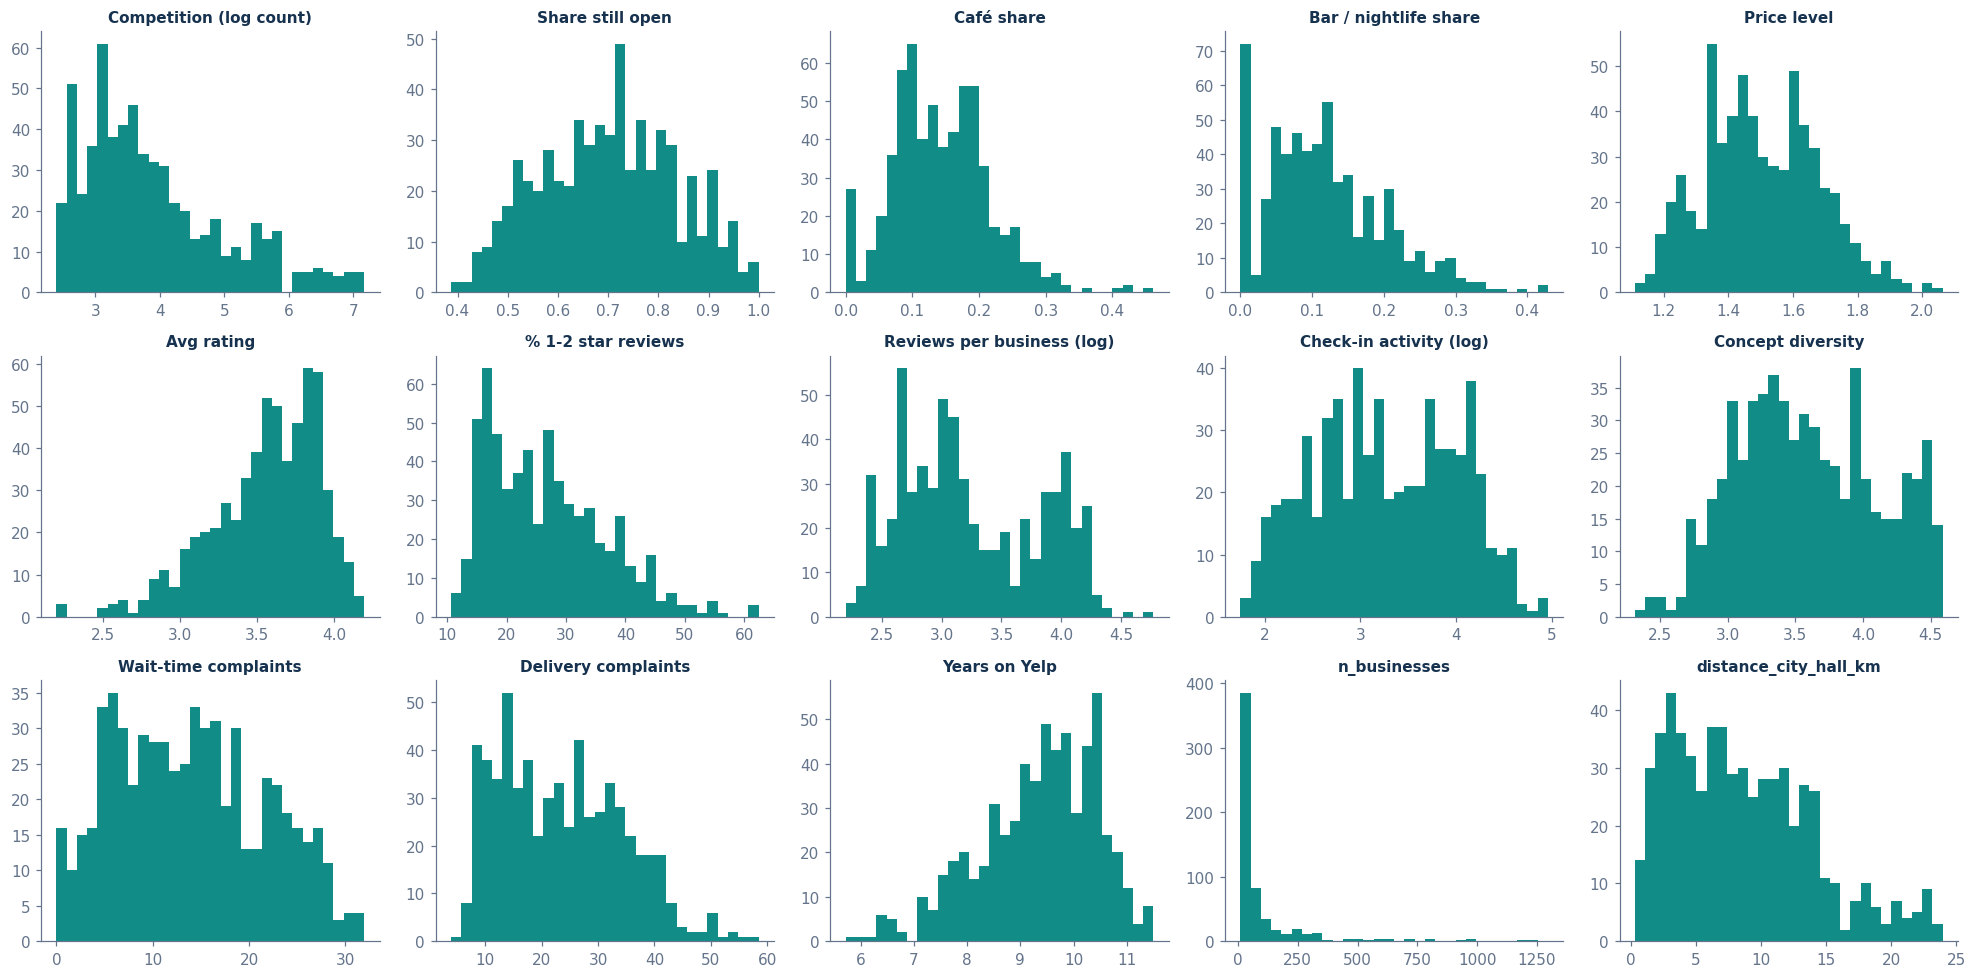

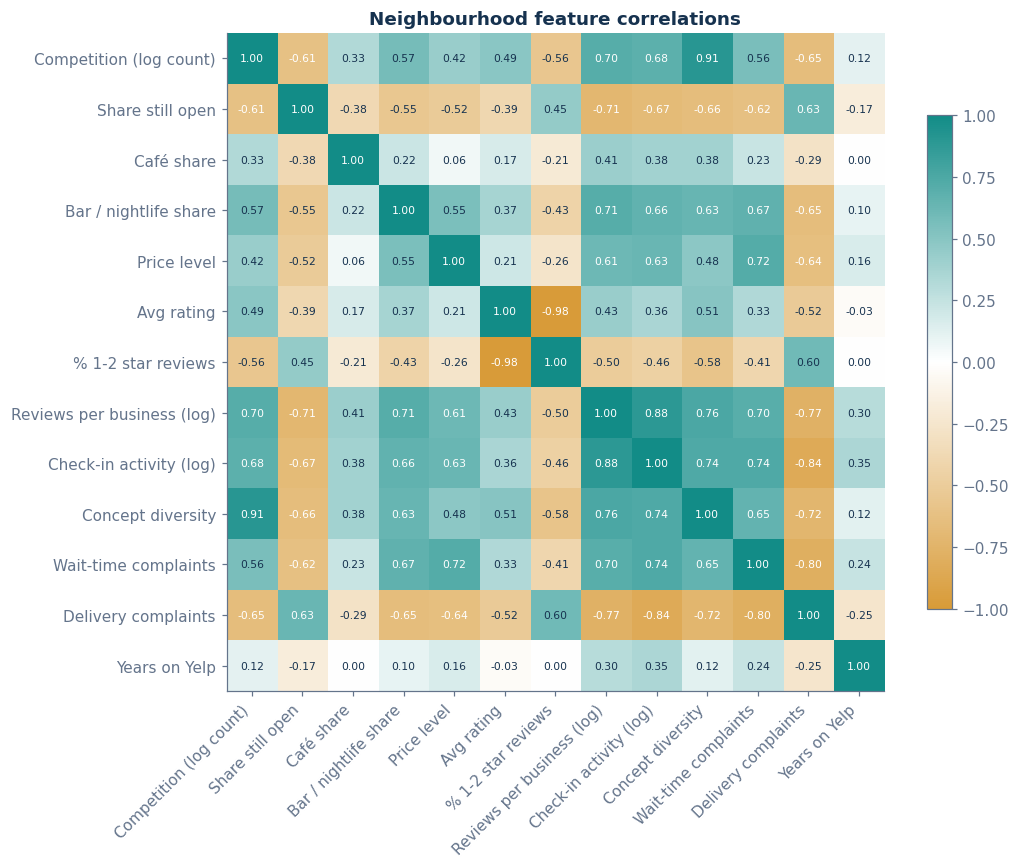

In [28]:
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for axis, feature in zip(axes.ravel(), CLUSTER_FEATURES + ['n_businesses', 'distance_city_hall_km']):
    axis.hist(profiles[feature].dropna(), bins=30, color=THEME['teal'])
    axis.set_title(FEATURE_LABELS.get(feature, feature), fontsize=10)
    axis.grid(False)
save(fig, 'feature_distributions')

corr = profiles[CLUSTER_FEATURES].corr()
fig, ax = plt.subplots(figsize=(10, 8))
cmap = LinearSegmentedColormap.from_list('div', [THEME['gold'], '#FFFFFF', THEME['teal']])
heat = ax.imshow(corr, cmap=cmap, vmin=-1, vmax=1)
labels = [FEATURE_LABELS[f] for f in CLUSTER_FEATURES]
ax.set_xticks(range(len(labels)), labels, rotation=45, ha='right'); ax.set_yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{corr.iloc[i, j]:.2f}', ha='center', va='center', fontsize=7,
                color='white' if abs(corr.iloc[i, j]) > .6 else THEME['navy'])
ax.grid(False); ax.set_title('Neighbourhood feature correlations')
fig.colorbar(heat, ax=ax, shrink=.75)
save(fig, 'feature_correlations')

**What to notice.** Competition, check-in activity and reviews per business rise together towards Center City, so demand and competition are partly the same signal: busy areas are crowded. Survival (`open_share`) and rating carry different information, which is why the clusters are not simply "near / far from downtown". Features are on very different scales (shares, stars, logs), so they are standardised before clustering; otherwise the largest-scale feature would dominate the distances.

## M3-4. Choosing the clustering method and the number of clusters
Pipeline: median imputation → `StandardScaler` → clustering. For k = 2…10 we compare three algorithms on the same scaled data:

* **K-Means** – spherical clusters around centroids; fast and can assign new points (`predict`), which the app needs.
* **Agglomerative (Ward)** – hierarchical merging that minimises within-cluster variance; a check that the structure is not a K-Means artefact.
* **Gaussian Mixture** – soft, elliptical clusters; a check on cluster shape.

Metrics: **silhouette** (−1…1, higher = better separated), **Davies-Bouldin** (lower = better), **Calinski-Harabasz** (higher = better) and the K-Means **elbow** (inertia). A partition is also only useful if it is **stable**: we refit K-Means on 30 bootstrap samples and measure the adjusted Rand index (ARI) against the full-data clustering.

method,Agglomerative (Ward),Gaussian Mixture,K-Means
k,,,
2,0.298,0.330,0.338
3,0.227,0.203,0.241
4,0.172,0.174,0.232
5,0.174,0.155,0.216
6,0.165,0.118,0.177
7,0.172,0.101,0.180
8,0.153,0.117,0.168
9,0.143,0.114,0.174
10,0.147,0.136,0.174


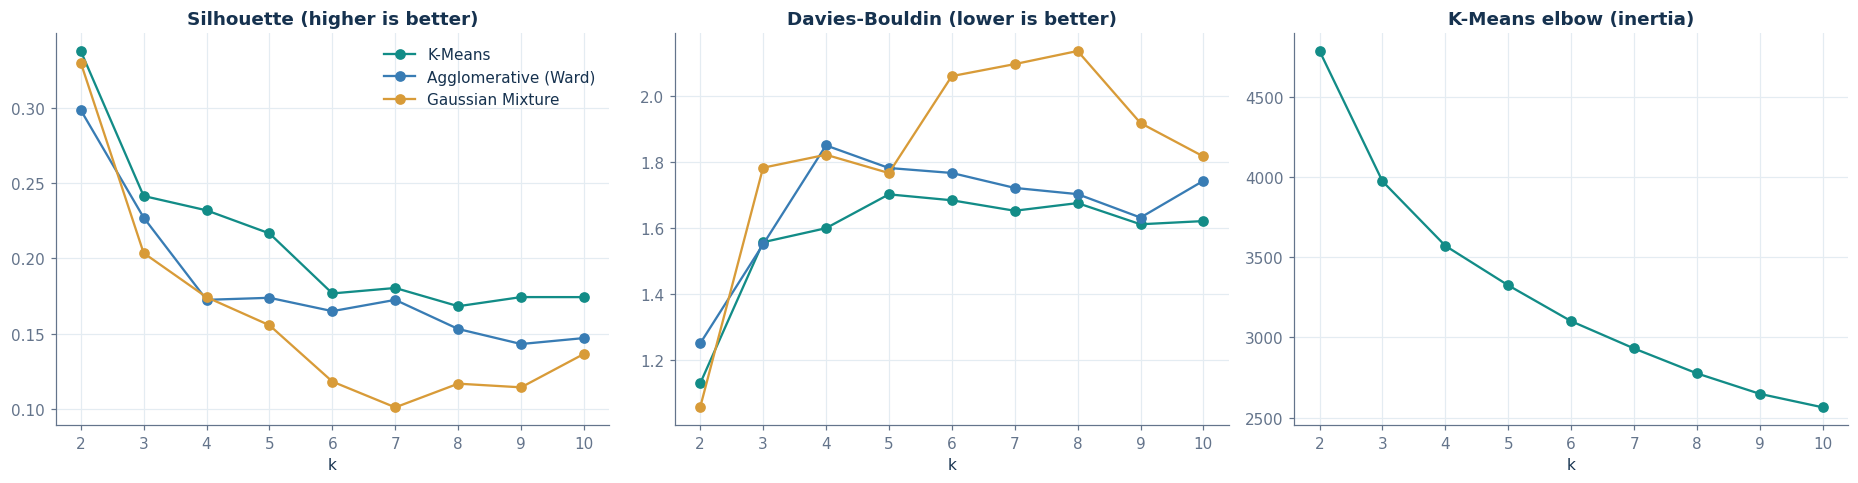

In [29]:
preprocess = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())])
Z = preprocess.fit_transform(profiles[CLUSTER_FEATURES])

rows = []
for k in range(2, 11):
    candidates = {
        'K-Means': KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z),
        'Agglomerative (Ward)': AgglomerativeClustering(n_clusters=k, linkage='ward').fit(Z),
        'Gaussian Mixture': GaussianMixture(n_components=k, covariance_type='full', n_init=3, random_state=SEED).fit(Z),
    }
    for name, model in candidates.items():
        labels = model.labels_ if hasattr(model, 'labels_') else model.predict(Z)
        rows.append({'method': name, 'k': k, 'silhouette': silhouette_score(Z, labels),
                     'davies_bouldin': davies_bouldin_score(Z, labels),
                     'calinski_harabasz': calinski_harabasz_score(Z, labels),
                     'inertia': candidates['K-Means'].inertia_ if name == 'K-Means' else np.nan,
                     'smallest_cluster_pct': np.bincount(labels).min() / len(labels) * 100})
selection = pd.DataFrame(rows)
display(selection.pivot(index='k', columns='method', values='silhouette').round(3))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for name, color in zip(['K-Means', 'Agglomerative (Ward)', 'Gaussian Mixture'], [THEME['teal'], THEME['blue'], THEME['gold']]):
    part = selection[selection['method'] == name]
    axes[0].plot(part['k'], part['silhouette'], marker='o', color=color, label=name)
    axes[1].plot(part['k'], part['davies_bouldin'], marker='o', color=color, label=name)
km = selection[selection['method'] == 'K-Means']
axes[2].plot(km['k'], km['inertia'], marker='o', color=THEME['teal'])
axes[0].set(title='Silhouette (higher is better)', xlabel='k'); axes[0].legend()
axes[1].set(title='Davies-Bouldin (lower is better)', xlabel='k')
axes[2].set(title='K-Means elbow (inertia)', xlabel='k')
save(fig, 'cluster_selection')

In [30]:
def bootstrap_stability(k, n_boot=30):
    reference = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(Z)
    rng = np.random.default_rng(SEED)
    scores = []
    for b in range(n_boot):
        sample = rng.choice(len(Z), len(Z), replace=True)
        refit = KMeans(n_clusters=k, n_init=10, random_state=b).fit(Z[sample])
        scores.append(adjusted_rand_score(reference.labels_, refit.predict(Z)))
    return float(np.mean(scores)), float(np.std(scores))

stability = pd.DataFrame([{'k': k, **dict(zip(['ARI_mean', 'ARI_std'], bootstrap_stability(k)))} for k in range(3, 9)])
kmeans_table = selection[selection['method'] == 'K-Means'].merge(stability, on='k', how='left')
display(kmeans_table[['k', 'silhouette', 'davies_bouldin', 'calinski_harabasz', 'smallest_cluster_pct', 'ARI_mean', 'ARI_std']].round(3))

# Selection rule (fixed before looking at the cluster contents): among k >= 4 — fewer clusters are too coarse
# to describe distinct market environments — keep candidates whose bootstrap ARI >= 0.8 and smallest cluster >= 5%,
# then take the highest silhouette.
eligible = kmeans_table[(kmeans_table['k'] >= 4) & (kmeans_table['ARI_mean'] >= 0.8) & (kmeans_table['smallest_cluster_pct'] >= 5)]
if eligible.empty:
    eligible = kmeans_table[kmeans_table['k'] >= 4]
K = int(eligible.sort_values('silhouette', ascending=False).iloc[0]['k'])
best_by_method = selection[selection['k'] == K].set_index('method')[['silhouette', 'davies_bouldin', 'calinski_harabasz']]
display(best_by_method.round(3))
print('Selected number of clusters:', K)

,k,silhouette,davies_bouldin,calinski_harabasz,smallest_cluster_pct,ARI_mean,ARI_std
0,2,0.338,1.128,401.398,38.625,NaN,NaN
1,3,0.241,1.557,303.552,27.660,0.933,0.049
2,4,0.232,1.600,247.635,13.912,0.867,0.094
3,5,0.216,1.702,210.424,12.930,0.697,0.179
4,6,0.177,1.684,188.910,12.766,0.709,0.141
5,7,0.180,1.653,172.143,5.401,0.649,0.120
6,8,0.168,1.676,160.387,5.237,0.624,0.108
7,9,0.174,1.612,150.493,4.910,NaN,NaN
8,10,0.174,1.621,140.134,4.255,NaN,NaN


,silhouette,davies_bouldin,calinski_harabasz
method,,,
K-Means,0.232,1.600,247.635
Agglomerative (Ward),0.172,1.851,217.772
Gaussian Mixture,0.174,1.823,203.418


Selected number of clusters: 4


**Method choice.** k = 2 has the highest silhouette, but it only separates downtown from everything else, which is too coarse to describe market environments; the rule therefore requires k ≥ 4 (fixed before looking at cluster contents). At k = 4, **K-Means beats both alternatives** on silhouette (0.23 vs 0.17), Davies-Bouldin and Calinski-Harabasz, keeps a bootstrap ARI of about 0.87 (stable), and, unlike Agglomerative clustering, can assign a brand-new proposed location with `predict`, which the app needs. Silhouette values around 0.2–0.3 are typical for real neighbourhood data where areas blend into each other: the clusters describe *tendencies*, not hard borders.

## M3-5. Final clustering and interpretation

K-Means vs Ward agreement (ARI): 0.489


,areas,businesses_median,km_from_city_hall,log_businesses,open_share,cafe_share,nightlife_share,avg_price,weighted_rating,negative_pct,log_median_reviews,checkin_activity,concept_diversity,wait_complaint_share,delivery_complaint_share,maturity_years
cluster,,,,,,,,,,,,,,,,
0,168,42.0,10.78,3.75,0.72,0.14,0.09,1.42,3.71,23.11,3.04,3.08,3.57,11.49,23.89,9.30
1,168,209.5,2.78,5.28,0.56,0.19,0.20,1.64,3.84,17.47,3.99,4.05,4.22,21.31,12.32,9.50
2,190,20.0,8.09,3.06,0.82,0.11,0.06,1.39,3.29,34.95,2.69,2.47,3.10,7.08,36.14,8.95
3,85,30.0,13.39,3.34,0.69,0.13,0.13,1.64,3.29,33.28,3.41,3.83,3.50,19.61,16.82,10.05


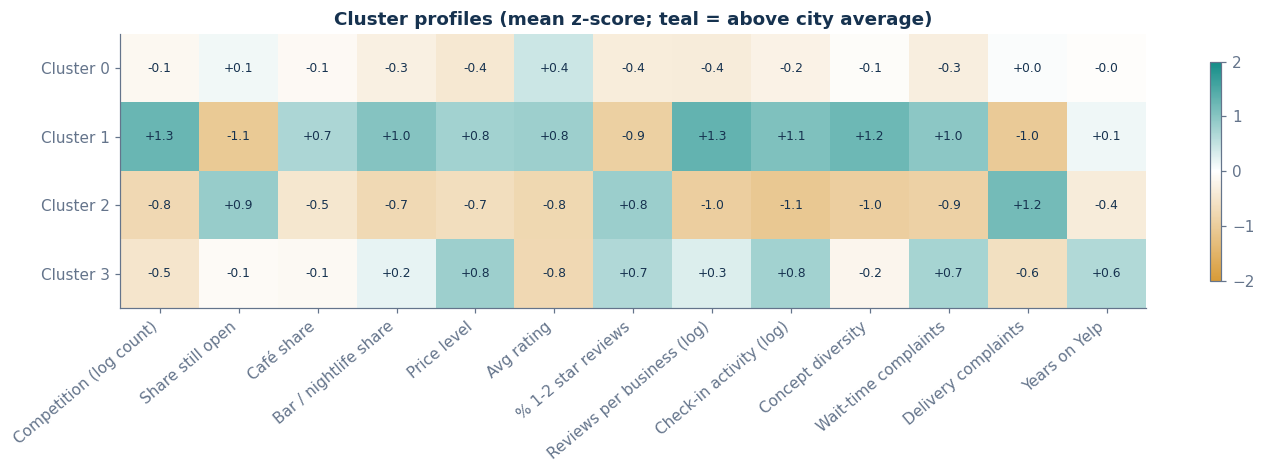

In [31]:
cluster_model = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler()),
                          ('kmeans', KMeans(n_clusters=K, n_init=50, random_state=SEED))])
profiles['cluster'] = cluster_model.fit_predict(profiles[CLUSTER_FEATURES])
ward_labels = AgglomerativeClustering(n_clusters=K, linkage='ward').fit_predict(cluster_model[:-1].transform(profiles[CLUSTER_FEATURES]))
print(f'K-Means vs Ward agreement (ARI): {adjusted_rand_score(profiles["cluster"], ward_labels):.3f}')

summary = profiles.groupby('cluster').agg(areas=('cluster', 'size'), businesses_median=('n_businesses', 'median'),
                                          km_from_city_hall=('distance_city_hall_km', 'median'),
                                          **{f: (f, 'mean') for f in CLUSTER_FEATURES})
zscores = pd.DataFrame(cluster_model[:-1].transform(profiles[CLUSTER_FEATURES]), columns=CLUSTER_FEATURES).groupby(profiles['cluster']).mean()
display(summary.round(2))

fig, ax = plt.subplots(figsize=(13, 0.6 * K + 2))
heat = ax.imshow(zscores, cmap=LinearSegmentedColormap.from_list('div', [THEME['gold'], '#FFFFFF', THEME['teal']]), vmin=-2, vmax=2, aspect='auto')
ax.set_xticks(range(len(CLUSTER_FEATURES)), [FEATURE_LABELS[f] for f in CLUSTER_FEATURES], rotation=40, ha='right')
ax.set_yticks(range(K), [f'Cluster {c}' for c in zscores.index])
for i in range(K):
    for j in range(len(CLUSTER_FEATURES)):
        ax.text(j, i, f'{zscores.iloc[i, j]:+.1f}', ha='center', va='center', fontsize=8)
ax.grid(False); ax.set_title('Cluster profiles (mean z-score; teal = above city average)')
fig.colorbar(heat, ax=ax, shrink=.8)
save(fig, 'cluster_profiles')

In [32]:
def describe_cluster(z, s):
    """Name a cluster from its strongest standardised traits (rules written before naming)."""
    traits = []
    if z['log_businesses'] > 0.8: traits.append('dense')
    elif z['log_businesses'] < -0.8: traits.append('sparse')
    if z['checkin_activity'] > 0.5 or z['log_median_reviews'] > 0.5: traits.append('high-demand')
    elif z['checkin_activity'] < -0.5 and z['log_median_reviews'] < -0.5: traits.append('low-demand')
    if z['open_share'] < -0.5: traits.append('high-turnover')
    if z['weighted_rating'] > 0.5: traits.append('well-rated')
    elif z['weighted_rating'] < -0.5: traits.append('under-served on quality')
    if z['nightlife_share'] > 0.7: traits.append('nightlife')
    if z['cafe_share'] > 0.7: traits.append('café-heavy')
    if z['avg_price'] > 0.7: traits.append('upscale')
    elif z['avg_price'] < -0.7: traits.append('budget')
    return ', '.join(traits[:4]) if traits else 'average mixed area'

auto_names = {c: describe_cluster(zscores.loc[c], summary.loc[c]) for c in summary.index}
for c, name in auto_names.items():
    print(f'Cluster {c} ({summary.loc[c, "areas"]} areas, median {summary.loc[c, "km_from_city_hall"]:.1f} km from City Hall): {name}')

Cluster 0 (168 areas, median 10.8 km from City Hall): average mixed area
Cluster 1 (168 areas, median 2.8 km from City Hall): dense, high-demand, high-turnover, well-rated
Cluster 2 (190 areas, median 8.1 km from City Hall): low-demand, under-served on quality
Cluster 3 (85 areas, median 13.4 km from City Hall): high-demand, under-served on quality, upscale


The names below were written after reading the z-score heatmap, the trait list above and the map. They describe each market environment in business terms; the numbers behind them are in `cluster_summary.csv`.

In [33]:
# One short business-facing name per cluster, derived from the automatic traits above.
def business_name(traits):
    t = set(x.strip() for x in traits.split(','))
    if 'dense' in t and 'high-demand' in t:
        return 'Downtown hub: high demand, intense competition'
    if 'nightlife' in t:
        return 'Nightlife & bar corridor'
    if 'high-demand' in t and 'under-served on quality' in t:
        return 'Busy outer corridor: strong demand, weak competitors'
    if 'high-turnover' in t and ('low-demand' in t or 'under-served on quality' in t):
        return 'Struggling strip: high turnover, weak ratings'
    if 'high-turnover' in t:
        return 'High-turnover area'
    if 'well-rated' in t and 'dense' not in t:
        return 'Neighbourhood favourites: well-rated, moderate competition'
    if 'café-heavy' in t:
        return 'Café & daytime district'
    if 'sparse' in t or 'low-demand' in t:
        return 'Quiet residential: low competition, low activity'
    if 'upscale' in t:
        return 'Upscale dining pocket'
    return 'Mixed neighbourhood market'

CLUSTER_NAMES = {}
for c in summary.index:
    name = business_name(auto_names[c])
    while name in CLUSTER_NAMES.values():   # keep names unique
        name += ' (b)'
    CLUSTER_NAMES[int(c)] = name
profiles['cluster_name'] = profiles['cluster'].map(CLUSTER_NAMES)
summary.insert(0, 'name', summary.index.map(CLUSTER_NAMES))
display(summary[['name', 'areas', 'businesses_median', 'km_from_city_hall', 'weighted_rating', 'negative_pct', 'open_share', 'checkin_activity']].round(2))

,name,areas,businesses_median,km_from_city_hall,weighted_rating,negative_pct,open_share,checkin_activity
cluster,,,,,,,,
0,Mixed neighbourhood market,168,42.0,10.78,3.71,23.11,0.72,3.08
1,"Downtown hub: high demand, intense competition",168,209.5,2.78,3.84,17.47,0.56,4.05
2,"Quiet residential: low competition, low activity",190,20.0,8.09,3.29,34.95,0.82,2.47
3,"Busy outer corridor: strong demand, weak compe...",85,30.0,13.39,3.29,33.28,0.69,3.83


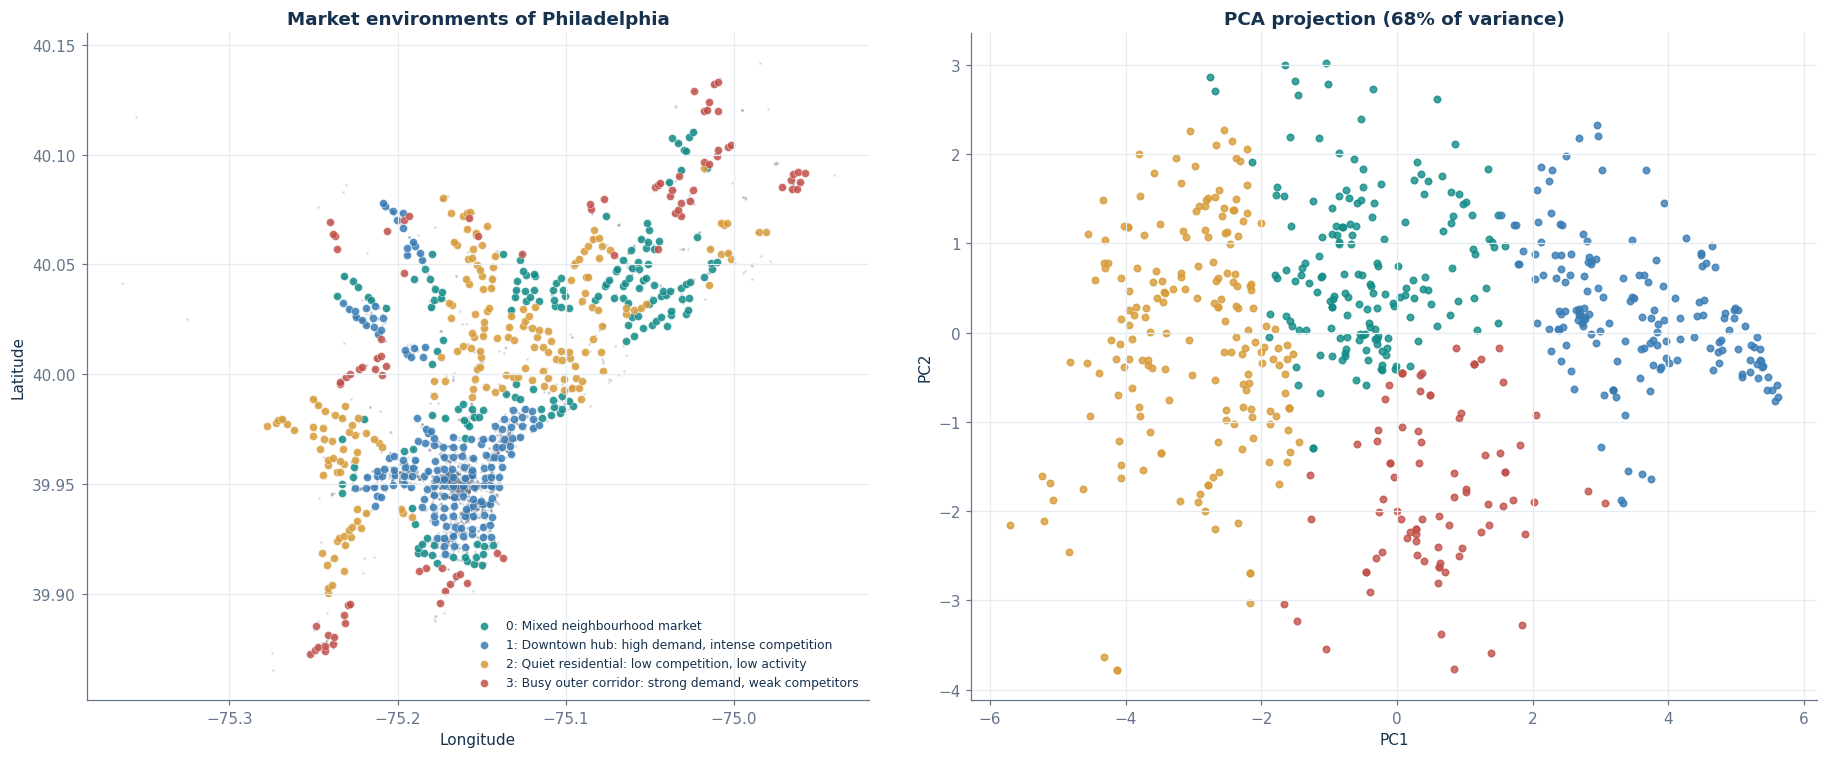

,PC1,PC2
Delivery complaints,-0.33,0.05
Share still open,-0.29,0.05
% 1-2 star reviews,-0.25,-0.53
Years on Yelp,0.09,-0.41
Café share,0.15,0.06
Avg rating,0.22,0.58
Price level,0.25,-0.29
Bar / nightlife share,0.29,-0.07
Competition (log count),0.30,0.11
Wait-time complaints,0.31,-0.21


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
for c in sorted(CLUSTER_NAMES):
    part = profiles[profiles['cluster'] == c]
    axes[0].scatter(part['longitude'], part['latitude'], s=28, color=CLUSTER_COLORS[c % len(CLUSTER_COLORS)],
                    label=f'{c}: {CLUSTER_NAMES[c]}', alpha=.85, edgecolor='white', linewidth=.3)
axes[0].scatter(universe['longitude'], universe['latitude'], s=1, color=THEME['muted'], alpha=.15, zorder=0)
axes[0].set_aspect(1 / np.cos(np.radians(40))); axes[0].set(title='Market environments of Philadelphia', xlabel='Longitude', ylabel='Latitude')
axes[0].legend(fontsize=8, loc='lower right')
pca = PCA(n_components=2, random_state=SEED).fit(cluster_model[:-1].transform(profiles[CLUSTER_FEATURES]))
xy = pca.transform(cluster_model[:-1].transform(profiles[CLUSTER_FEATURES]))
for c in sorted(CLUSTER_NAMES):
    m = profiles['cluster'].to_numpy() == c
    axes[1].scatter(xy[m, 0], xy[m, 1], s=18, color=CLUSTER_COLORS[c % len(CLUSTER_COLORS)], alpha=.8)
axes[1].set(title=f'PCA projection ({pca.explained_variance_ratio_.sum() * 100:.0f}% of variance)', xlabel='PC1', ylabel='PC2')
save(fig, 'cluster_map_pca')
loadings = pd.DataFrame(pca.components_.T, index=[FEATURE_LABELS[f] for f in CLUSTER_FEATURES], columns=['PC1', 'PC2'])
display(loadings.round(2).sort_values('PC1'))

**Interpretation.** The map shows that the market environments follow real Philadelphia geography (Center City core, the corridors around it, outer residential areas) even though coordinates were **not** clustering inputs — the structure comes only from supply, demand, quality and concept-mix features. That is a useful sanity check. PC1 is a busy-vs-quiet axis (competition, check-ins, reviews per business, diversity on one side; survival and delivery complaints on the other). PC2 is a quality axis: rating against the share of 1–2 star reviews. Ward clustering only partly reproduces the K-Means partition (ARI ≈ 0.5), another sign that the boundaries between environments are soft.

### M3-5b. Sensitivity to the neighbourhood radius (enhancement)
The 1 km radius is a design choice. If the market environments are real, re-building every profile with a **0.5 km** or **1.5 km** radius and re-clustering (same k) should give a similar partition. Agreement is measured with the adjusted Rand index against the 1 km clusters (1 = identical, 0 = random).

In [35]:
sensitivity_rows = [{'radius_km': RADIUS_KM, 'ARI_vs_1km': 1.0, 'silhouette': float(best_by_method.loc['K-Means', 'silhouette'])}]
for radius in (0.5, 1.5):
    profiles_r = index.profiles(profiles[['latitude', 'longitude']], radius)
    Z_r = Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]).fit_transform(profiles_r[CLUSTER_FEATURES])
    labels_r = KMeans(n_clusters=K, n_init=20, random_state=SEED).fit_predict(Z_r)
    sensitivity_rows.append({'radius_km': radius, 'ARI_vs_1km': adjusted_rand_score(profiles['cluster'], labels_r),
                             'silhouette': silhouette_score(Z_r, labels_r)})
sensitivity = pd.DataFrame(sensitivity_rows).sort_values('radius_km')
display(sensitivity.round(3))
sensitivity.to_csv(MEMBER3_DIR / 'radius_sensitivity.csv', index=False)

,radius_km,ARI_vs_1km,silhouette
1,0.5,0.295,0.159
0,1.0,1.000,0.232
2,1.5,0.603,0.274


**What to notice — radius.** At 1.5 km the partition largely survives (ARI ≈ 0.6, and silhouette even rises), so the market environments are real structure at the neighbourhood scale. At 0.5 km agreement drops (ARI ≈ 0.3): such small circles contain few businesses, so their averages are noisy and the clusters fragment. This supports the 1 km choice (fixed in advance), and it is also why the app always profiles a location at 1 km for clustering, whatever analysis radius the user picks for competitor lists.

## M3-6. Opportunity and risk scores
Each location gets percentile scores against all neighbourhood profiles (0–100):

* **Demand** = mean percentile of check-in activity and reviews per business.
* **Dissatisfaction** = percentile of the 1–2 star review share (unhappy customers are an opening for a better competitor).
* **Quality gap** = 100 − percentile of the weighted rating.
* **Competition** = percentile of the number of businesses; **Closure** = 100 − percentile of the share still open.

`Opportunity = 0.5·Demand + 0.25·Dissatisfaction + 0.25·Quality gap`, `Market risk = 0.5·Competition + 0.5·Closure`. The weights are a transparent rule stated in `recommend.py`, not a fitted model — Yelp contains no revenue or failure outcome that could be used to learn them honestly.

,opportunity,market_risk,demand,competition,closure
cluster_name,,,,,
"Busy outer corridor: strong demand, weak competitors",69.0,44.2,66.7,36.9,51.5
"Downtown hub: high demand, intense competition",52.3,82.3,83.2,83.3,81.3
"Quiet residential: low competition, low activity",46.8,25.0,19.6,25.2,24.8
Mixed neighbourhood market,41.7,48.9,42.7,51.4,46.4


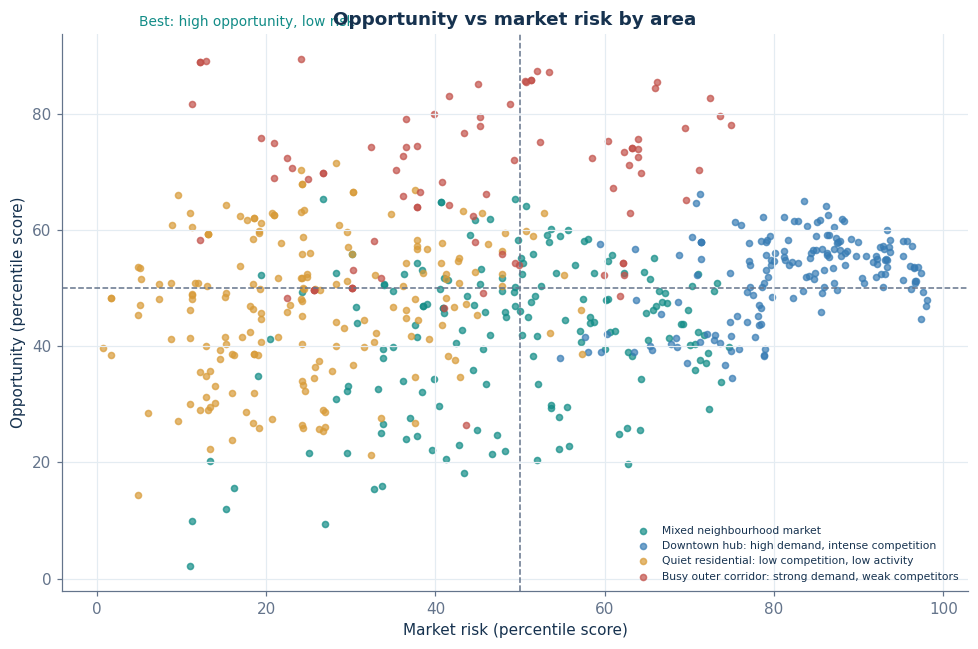

In [36]:
scored = recommend.score_reference(profiles)
profiles[['opportunity', 'market_risk', 'demand', 'competition', 'closure']] = scored[['opportunity', 'market_risk', 'demand', 'competition', 'closure']]
cluster_scores = profiles.groupby('cluster_name')[['opportunity', 'market_risk', 'demand', 'competition', 'closure']].mean().round(1)
display(cluster_scores.sort_values('opportunity', ascending=False))

fig, ax = plt.subplots(figsize=(9, 6))
for c in sorted(CLUSTER_NAMES):
    part = profiles[profiles['cluster'] == c]
    ax.scatter(part['market_risk'], part['opportunity'], s=16, alpha=.7, color=CLUSTER_COLORS[c % len(CLUSTER_COLORS)], label=CLUSTER_NAMES[c])
ax.axhline(50, color=THEME['muted'], ls='--', lw=1); ax.axvline(50, color=THEME['muted'], ls='--', lw=1)
ax.set(xlabel='Market risk (percentile score)', ylabel='Opportunity (percentile score)', title='Opportunity vs market risk by area')
ax.text(5, 95, 'Best: high opportunity, low risk', fontsize=9, color=THEME['teal'])
ax.legend(fontsize=7, loc='lower right')
save(fig, 'opportunity_risk')

### M3-6b. Back-test: do the scores relate to survival? (enhancement)
The opportunity and risk weights are rules, so we check them against an outcome they were not built from: **did restaurants and cafés that entered the market survive?**

* **Entrants:** businesses whose first check-in falls between 2012 and 2019 (at least two years before the January 2022 snapshot).
* For each entrant the area profile is rebuilt **without the entrant itself**, then scored exactly as the app scores a proposed location.
* Outcome: `is_open` at the snapshot. We compare closure rates across score tertiles and compute ROC AUC.

**Honest caveat:** the profile uses snapshot data, so other businesses' closures may post-date the entrant's opening. That look-ahead mainly affects the *closure* component, so we also report the **demand** score alone, which contains no closure information.

2,803 entrants analysed; 37.9% had closed by the snapshot.


,ROC AUC for predicting closure
market_risk,0.599
closure,0.599
competition,0.584
opportunity,0.479
demand,0.414


,entrants,closure_rate
market_risk_tertile,,
low risk,937,27.4
medium risk,936,41.0
high risk,930,45.2


,entrants,closure_rate
demand_tertile,,
low demand,934,28.2
medium demand,936,42.9
high demand,933,42.4


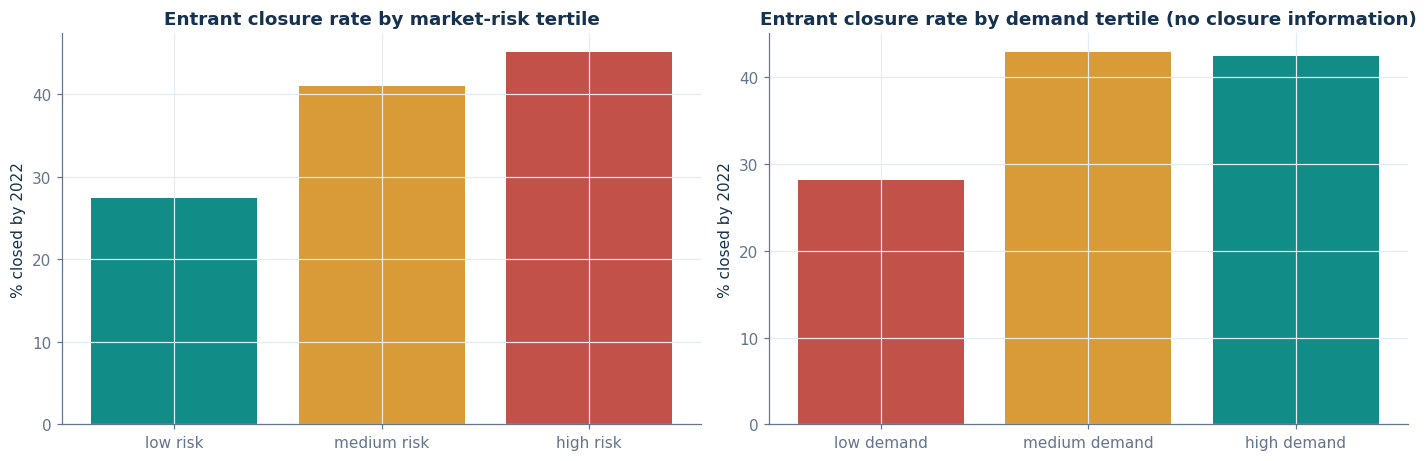

In [37]:
from sklearn.metrics import roc_auc_score

entrant_mask = universe['years_on_yelp'].between(2.0, (snapshot - pd.Timestamp('2012-01-01')).days / 365.25)
entrants = index.universe[entrant_mask.to_numpy()]
neighbourhoods = index.neighbours(entrants['latitude'], entrants['longitude'], RADIUS_KM)
backtest_rows = []
for position, idx in zip(entrants.index, neighbourhoods):
    others = idx[idx != position]                          # leave the entrant out of its own area profile
    if len(others) < MIN_BUSINESSES:
        continue
    p = pd.Series(index.profile_from_indices(others))
    s = recommend.location_scores(p, profiles)
    backtest_rows.append({'business_id': index.universe.at[position, 'business_id'], 'closed': 1 - index.universe.at[position, 'is_open'],
                          'opportunity': s['opportunity'], 'market_risk': s['market_risk'], 'demand': s['demand'],
                          'competition': s['competition'], 'closure': s['closure']})
backtest = pd.DataFrame(backtest_rows)
print(f'{len(backtest):,} entrants analysed; {backtest["closed"].mean() * 100:.1f}% had closed by the snapshot.')

auc = pd.Series({score: roc_auc_score(backtest['closed'], backtest[score] * (1 if score in ('market_risk', 'competition', 'closure') else -1))
                 for score in ['market_risk', 'closure', 'competition', 'opportunity', 'demand']}, name='ROC AUC for predicting closure')
display(auc.round(3).to_frame())
backtest['market_risk_tertile'] = pd.qcut(backtest['market_risk'], 3, labels=['low risk', 'medium risk', 'high risk'])
backtest['demand_tertile'] = pd.qcut(backtest['demand'], 3, labels=['low demand', 'medium demand', 'high demand'])
by_risk = backtest.groupby('market_risk_tertile', observed=True)['closed'].agg(entrants='size', closure_rate='mean')
by_demand = backtest.groupby('demand_tertile', observed=True)['closed'].agg(entrants='size', closure_rate='mean')
display(by_risk.assign(closure_rate=lambda d: d['closure_rate'] * 100).round(1))
display(by_demand.assign(closure_rate=lambda d: d['closure_rate'] * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].bar(by_risk.index.astype(str), by_risk['closure_rate'] * 100, color=[THEME['teal'], THEME['gold'], THEME['red']])
axes[0].set(title='Entrant closure rate by market-risk tertile', ylabel='% closed by 2022')
axes[1].bar(by_demand.index.astype(str), by_demand['closure_rate'] * 100, color=[THEME['red'], THEME['gold'], THEME['teal']])
axes[1].set(title='Entrant closure rate by demand tertile (no closure information)', ylabel='% closed by 2022')
save(fig, 'survival_backtest')
backtest.to_csv(MEMBER3_DIR / 'survival_backtest.csv', index=False)

**What the back-test shows.**
* **The risk score works.** Among 2,803 entrants, the closure rate rises from about 27% in the low-risk tertile to about 45% in the high-risk tertile (ROC AUC ≈ 0.60). This is modest but real for a single area-level score that knows nothing about the business itself.
* **Demand is not survival.** Entrants in high-*demand* areas closed **more** often (AUC below 0.5), because busy areas attract more competitors and more churn. The opportunity score therefore measures *market size*, not the chance of survival, and the recommendation must weigh it against risk. That is how `recommend.verdict` combines them: *Promising* requires both an above-average opportunity **and** a manageable overall risk.
* **Caveat:** the closure component uses snapshot data (some look-ahead), so AUC 0.60 is an optimistic upper bound for that component. The demand result has no such leakage.

## M3-7. Financial simulator
Yelp has **no revenue, rent or cost data**, so the simulator is assumption-driven and transparent. The data only informs defaults: the local price level sets a starting ticket size and the local demand index (check-in activity relative to the city median) can scale traffic.

* Monthly model: revenue = customers/day × ramp-up × open days × average ticket; variable costs = food cost % + card/platform fees; fixed costs = labour + rent + other + marketing; tax only on positive profit.
* **Break-even** customers/day = fixed costs ÷ (ticket × (1 − variable cost %)) ÷ open days.
* **Scenarios:** pessimistic (−25% traffic and +3 pts food cost), base, optimistic (+20% traffic).
* **Data-informed traffic:** the location's demand percentile (activity *per business*, so competition is already shared out) maps to a bounded 0.6×–1.4× multiplier on the concept's default traffic.
* **Monte Carlo:** 4,000 draws of traffic (log-normal, CV 25%), ticket (±10%) and food cost (±3 pts) → probability of payback within 24 months and the distribution of cash after 36 months.

,base assumption
customers_per_day,120.0
avg_ticket,28.0
open_days_per_month,28.0
food_cost_pct,30.0
labor_cost_month,22000.0
rent_month,7000.0
other_fixed_month,4000.0
marketing_month,1500.0
card_and_platform_fees_pct,3.0
initial_investment,250000.0


scenario,Pessimistic,Base,Optimistic
customers_per_day,90.0,120.0,144.0
steady_monthly_revenue,70560.0,94080.0,112896.0
steady_monthly_net_profit,8420.1,22541.5,32500.9
steady_net_margin_pct,11.9,24.0,28.8
year1_revenue,751464.0,1001952.0,1202342.4
year1_net_profit,49353.1,203273.2,309339.8
break_even_customers_per_day,68.8,65.7,65.7
payback_month,36.0,15.0,11.0
cash_at_horizon,1436.3,494270.2,839360.3
roi_at_horizon_pct,0.6,197.7,335.7


,Monte Carlo
prob_payback_within_horizon,0.862
prob_payback_within_24m,0.746
prob_steady_state_loss,0.020
cash_at_horizon_p10,-64397.542
cash_at_horizon_p50,426985.807
cash_at_horizon_p90,1130949.981
median_payback_month,14.000
horizon_months,36.000


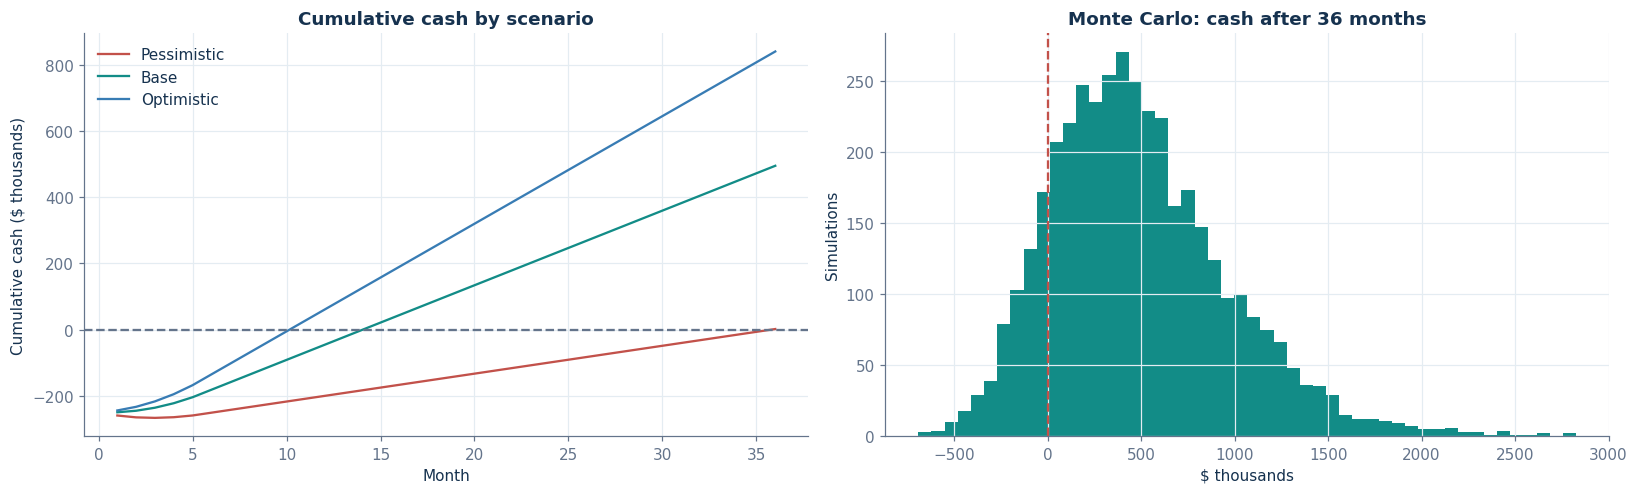

Break-even: 66 customers/day; P(payback within 24 months) = 75%


In [38]:
example = finance.default_assumptions('Restaurant', price_level=2)
display(pd.Series(finance.as_dict(example)).to_frame('base assumption'))
display(pd.DataFrame(finance.scenarios(example)).T.round(1))
projection = finance.monthly_projection(example)
sim = finance.monte_carlo(example, n=4000, seed=SEED)
risk = finance.risk_summary(sim, example)
display(pd.Series(risk).round(3).to_frame('Monte Carlo'))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for name, case, color in [('Pessimistic', 0.75, THEME['red']), ('Base', 1.0, THEME['teal']), ('Optimistic', 1.2, THEME['blue'])]:
    from dataclasses import replace
    a = replace(example, customers_per_day=example.customers_per_day * case, food_cost_pct=example.food_cost_pct + (3 if case < 1 else 0))
    axes[0].plot(finance.monthly_projection(a)['month'], finance.monthly_projection(a)['cumulative_cash'] / 1000, color=color, label=name)
axes[0].axhline(0, color=THEME['muted'], ls='--')
axes[0].set(title='Cumulative cash by scenario', xlabel='Month', ylabel='Cumulative cash ($ thousands)'); axes[0].legend()
axes[1].hist(sim['cash_at_horizon'] / 1000, bins=50, color=THEME['teal'])
axes[1].axvline(0, color=THEME['red'], ls='--')
axes[1].set(title=f'Monte Carlo: cash after {example.horizon_months} months', xlabel='$ thousands', ylabel='Simulations')
save(fig, 'finance_example')
print(f"Break-even: {finance.break_even_customers_per_day(example):.0f} customers/day; "
      f"P(payback within 24 months) = {risk['prob_payback_within_24m']:.0%}")

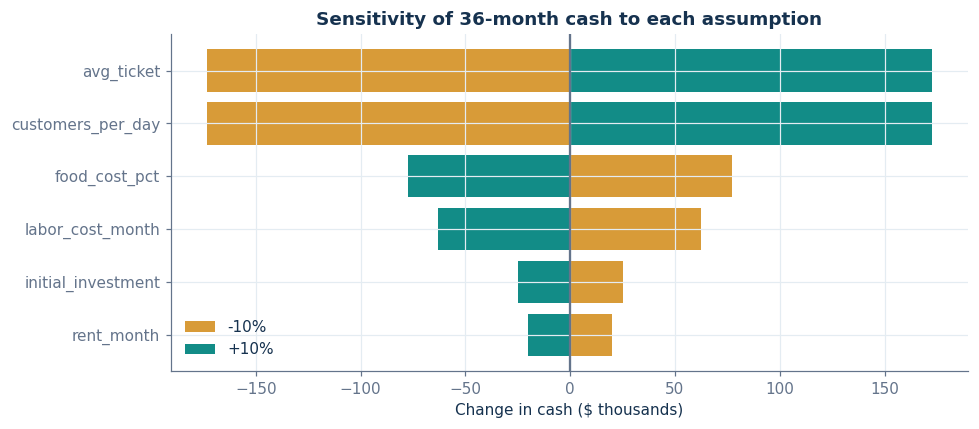

In [39]:
# Sensitivity: which assumption moves 36-month cash the most? (+/-10% on each input, others fixed)
from dataclasses import replace
base_cash = finance.summarize(example)['cash_at_horizon']
rows = []
for field in ['customers_per_day', 'avg_ticket', 'food_cost_pct', 'labor_cost_month', 'rent_month', 'initial_investment']:
    value = getattr(example, field)
    low = finance.summarize(replace(example, **{field: value * 0.9}))['cash_at_horizon'] - base_cash
    high = finance.summarize(replace(example, **{field: value * 1.1}))['cash_at_horizon'] - base_cash
    rows.append({'assumption': field, 'minus_10pct': low, 'plus_10pct': high, 'swing': abs(high - low)})
tornado = pd.DataFrame(rows).sort_values('swing')
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tornado['assumption'], tornado['minus_10pct'] / 1000, color=THEME['gold'], label='-10%')
ax.barh(tornado['assumption'], tornado['plus_10pct'] / 1000, color=THEME['teal'], label='+10%')
ax.axvline(0, color=THEME['muted'])
ax.set(title='Sensitivity of 36-month cash to each assumption', xlabel='Change in cash ($ thousands)'); ax.legend()
save(fig, 'finance_sensitivity')

**What to notice.** Traffic and ticket size dominate the outcome; rent matters less than owners usually expect, labour more. This is why the recommendation compares the assumed traffic with the break-even level and why the app lets the user scale traffic by the local demand index rather than typing a number with no reference.

## M3-8. Launch recommendation for example locations
`recommend.build_report` combines everything for a proposed point: the location profile and cluster, Member 2's competitor review analysis and complaint themes, under-represented concepts, the Member 1 popularity what-if estimate, and the Monte Carlo risk. Below: three contrasting Philadelphia locations for a mid-price restaurant.

In [40]:
popularity_model = PopularityModel(joblib.load(MEMBER1_DIR / 'member1_model.joblib'))
nlp_summary = pd.read_csv(MEMBER2_DIR / 'philadelphia_business_nlp_summary.csv')

def launch_report(name, lat, lon, concept='Restaurant', price=2):
    profile = index.profile(lat, lon, RADIUS_KM)
    cluster = int(cluster_model.predict(profile[CLUSTER_FEATURES].to_frame().T.astype(float))[0])
    comp = analyze_location(lat, lon, RADIUS_KM, nlp_summary, topics_by_business, open_only=True)
    gaps = index.concept_gaps(lat, lon, RADIUS_KM)
    multiplier = finance.traffic_multiplier(recommend.location_scores(profile, profiles)['demand'])
    assumptions = finance.default_assumptions(concept, price, multiplier)
    sim_risk = finance.risk_summary(finance.monte_carlo(assumptions, seed=SEED), assumptions)
    popularity = popularity_model.estimate(lat=lat, lon=lon, stars=3.8, price_range=price, categories=['American (New)'],
                                           attributes={'RestaurantsTakeOut': True, 'RestaurantsReservations': True})
    report = recommend.build_report(lat, lon, profile, CLUSTER_NAMES[cluster], profiles, comp, gaps, assumptions,
                                    sim_risk, popularity, concept)
    print(f'=== {name}: {report["verdict"]} — {report["cluster"]}')
    print(f"Opportunity {report['scores']['opportunity']:.0f} | market risk {report['scores']['market_risk']:.0f} | "
          f"financial risk {report['financial_risk']:.0f} | overall risk {report['overall_risk']:.0f} | traffic x{multiplier:.2f} -> {assumptions.customers_per_day:.0f}/day")
    for title in ['strengths', 'risks', 'actions']:
        for line in report[title]:
            print(f'  [{title[:-1]}] {line}')
    if len(report['alternatives']):
        display(report['alternatives'].round(2))
    return report

reports = {name: launch_report(name, *coords) for name, coords in {
    'Center City (City Hall)': (39.9526, -75.1636),
    'East Passyunk': (39.9290, -75.1652),
    'Northeast Philadelphia (Frankford Ave)': (40.0450, -75.0600)}.items()}

=== Center City (City Hall): Proceed with caution — Downtown hub: high demand, intense competition
Opportunity 55 | market risk 94 | financial risk 4 | overall risk 58 | traffic x1.38 -> 165/day
  [strength] Customer activity is high: demand score 97/100 (check-ins and reviews per business above most of the city).
  [strength] Assumed traffic is 152% above the break-even level (66 customers/day).
  [strength] Member 1 model: a comparable restaurant here would collect about 110 Yelp reviews in 3 years (a popularity proxy).
  [risk] Very dense competition: 1335 restaurants/cafés within 1 km (more than 100% of Philadelphia areas). A clear differentiator is required.
  [risk] Only 53% of businesses here are still open (closure pressure 88/100).
  [risk] Already concentrated here: Sushi Bars, Japanese.
  [action] 'Wait times & table service' makes up 28% of nearby complaints vs 21% citywide: design operations to beat competitors on this point.
  [action] 'Food taste & quality' makes up 25% 

,latitude,longitude,distance_km,cluster_name,opportunity,market_risk,n_businesses
0,39.98,-75.16,2.95,Mixed neighbourhood market,49.45,66.37,121
1,39.97,-75.18,2.99,"Downtown hub: high demand, intense competition",52.31,70.95,59
2,39.98,-75.16,2.81,Mixed neighbourhood market,46.97,66.04,126


=== East Passyunk: Proceed with caution — Downtown hub: high demand, intense competition
Opportunity 55 | market risk 80 | financial risk 7 | overall risk 51 | traffic x1.25 -> 150/day
  [strength] Customer activity is high: demand score 81/100 (check-ins and reviews per business above most of the city).
  [strength] Assumed traffic is 128% above the break-even level (66 customers/day).
  [strength] Member 1 model: a comparable restaurant here would collect about 127 Yelp reviews in 3 years (a popularity proxy).
  [risk] Very dense competition: 306 restaurants/cafés within 1 km (more than 92% of Philadelphia areas). A clear differentiator is required.
  [risk] Only 64% of businesses here are still open (closure pressure 68/100).
  [risk] Already concentrated here: Mexican, Italian, Bakeries.
  [action] 'Cheesesteaks & sandwiches' makes up 44% of nearby complaints vs 12% citywide: design operations to beat competitors on this point.
  [action] Under-represented concepts with solid cityw

,latitude,longitude,distance_km,cluster_name,opportunity,market_risk,n_businesses
0,39.90,-75.16,2.73,"Busy outer corridor: strong demand, weak compe...",70.56,23.08,26
1,39.91,-75.19,2.79,"Busy outer corridor: strong demand, weak compe...",58.27,12.15,14
2,39.90,-75.17,2.74,"Busy outer corridor: strong demand, weak compe...",68.76,25.00,30


=== Northeast Philadelphia (Frankford Ave): Promising — Mixed neighbourhood market
Opportunity 57 | market risk 65 | financial risk 20 | overall risk 47 | traffic x1.06 -> 127/day
  [strength] Assumed traffic is 93% above the break-even level (66 customers/day).
  [strength] Member 1 model: a comparable restaurant here would collect about 82 Yelp reviews in 3 years (a popularity proxy).
  [risk] Dense competition: 83 restaurants/cafés within 1 km (more than 75% of Philadelphia areas). A clear differentiator is required.
  [risk] Already concentrated here: Japanese, Chinese, Chicken Wings.
  [action] 'Orders, delivery & phone' makes up 28% of nearby complaints vs 14% citywide: design operations to beat competitors on this point.
  [action] Under-represented concepts with solid citywide demand: Vegetarian, American (New), Desserts.


,latitude,longitude,distance_km,cluster_name,opportunity,market_risk,n_businesses
0,40.04,-75.09,2.38,"Quiet residential: low competition, low activity",63.11,24.10,19
1,40.03,-75.06,1.99,"Quiet residential: low competition, low activity",57.67,21.73,31
2,40.03,-75.06,1.74,"Quiet residential: low competition, low activity",60.86,28.60,34


## M3-9. Exports for the Streamlit app

In [41]:
profiles.to_csv(MEMBER3_DIR / 'neighbourhood_profiles.csv', index=False)
summary.to_csv(MEMBER3_DIR / 'cluster_summary.csv')
selection.to_csv(MEMBER3_DIR / 'cluster_selection_metrics.csv', index=False)
kmeans_table.to_csv(MEMBER3_DIR / 'kmeans_stability.csv', index=False)
joblib.dump({'model': cluster_model, 'features': CLUSTER_FEATURES, 'names': CLUSTER_NAMES, 'k': K,
             'radius_km': RADIUS_KM, 'min_businesses': MIN_BUSINESSES, 'snapshot': str(snapshot.date()),
             'demand_reference_median': float(profiles['checkin_activity'].median())},
            MEMBER3_DIR / 'market_cluster_model.joblib')
(MEMBER3_DIR / 'run_summary.json').write_text(json.dumps({
    'businesses': len(universe), 'neighbourhood_profiles': len(profiles), 'k': K,
    'silhouette': float(best_by_method.loc['K-Means', 'silhouette']),
    'davies_bouldin': float(best_by_method.loc['K-Means', 'davies_bouldin']),
    'bootstrap_ARI': float(kmeans_table.loc[kmeans_table['k'] == K, 'ARI_mean'].iloc[0]),
    'cluster_names': CLUSTER_NAMES, 'example_verdicts': {k: v['verdict'] for k, v in reports.items()}}, indent=2), encoding='utf-8')

# Reload check: the saved model reproduces the in-memory clusters.
saved = joblib.load(MEMBER3_DIR / 'market_cluster_model.joblib')
assert (saved['model'].predict(profiles[CLUSTER_FEATURES]) == profiles['cluster']).all()
print('Saved:', ', '.join(sorted(p.name for p in MEMBER3_DIR.iterdir() if p.is_file())))

Saved: business_universe.csv, cluster_selection_metrics.csv, cluster_summary.csv, kmeans_stability.csv, market_cluster_model.joblib, neighbourhood_profiles.csv, radius_sensitivity.csv, run_summary.json, survival_backtest.csv


## M3-10. Limitations and future work
* **No financial ground truth.** Yelp has no revenue, rent or failure dates; the simulator is a structured what-if tool, and its defaults should be replaced with real quotes (rent, wages) before a decision.
* **Snapshot data.** `is_open`, ratings and check-ins describe January 2022; closure dates are unknown, so "share still open" mixes old and recent closures.
* **Overlapping neighbourhoods.** Profiles use 1 km circles around 0.5 km grid points, so neighbouring areas share businesses; clusters describe tendencies, and the silhouette score is moderate.
* **Rule-based scores.** Opportunity/risk weights are transparent rules. With outcome data (e.g. city business-licence closures) they could be learned and validated.
* **Future work:** add foot-traffic / census income data, use dated reviews to build trend features, validate recommendations against businesses that opened after the snapshot, and add an LLM summary of competitor reviews.

---

# Conclusions

| Question | Answer from the models |
|---|---|
| **Competition** | Part 1 measures competitors within 0.5 / 1 / 2 km. Competition is extreme downtown (1,300+ restaurants and cafés within 1 km of City Hall) and is strongly tied to demand: busy areas are crowded. |
| **Popularity potential** | Location alone explains little (R² 0.06). Business age, listing completeness, price, rating and nearby activity raise it to **R² 0.61** on spatially held-out restaurants. |
| **Customer expectations** | Review text predicts star polarity with macro F1 **0.944**. The six complaint themes show what to get right. For example, wait-time complaints are over-represented in Center City and delivery/phone complaints in the Northeast. |
| **Market environments** | Four stable clusters. *Busy outer corridors* (strong demand, weak-rated competitors) offer the best opportunity/risk balance; *downtown hubs* have the most demand but also the most closures. |
| **Does the risk score mean anything?** | Yes. In a back-test on 2,803 restaurants and cafés that opened in 2012–2019, the closure rate rises from 27% in low-risk areas to 45% in high-risk ones. High-demand areas close *more* often, so demand alone is not a reason to open. |
| **Financial risk** | The simulator converts the owner's assumptions into break-even traffic and a probability of payback. Traffic and ticket size dominate the outcome. |

**Robustness checks.** A 20-configuration random search and a Poisson loss did not beat the selected regression on validation. Conformally calibrated intervals give the app an honest likely range. The clusters survive a change of radius to 1.5 km.

**Model choices in one line each.** The regression uses HistGradientBoosting (best validation MAE after spatial CV, with log target and regularisation). Sentiment uses tuned Logistic Regression (best validation macro F1, with probabilities for the app). Clustering uses K-Means (best silhouette/DB/CH of three methods, stable, and it can score new locations).

**Limitations.** Review counts measure Yelp popularity, not revenue. The data is a single January 2022 snapshot without closure dates. Star-derived sentiment labels miss sarcasm and mixed reviews. Neighbourhood clusters overlap, and the financial figures are assumptions.

**Future work.** Validate recommendations against restaurants opened after 2022 (city licence data). Add census income, rent and foot-traffic data. Fine-tune a transformer for aspect-level sentiment. Deploy the app publicly.